# 20 · Deep learning et premiers pas en PyTorch — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch20_deep_learning/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 20.Q1 à 20.Q12, 20.R1 à 20.R3, 20.1 à 20.4, 20.6, 20.7, 20.9 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 20.13 | Premiers tenseurs PyTorch : créer, convertir, dtype, device | 📦 | ★ | 15 |
|  | 20.14 | Prédire les formes produites par les couches utilitaires | 🔮 | ★ | 15 |
|  | 20.15 | Autograd : retrouver les gradients du réseau minuscule du ch. 18 | 📦 | ★★ | 20 |
|  | 20.16 | dropout_forward et dropout_backward | 🔨 | ★★ | 25 |
|  | 20.17 | layer_norm, l2_penalty et EarlyStopping | 🔨 | ★★ | 30 |
| B | 20.18 | Écrire sa classe nn.Module et compter ses paramètres | 📦 | ★★ | 25 |
|  | 20.19 | Dataset et DataLoader : MNIST en mini-batches | 📦 | ★★ | 25 |
|  | 20.20 | Zoo des couches : convolution, pooling, récurrente, utilitaires, bruit | 📦 | ★★ | 30 |
|  | 20.21 | Reproduire la figure 20.17 : le plan de VGG16 couche par couche | 🎨 | ★★ | 30 |
|  | 20.22 | batchnorm_forward et batchnorm_backward | 🔨 | ★★★ | 75 |
| C | 20.23 | La boucle d'entraînement PyTorch complète sur MNIST | 📦 | ★★★ | 45 |
|  | 20.24 | Chasse aux bugs PyTorch : cinq erreurs classiques | 🐛 | ★★ | 30 |
|  | 20.25 | Courbes train/validation : overfitting, eval() oublié, fuite | 📈 | ★★ | 20 |
|  | 20.26 | Un modèle ImageNet face à des images qu'il n'a jamais vues | 🔮 | ★★ | 25 |
|  | 20.27 | Sauvegarder, recharger et reproduire un entraînement | 🛠️ | ★★ | 25 |
| D | 20.28 | Dropout, batchnorm, AdamW et early stopping sur Fashion-MNIST | 📦 | ★★★ | 60 |
|  | 20.29 | Ablation : qu'est-ce qui retarde l'overfitting ? | 🔬 | ★★★ | 60 |
|  | 20.30 | Un réseau de 30 couches : connexions résiduelles et layer norm | 🔬 | ★★★ | 45 |
|  | 20.31 | Défi Fashion-MNIST : au moins 90 % avec un MLP de 300 k paramètres au plus | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Prévoir la forme d'un tenseur couche après couche, et dimensionner la sortie d'un réseau.
- Calculer à la main un dropout inversé, une batchnorm (entraînement et évaluation) et une layer norm, puis les programmer dans `mylearn.nn.regularization` et les retrouver dans PyTorch.
- Écrire un `nn.Module`, un `DataLoader` et une boucle d'entraînement PyTorch, et mener une ablation de régularisation.

**Rappel express.** Dropout inversé : $\tilde a = a\,m/(1 - p)$, $m \sim \mathrm{Bernoulli}(1 - p)$, un nouveau masque à chaque passe avant, l'identité en évaluation. Batchnorm : $\hat x = (x - \mu_B)/\sqrt{\sigma_B^2 + \epsilon}$ (variance biaisée), $y = \gamma\hat x + \beta$ ; statistiques glissantes $\mu^{\text{run}} \leftarrow (1 - \rho)\,\mu^{\text{run}} + \rho\,\mu_B$ avec $\rho = 0{,}1$ et la variance non biaisée. Layer norm : la même formule, sur les features de chaque exemple. Pénalité L2 : $\frac{\lambda}{2}\sum\lVert\mathbf{W}\rVert^2$, de gradient $\lambda\mathbf{W}$. Boucle PyTorch : `model.train()`, puis pour chaque mini-batch `logits = model(X)`, `loss = loss_fn(logits, y)`, `optimizer.zero_grad()`, `loss.backward()`, `optimizer.step()` ; `model.eval()` et `torch.no_grad()` pour mesurer.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 20.1 à 20.4, 20.6, 20.7 et 🧮 20.9)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme : entre guillemets (`"(3, 5)"`, ou `"(7,)"` pour une seule dimension). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les preuves ∂ 20.5 et 20.8, la réflexion (🗣️ 20.10, ⚖️ 20.11, 📄 20.12) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np

# Ex 20.3: inverted dropout on five activations, keep a neuron when u >= p
A_203 = np.array([2.0, -1.0, 0.5, 3.0, 4.0])
U_203 = np.array([0.1, 0.7, 0.35, 0.9, 0.5])
P_203 = 0.4
MASK_203 = (U_203 >= P_203) / (1 - P_203)
OUT_203 = A_203 * MASK_203

# Ex 20.4: batch normalization of a mini-batch of four examples, eps = 0
X_204 = np.array([[1.0, 10.0], [3.0, 14.0], [5.0, 6.0], [7.0, 10.0]])
GAMMA_204, BETA_204, MOMENTUM_204 = np.array([2.0, 0.5]), np.array([0.0, 1.0]), 0.1
MU_204, VAR_204 = X_204.mean(axis=0), X_204.var(axis=0)                     # biased variance
XHAT_204 = (X_204 - MU_204) / np.sqrt(VAR_204)
Y_204 = GAMMA_204 * XHAT_204 + BETA_204
RUN_MEAN_204 = (1 - MOMENTUM_204) * np.zeros(2) + MOMENTUM_204 * MU_204
RUN_VAR_204 = (1 - MOMENTUM_204) * np.ones(2) + MOMENTUM_204 * X_204.var(axis=0, ddof=1)   # unbiased
EVAL_204 = GAMMA_204 * (np.array([4.0, 12.0]) - RUN_MEAN_204) / np.sqrt(RUN_VAR_204) + BETA_204

# Ex 20.6: the parameters of VGG16
VGG_BLOCKS = [[64, 64], [128, 128], [256, 256, 256], [512, 512, 512], [512, 512, 512]]
VGG_CONV = []
_c_in = 3
for _block in VGG_BLOCKS:
    for _c_out in _block:
        VGG_CONV.append((9 * _c_in + 1) * _c_out)
        _c_in = _c_out
VGG_FC = [25088 * 4096 + 4096, 4096 * 4096 + 4096, 4096 * 1000 + 1000]
VGG_TOTAL = sum(VGG_CONV) + sum(VGG_FC)

# Ex 20.7: layer norm of one example, eps = 0
X_207 = np.array([1.0, 2.0, 3.0, 6.0])
LN_207 = (X_207 - X_207.mean()) / np.sqrt(X_207.var())

# Ex 20.9: training VGG16 on ImageNet
TRAIN_OPS_209 = 3 * 15.5e9                       # forward + backward, per image
TOTAL_OPS_209 = 1.28e6 * 74 * TRAIN_OPS_209

**20.Q1 — Deep learning et machine learning : qui contient qui ?**

In [3]:
wb.record("20.Q1a", True, mistakes={"relis le §20.2 de la fiche : quel est l'usage le plus courant ?": False})
wb.record("20.Q1b", False, mistakes={"le livre signale que certains auteurs réservent « machine learning » aux méthodes sans réseaux": True})
wb.record("20.Q1c", "C", mistakes={"un MLP à deux couches cachées est une pile de couches": "A",
          "un réseau de convolution est un réseau de neurones à plusieurs couches": "B",
          "un réseau récurrent est un réseau de neurones": "D"})
wb.record("20.Q1d", "B", mistakes={"la hiérarchie ne porte pas sur le nombre de neurones, mais sur ce que chaque couche reçoit": "A",
          "rien dans le réseau ne trie les classes par fréquence": "C",
          "les poids ne sont pas triés : qu'est-ce que chaque couche reçoit en entrée ?": "D"})

WB_ANSWER {"hash": "fd4a6e0b0c328fa6a398256f41624e453aa2b859c2487fc3dbdb084d30ac05d9", "id": "20.Q1a", "kind": "bool", "mistakes": {"8cc886e99ec1013d3c0c53d0a96733486019408c5d1f3c1a3eb57e95449af2cb": "relis le §20.2 de la fiche : quel est l'usage le plus courant ?"}}
📝 Ex 20.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "33609730f43e8017ccec22651a0f9dbf43442bf84fd30c59e780371674f70ee1", "id": "20.Q1b", "kind": "bool", "mistakes": {"3bd1caad9ea604b0d4886659d90f9718c7e139084554e222b49bd38338bd91a4": "le livre signale que certains auteurs réservent « machine learning » aux méthodes sans réseaux"}}
📝 Ex 20.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "9f818f04b05ea427e2656521d44b30e9d8d7f12dcd9cc177f87c7324b7a2aa7d", "id": "20.Q1c", "kind": "str", "mistakes": {"0bacb4dcaecda0fd1fa7429b5a695a6de47d5fa71a2af8816d8b1a6bc583f755": "un réseau récurrent est un réseau de neurones", "0cf642830262ce6e793a2237d619a07e49f79fb4f58e995a74fbbc19c0a05ade": "un réseau de convolution est un 

**20.Q2 — Tenseurs : nombre de dimensions, taille, forme**

In [4]:
wb.record("20.Q2a", 4, mistakes={"compte les nombres de la forme, pas les dimensions d'une image": 3,
          "le nombre de dimensions est la longueur de la forme": 32})
wb.record("20.Q2b", 32 * 3 * 28 * 28, mistakes={"le nombre d'éléments est le PRODUIT des tailles": 32 + 3 + 28 + 28,
          "multiplie aussi par le nombre de canaux, 3": 32 * 28 * 28,
          "multiplie aussi par la taille du mini-batch, 32": 3 * 28 * 28})
wb.record("20.Q2c", "(3, 28, 28)", mistakes={"x[0] retire seulement la première dimension, celle des exemples": "(28, 28)",
          "x[0] retire la première dimension : il reste trois nombres": "(32, 3, 28)",
          "x[0] garde les canaux, puis la hauteur et la largeur": "(28, 28, 3)",
          "la bonne forme, mais écris-la comme un tuple, sans torch.Size : (3, 28, 28)": "torch.Size([3, 28, 28])",
          "la bonne forme, mais écris-la entre parenthèses, comme un tuple : (3, 28, 28)": "[3, 28, 28]",
          "c'est le même tuple, mais écris-le sans la virgule finale, comme PyTorch l'affiche : (3, 28, 28)": "(3, 28, 28,)"})
wb.record("20.Q2d", True, mistakes={"relis la définition du livre (§20.2.1) : un tenseur est-il « troué » ?": False})
wb.record("20.Q2e", "B", mistakes={"float64 est le type par défaut de NumPy, pas de PyTorch": "A",
          "1.0 est un réel : un tenseur d'entiers viendrait de torch.tensor([1, 2])": "C",
          "float16 n'est jamais un type par défaut": "D"})

WB_ANSWER {"hash": "e56b7e79e10303d28cb971e3bffc23c0a55de784fc3a2f3eb9ae88e4a8a60bbd", "id": "20.Q2a", "kind": "int", "magnitude": 0, "mistakes": {"01c8adbe4f6faed50ee44fff19c1ac7dc65ae5da47bdfed2d428d61b69ce36c4": "compte les nombres de la forme, pas les dimensions d'une image", "a588e96e5f3e701ae299551f3e17ad3c094fd056de209b56ef1eb43f4660b4b2": "le nombre de dimensions est la longueur de la forme"}, "sign": 1}
📝 Ex 20.Q2a : réponse enregistrée (int).
WB_ANSWER {"hash": "175cad84f02bf746daa4064c4b4e76ee73a9fa560a40ecd8b095f8753d931ed4", "id": "20.Q2b", "kind": "int", "magnitude": 4, "mistakes": {"56b92f5082e4a34bf1156b8bbfb1afbc7790da2561736291a4cefaae47c6ee86": "multiplie aussi par le nombre de canaux, 3", "83fe666e532a82867bd37555313573503df95acf6f1545bc3759edefa5c1af7b": "multiplie aussi par la taille du mini-batch, 32", "fcea31ba8ccb6350fd14b26fc22559519e572a04e65198e1f18b1433e1543002": "le nombre d'éléments est le PRODUIT des tailles"}, "sign": 1}
📝 Ex 20.Q2b : réponse enregistré

**20.Q3 — Couche d'entrée, couche de sortie : laquelle contient des neurones ?**

In [5]:
wb.record("20.Q3a", False, mistakes={"relis le §20.3.1 : la couche d'entrée calcule-t-elle quelque chose ?": True})
wb.record("20.Q3b", True, mistakes={"qui produit les scores de sortie, sinon des neurones ?": False})
wb.record("20.Q3c", 2, mistakes={"la couche d'entrée et la couche de sortie ne sont pas cachées": 4,
          "seules les couches entre l'entrée et la sortie sont cachées : la sortie n'en est pas une": 3,
          "784 → 256 → 128 → 10 : combien de couches entre l'entrée et la sortie ?": 1})
wb.record("20.Q3d", "B", mistakes={"le livre dessine les entrées en bas : où est le haut ?": "A",
          "« plus haute » parle de position dans la pile, pas de taille": "C",
          "toutes les couches sont entraînées en même temps": "D"})

WB_ANSWER {"hash": "f4c3ce4370ea5afec8db2455d4fff434c961141a39d413068cddba68bae0e011", "id": "20.Q3a", "kind": "bool", "mistakes": {"05fe71d7a98f2276d5b34bcc8cc609f52294974bf72b35e2467ded978ad61c67": "relis le §20.3.1 : la couche d'entrée calcule-t-elle quelque chose ?"}}
📝 Ex 20.Q3a : réponse enregistrée (bool).
WB_ANSWER {"hash": "1147381c2738dab9beebad7dabf2512301e1d2d8cb6f8a68173b2bf6045a40d7", "id": "20.Q3b", "kind": "bool", "mistakes": {"235cc11de49d52a1801531b09e33b912d037ac5e61121567c088e2f84534f224": "qui produit les scores de sortie, sinon des neurones ?"}}
📝 Ex 20.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "4571d74d23b04ba8a4bf0b970fe82cd58d9a3f21a62230919bc4797a4b91225d", "id": "20.Q3c", "kind": "int", "magnitude": 0, "mistakes": {"a0d054d96f5142fa0481a0e1a83daf4177731c8cd89d7c5a551cda69ef7c66f4": "la couche d'entrée et la couche de sortie ne sont pas cachées", "a1e3965d4c48802e4c8fdd317c75c4dbcfc108d57aa17016e139a46a1e4e1d10": "784 → 256 → 128 → 10 : combien de c

**20.Q4 — Couche dense et couche d'activation séparée**

In [6]:
wb.record("20.Q4a", 4 * 3, mistakes={"sans les biais : un poids par connexion": 15, "chaque neurone reçoit les 4 sorties": 7})
wb.record("20.Q4b", 4 * 3 + 3, mistakes={"un biais par neurone, pas par entrée": 16, "ajoute les 3 biais": 12})
wb.record("20.Q4c", True, mistakes={"relis le §20.4.2 : une activation dans la couche ou juste après, est-ce différent ?": False})
wb.record("20.Q4d", "B", mistakes={"CrossEntropyLoss applique elle-même log_softmax : une softmax avant serait de trop": "A",
          "la loss a besoin de tous les scores, pas seulement de la classe gagnante": "C",
          "la sigmoïde va avec BCEWithLogitsLoss, et encore : celle-ci la fait elle-même": "D"})

WB_ANSWER {"hash": "1338773e6fe4cb1b8d100d3bfe4758cd4d24b065e3ffbc0fbd07912df2261f5e", "id": "20.Q4a", "kind": "int", "magnitude": 1, "mistakes": {"4992676afe3fa2d8f3dc5bf4f3a24b4cc55e663406733fcbf3ae135acc07c52b": "sans les biais : un poids par connexion", "bbeb98d20a784e9294296bd57cd40b073541245e276cea9b3d739da45a472248": "chaque neurone reçoit les 4 sorties"}, "sign": 1}
📝 Ex 20.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "8365df667364ab3424b08895850a347a1c613a8c33dc33f38c6896fc7dfff9d8", "id": "20.Q4b", "kind": "int", "magnitude": 1, "mistakes": {"73e6852df2f4a07136799ad838ca9499b719dea4bdb7ab4bbc1a7e60b8881781": "ajoute les 3 biais", "f23724b85652d6a231f49b017dfcdf836c257bff6b4ca31b41aab42cc97d5bca": "un biais par neurone, pas par entrée"}, "sign": 1}
📝 Ex 20.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "925538fc586143f30799a3dc8e5c7c1e840e6648e1c9e0877408b02342bed99a", "id": "20.Q4c", "kind": "bool", "mistakes": {"ae669a2458d531e79f2a41630c2df18cefe96845084d52f4ddb

**20.Q5 — Vrai ou faux : le dropout tire ses neurones une fois par epoch**

In [7]:
wb.record("20.Q5a", False, mistakes={"c'est ce que dit le livre ; relis l'encadré « Le livre, corrigé » du §20.4.3": True})
wb.record("20.Q5b", 500, mistakes={"un nouveau masque à chaque passe avant, donc à chaque mini-batch": 1})
wb.record("20.Q5c", 1 / (1 - 0.2), decimals=2, mistakes={"on divise par 1 − p, on ne multiplie pas": 0.8, "on divise par 1 − p, pas par p": 5.0})
wb.record("20.Q5d", "C", mistakes={"en évaluation, le dropout ne coupe plus rien": "A",
          "c'est la règle de l'article d'origine, appliquée aux poids ; le dropout inversé n'a rien à corriger au test": "B",
          "en évaluation, aucun neurone n'est coupé": "D"})

WB_ANSWER {"hash": "96f31816619629aa1dea1a4a63b451408c447ce32cec961abfdcbc757f5e043e", "id": "20.Q5a", "kind": "bool", "mistakes": {"4dc371ce3aa9318485e3c9a02fae9050663ba5c128af47e4b6c5536a45390ef0": "c'est ce que dit le livre ; relis l'encadré « Le livre, corrigé » du §20.4.3"}}
📝 Ex 20.Q5a : réponse enregistrée (bool).
WB_ANSWER {"hash": "0d291898acfb5ef86e5f3c9fefd6c980532e5b64780b70b950a1dec749cef36c", "id": "20.Q5b", "kind": "int", "magnitude": 2, "mistakes": {"017a86a6264ef2062cc951ea4c577b91d75582d5d2f2cc6ee9d677d2213d092c": "un nouveau masque à chaque passe avant, donc à chaque mini-batch"}, "sign": 1}
📝 Ex 20.Q5b : réponse enregistrée (int).
WB_ANSWER {"alt_coarse": ["5bc9bedc7ee095d5cdc5a26d4b4286465cbf2cfc343e0a49a24939a9b9a50dbd"], "decimals": 2, "hash": "3b1f303a4d4029e1303f7f0e8cc7bdba21c0c7e8dbcae424ae850ff15cb0d991", "hash_coarse": "c5b74d3c2a915ad28579c67c3141e44267bd78ca9f11481e4a8e9807b5581ac6", "id": "20.Q5c", "kind": "float", "magnitude": 0, "mistakes": {"3f3f4e5d9

**20.Q6 — Vrai ou faux : la batchnorm n'a aucun paramètre**

In [8]:
wb.record("20.Q6a", False, mistakes={"c'est ce que dit le livre ; relis l'encadré « Le livre, corrigé » du §20.4.4": True})
wb.record("20.Q6b", 2 * 64, mistakes={"γ ET β : deux paramètres par feature": 64,
          "les statistiques glissantes ne sont pas apprises par la rétropropagation": 4 * 64})
wb.record("20.Q6c", 2 * 64, mistakes={"une moyenne ET une variance par feature": 64,
          "on compte les valeurs stockées : une moyenne et une variance pour chacune des 64 features": 2})
wb.record("20.Q6d", "B", mistakes={"en évaluation, une prédiction ne doit pas dépendre des autres exemples du mini-batch": "A",
          "la batchnorm normalise aussi en évaluation, avec d'autres statistiques": "C",
          "les statistiques glissantes sont mises à jour à chaque mini-batch d'entraînement": "D"})

WB_ANSWER {"hash": "952d4009581785c535312c91fb794a7d517933554090c26adb6719b62c5904f4", "id": "20.Q6a", "kind": "bool", "mistakes": {"cb3e918620d0e8e6267b1f99033b13b045fc7aa3105c93cc579d91950d35f128": "c'est ce que dit le livre ; relis l'encadré « Le livre, corrigé » du §20.4.4"}}
📝 Ex 20.Q6a : réponse enregistrée (bool).
WB_ANSWER {"hash": "5c4fdbd2d08b85673d2eaa83eef989eb6e0053f1bc87af8a80d6aa74241912f0", "id": "20.Q6b", "kind": "int", "magnitude": 2, "mistakes": {"46724577bd437947ecc8e7557595d457b5f3b17adb8fa60c7171ab19c019dd3d": "les statistiques glissantes ne sont pas apprises par la rétropropagation", "5ecdee684a56386100f3fad1b6da40308e9ba1effa545674fc8dfe8993e7903d": "γ ET β : deux paramètres par feature"}, "sign": 1}
📝 Ex 20.Q6b : réponse enregistrée (int).
WB_ANSWER {"hash": "f2237890b62b64f5b0a5651932a07df37c3905667db5f3083aab9f1baceac04f", "id": "20.Q6c", "kind": "int", "magnitude": 2, "mistakes": {"75528633476ec7ff98f06982efc85504c6eca89c038d98c7ae16210d575b9f55": "une moyen

**20.Q7 — Convolution et pooling en un coup d'œil**

In [9]:
wb.record("20.Q7a", 2 * (3 * 3 * 1 + 1), mistakes={"ajoute un biais par filtre": 18, "un biais par filtre, pas un par poids": 36,
          "deux filtres : multiplie par 2": 10})
wb.record("20.Q7b", 512 // 2, mistakes={"des blocs de 2 × 2 : on divise la largeur par 2": 128})
wb.record("20.Q7c", 30 // 3, mistakes={"des blocs de 3 × 3 disjoints : on divise par 3": 28})
wb.record("20.Q7d", True, mistakes={"un filtre 3 × 3 déborde d'un pixel de chaque côté : que comble un padding de 1 ?": False})

WB_ANSWER {"hash": "3dedb30f7ea18de290ff463a45ba8235a9c38a95273b11a2b9a6da0dc769d8bc", "id": "20.Q7a", "kind": "int", "magnitude": 1, "mistakes": {"155e55ecca4729157e4f6650dab0240cf972467589e9be51e6ebb798ed3321d9": "ajoute un biais par filtre", "1e19ccccff6fa01a14d532d8d7d2c7458bfda187298ea516ab419d2623a5a2bc": "deux filtres : multiplie par 2", "5c6a104a1eb8c9ce3294f905f43f678dc0726a24c1763e23ec1c64ff47fb6d11": "un biais par filtre, pas un par poids"}, "sign": 1}
📝 Ex 20.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "88ebd327d9c7d08111f97c5cc6edaf428b894f2db573fb9bff06ea1a3d5d79a0", "id": "20.Q7b", "kind": "int", "magnitude": 2, "mistakes": {"411ec10312854f7ed492d9dcbac48f814cc3de4eefc8195220c29a7852450c70": "des blocs de 2 × 2 : on divise la largeur par 2"}, "sign": 1}
📝 Ex 20.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash": "9c7a2e283767d3bfe871d2a81018fc8390320786b42962bbeea14fb125c29e2e", "id": "20.Q7c", "kind": "int", "magnitude": 1, "mistakes": {"5b7d4fe42a0d9bbae4ba5aa1

**20.Q8 — Récurrence n'est pas récursion**

In [10]:
wb.record("20.Q8a", False, mistakes={"relis le §20.4.7 : le livre insiste sur la différence": True})
wb.record("20.Q8b", "B", mistakes={"une photo se classe d'un coup, sans ce qui précède": "A",
          "les features d'une maison arrivent toutes ensemble": "C",
          "une image se traite d'un coup": "D"})
wb.record("20.Q8c", True, mistakes={"une couche dense garde-t-elle un état d'une entrée à l'autre ?": False})

WB_ANSWER {"hash": "b4350e80de52fcc0a7b1aa611aee223d01b127669ab8195ef4fce898d19dfa14", "id": "20.Q8a", "kind": "bool", "mistakes": {"d0ff48adc6674446dbd1edcddfad33b079d6c06d2988f34173167c21602e7972": "relis le §20.4.7 : le livre insiste sur la différence"}}
📝 Ex 20.Q8a : réponse enregistrée (bool).
WB_ANSWER {"hash": "6b4aa42234d3db5981108653dc90d0d61d3f177d9c78d4a68405f5e17e7de632", "id": "20.Q8b", "kind": "str", "mistakes": {"31166e66f3e3b91e84a76cefcd6264a0c828b96c27e3765bc6cb387557862ac8": "une photo se classe d'un coup, sans ce qui précède", "bb7679b16b4a9db584e2e1921649b83adc980da3f283ab1e7548fd43995a2810": "une image se traite d'un coup", "d128839a0c9356574f24254ba80462707a596054a64fefcc063bc1acd8bf289e": "les features d'une maison arrivent toutes ensemble"}}
📝 Ex 20.Q8b : réponse enregistrée (str).
WB_ANSWER {"hash": "deb759e6e479b27e2465fa5ee8425d4d28d8af5b4b8c6e6b247228f6beaedeef", "id": "20.Q8c", "kind": "bool", "mistakes": {"ded37f3dc04cfc30dc6791d635dfb1edd13dba33cbbea5559

**20.Q9 — Aplatir, remodeler, rogner, rembourrer, suréchantillonner, bruiter**

In [11]:
wb.record("20.Q9a", 8 + 2 * 1, mistakes={"une bordure de 1 de CHAQUE côté": 9})
wb.record("20.Q9b", 7 * 2, mistakes={"le suréchantillonnage agrandit": 3})
wb.record("20.Q9c", (28 - 24) // 2, mistakes={"28 − 24 = 4 pixels en tout, répartis sur deux côtés": 4})
wb.record("20.Q9d", "D", mistakes={"aplatir change la forme, sans rien apprendre": "A",
          "le suréchantillonnage par défaut répète les valeurs, sans rien apprendre": "B",
          "le zero-padding ajoute des 0 fixes": "C"})
wb.record("20.Q9e", False, mistakes={"comme le dropout, une couche de bruit est une régularisation : quand doit-elle agir ?": True})

WB_ANSWER {"hash": "5426b5a18f9609b8bb03443cbd1bca06b35d8d1536f83f34aab08701df242e12", "id": "20.Q9a", "kind": "int", "magnitude": 1, "mistakes": {"090d69084d61ac04ba18c0826f278f1e95cb182afb44be2d34688ba9c992ab1b": "une bordure de 1 de CHAQUE côté"}, "sign": 1}
📝 Ex 20.Q9a : réponse enregistrée (int).
WB_ANSWER {"hash": "156fe7e807e7f38dbbf865bf9b742ebae17844fa0fd621a2dae49ebbd980a26f", "id": "20.Q9b", "kind": "int", "magnitude": 1, "mistakes": {"2da6b4a882b5ce8fabe7ec72acdc41fe8d012da3d0d581886ade654b48a70e13": "le suréchantillonnage agrandit"}, "sign": 1}
📝 Ex 20.Q9b : réponse enregistrée (int).
WB_ANSWER {"hash": "1117942d9a0050b65d07f1a3a205ba23709b009453506df1eb98adaf3d0c1488", "id": "20.Q9c", "kind": "int", "magnitude": 0, "mistakes": {"472f07a4078368a1a8d7e2afe0e9408636affb0be9c9bdf1a679de6289aa09c5": "28 − 24 = 4 pixels en tout, répartis sur deux côtés"}, "sign": 1}
📝 Ex 20.Q9c : réponse enregistrée (int).
WB_ANSWER {"hash": "f6cc6623a7bccef56a604adedc40f555b9e1f38879f4c241ab30

**20.Q10 — VGG16 : ce qu'il reconnaît et ce qu'il ignore**

In [12]:
wb.record("20.Q10a", 13, mistakes={"16 couches de calcul en tout, dont 3 denses": 16})
wb.record("20.Q10b", 3, mistakes={"le pooling et l'aplatissement ne sont pas des couches denses": 5})
wb.record("20.Q10c", 1000, mistakes={"relis le §20.6 : le nombre de classes d'ImageNet utilisées au concours": 100})
wb.record("20.Q10d", "B", mistakes={"relis l'encadré « Le livre, corrigé » du §20.6 : quelle erreur le concours mesure-t-il ?": "A",
          "le concours mesure l'erreur sur des images qui ne servent pas à l'entraînement": "C",
          "c'est une accuracy, pas une precision": "D"})
wb.record("20.Q10e", False, mistakes={"sa couche de sortie a 1 000 neurones : combien de noms peut-il donner ?": True})

WB_ANSWER {"hash": "ebc854d74a7e7f6cf8933c838f269413257bb94a822a1108d8721de27b6c5bbb", "id": "20.Q10a", "kind": "int", "magnitude": 1, "mistakes": {"e104048575d5d59af6b861a9f50f04c97c089edd3ca80d9aefa55ccb4156ed5d": "16 couches de calcul en tout, dont 3 denses"}, "sign": 1}
📝 Ex 20.Q10a : réponse enregistrée (int).
WB_ANSWER {"hash": "8d3be3ef177677229ed62c0feb7dc12c5722645694ef1330a605f27b71e11401", "id": "20.Q10b", "kind": "int", "magnitude": 0, "mistakes": {"25bab0430c6499e4c5d860011ea0ae9c4f9d1c8bdc72485337c3accd8e643a5d": "le pooling et l'aplatissement ne sont pas des couches denses"}, "sign": 1}
📝 Ex 20.Q10b : réponse enregistrée (int).
WB_ANSWER {"hash": "94110dba10dc934d8ceab4418fb7f2df23f7a669872f3ea58a709f0b7851b0e6", "id": "20.Q10c", "kind": "int", "magnitude": 3, "mistakes": {"5c4cf88c5c97bd2c85f68c067c6f1a56af86fe2997c1f0f4cbb2bfcf6a0bc674": "relis le §20.6 : le nombre de classes d'ImageNet utilisées au concours"}, "sign": 1}
📝 Ex 20.Q10c : réponse enregistrée (int).
WB_AN

**20.Q11 — Construire un réseau profond : par où commencer ?**

In [13]:
wb.record("20.Q11a", "B", mistakes={"avant l'architecture, il faut connaître les données": "A",
          "on règle le learning rate une fois le réseau choisi": "C",
          "un grand réseau sur des données qu'on n'a pas regardées fait perdre du temps": "D"})
wb.record("20.Q11b", "C", mistakes={"relis le §20.7 : le livre nomme un hyperparamètre de l'optimiseur": "A",
          "la taille des mini-batches compte, mais le livre en nomme un autre": "B",
          "une graine ne s'optimise pas": "D"})
wb.record("20.Q11c", False, mistakes={"relis le §20.7 : le livre parle d'expérience et d'essais": True})
wb.record("20.Q11d", "B", mistakes={"un MLP est fait de couches denses": "A", "un RNN est fait de couches récurrentes": "C",
          "un GAN est une association de deux réseaux (ch. 27)": "D"})

WB_ANSWER {"hash": "e308641b308a16a58be35c4b88964215f5614f079945d3d4341b7d60a4be861c", "id": "20.Q11a", "kind": "str", "mistakes": {"766713b6d946c79e40712715b729b90887fc578b366d4c87abb95d0ac0148f91": "un grand réseau sur des données qu'on n'a pas regardées fait perdre du temps", "ad905fe7f1a36b3f218e6afd4929b6d1860d8e393411c9c69157e6f1bb92d02c": "on règle le learning rate une fois le réseau choisi", "be0d77e1e0d605e2877a9a90b9e7e07b72df49b1ef873b7fc4150ab9f9a6b800": "avant l'architecture, il faut connaître les données"}}
📝 Ex 20.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "cffac2fc30d00b95abb29461667468c30e55869d6e84dae0afb98ccf2dd01b55", "id": "20.Q11b", "kind": "str", "mistakes": {"7b359bc388d4def04fd3226334d3a1f5ed9b6322a0c5b47ab1701c2ddfb9272d": "une graine ne s'optimise pas", "9f32e6e529178a964f17cb0883ea319c16e4754bd853cfb4b71125f82895e78c": "relis le §20.7 : le livre nomme un hyperparamètre de l'optimiseur", "ad1a1cd19a3aab5444d560d99974f51acebd74188e849c42b1a07d56141b1

**20.Q12 — Explication complète ou explication satisfaisante ?**

In [14]:
wb.record("20.Q12a", False, mistakes={"relis le §20.8.1 : l'exemple des chaussettes bleues est complet, est-il satisfaisant ?": True})
wb.record("20.Q12b", "B", mistakes={"le volume des données n'empêche pas de vérifier": "A",
          "le nombre de couches gêne l'explication, pas la vérification": "C",
          "rien n'oblige la banque à jeter les dossiers : que lui manque-t-il pour les refusés ?": "D"})
wb.record("20.Q12c", "A", mistakes={"une boîte blanche est au contraire un modèle qu'on peut lire": "B",
          "une régression linéaire s'explique très bien par ses coefficients": "C",
          "la dérive est un changement du monde après l'entraînement": "D"})
wb.record("20.Q12d", False, mistakes={"relis le §20.8.1 : le monde a-t-il pu changer en trois ans ?": True})

WB_ANSWER {"hash": "61f7110437148bc9a4c582d54b025141b011d52eb1c11b7e4e93a329168628c9", "id": "20.Q12a", "kind": "bool", "mistakes": {"5d23faa79238f03678ce54ee63164ddb656081e00b9f08a6753d30ae158416b8": "relis le §20.8.1 : l'exemple des chaussettes bleues est complet, est-il satisfaisant ?"}}
📝 Ex 20.Q12a : réponse enregistrée (bool).
WB_ANSWER {"hash": "878a0d939773c287295c1939fe958f279a7f518056a2ad9ef41ce2e9a5dafd49", "id": "20.Q12b", "kind": "str", "mistakes": {"4f8df6be6cd97d628d10cfb1f380ea456b93654053f8276ffc092924396c83c0": "rien n'oblige la banque à jeter les dossiers : que lui manque-t-il pour les refusés ?", "552521e30129b98b07944e2620bab4661a59fb7883a487609fd11cc8e6c4af28": "le nombre de couches gêne l'explication, pas la vérification", "f7fd9024e805c22cd24bc198333aff33c890914bd488efbd56231bd87ca612bf": "le volume des données n'empêche pas de vérifier"}}
📝 Ex 20.Q12b : réponse enregistrée (str).
WB_ANSWER {"hash": "db9848466873904a926fdb78dbe6cb572dbad3fe9614e68b6e743a8d9926d3

**20.R1 — Ch. 19 : que fait weight_decay dans AdamW ?**

In [15]:
wb.record("20.R1a", 2 * (1 - 0.01 * 0.1), decimals=3, mistakes={"le facteur est 1 − η λ, avec η = 0,01 : multiplie λ par η": 1.8,
          "le gradient est nul, mais le weight decay agit quand même": 2.0})
wb.record("20.R1b", False, mistakes={"c'est la différence entre Adam(weight_decay=…) et AdamW : relis la fiche du ch. 19": True})
wb.record("20.R1c", 0.01, decimals=3, mistakes={"c'est la valeur par défaut d'Adam (0), pas d'AdamW": 0.0})

WB_ANSWER {"decimals": 3, "hash": "d8b77141cadd53333ed9b30932c2116ae1b9c30b70955d7d1ae9411298f3aac8", "hash_coarse": "38c95427d5ddc3a6e965494cbdfed2f3b3b631cf942a43838e7f547fef31333e", "id": "20.R1a", "kind": "float", "magnitude": 0, "mistakes": {"776dabf5f95d303fd759d03fe6fbc3073fd074748d6bdcec690ba05287d6c6d5": "le gradient est nul, mais le weight decay agit quand même", "a4e36621e526ca06cc1ef254b3b88276651c44ac5b7da04a2b2f7425b585ccc0": "le facteur est 1 − η λ, avec η = 0,01 : multiplie λ par η"}, "sign": 1}
📝 Ex 20.R1a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"hash": "f3dead4a97fd50c5fee73955d2d8ec62010cb848aa36492a235847441f4c5110", "id": "20.R1b", "kind": "bool", "mistakes": {"3031939fed7edf4acadcad5514d31faf549fdd5d289b0925d13adb9de5b8a1d9": "c'est la différence entre Adam(weight_decay=…) et AdamW : relis la fiche du ch. 19"}}
📝 Ex 20.R1b : réponse enregistrée (bool).
WB_ANSWER {"decimals": 3, "hash": "8701c65b07940e396fd01a0e28a28e6ad64ac0c22b34cdc745a8848892f2d

**20.R2 — Ch. 17 : pourquoi calcule-t-on la loss à partir des logits ?**

In [16]:
wb.record("20.R2a", False, mistakes={"CrossEntropyLoss fait elle-même log_softmax : quelle entrée attend-elle ?": True})
wb.record("20.R2b", round(-1000 - math.log1p(math.exp(-1000))), mistakes={"log_softmax(z)_2 = z_2 − log(e^{z_1} + e^{z_2}) : le logarithme d'une probabilité est négatif": 1000,
          "log_softmax(z)_2 = z_2 − log(e^{z_1} + e^{z_2}) ≈ 0 − 1000": 0})
wb.record("20.R2c", 1)
wb.record("20.R2d", "B", mistakes={"le but n'est pas d'écrire moins de code": "A", "la softmax a une dérivée (ch. 17)": "C",
          "torch.softmax existe : pourquoi ne pas l'appliquer avant la loss ?": "D"})

WB_ANSWER {"hash": "2684913b17598ad6640b8035ae8cbbc0a22eed7042c46d6decb8317d7ce515e7", "id": "20.R2a", "kind": "bool", "mistakes": {"e37a7814901221188f40b90e48c7a80afd4626e23ab4df51994cd03874752970": "CrossEntropyLoss fait elle-même log_softmax : quelle entrée attend-elle ?"}}
📝 Ex 20.R2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "66b5a6e8c6588126be8210c12e7e677f07be24797519bfa4a65c65212596394b", "id": "20.R2b", "kind": "int", "magnitude": 3, "mistakes": {"b5a5653fc85c82da5586ece5913069d9770fdfddde410fa1254ba2a721a232f2": "log_softmax(z)_2 = z_2 − log(e^{z_1} + e^{z_2}) ≈ 0 − 1000", "db6256130b79d1f713298d2fc452c95503df1755426b358e9eb55a782b0dce2f": "log_softmax(z)_2 = z_2 − log(e^{z_1} + e^{z_2}) : le logarithme d'une probabilité est négatif"}, "sign": -1}
📝 Ex 20.R2b : réponse enregistrée (int).
WB_ANSWER {"hash": "45b8cb18157c5d5fd4352d442c1123b89a869e276c0c2600c55207da0d5e94d9", "id": "20.R2c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex 20.R2c : réponse enregistrée (int)

**20.R3 — Ch. 13 : limiter l'overfitting d'un arbre, et l'équivalent pour un réseau**

In [17]:
wb.record("20.R3a", "A", mistakes={"la graine change l'arbre, pas sa complexité": "B", "n_jobs change la vitesse": "C",
          "le critère change le choix des seuils, pas la taille de l'arbre": "D"})
wb.record("20.R3b", "B", mistakes={"plus de neurones, c'est plus de capacité, donc plus d'overfitting": "A",
          "plus d'epochs laisse plus de temps pour apprendre par cœur": "C",
          "sans validation, on ne voit plus l'overfitting": "D"})
wb.record("20.R3c", True, mistakes={"l'early stopping arrête l'entraînement avant que l'erreur de validation ne remonte : que fait-il à l'overfitting ?": False})

WB_ANSWER {"hash": "3d77f9a76c186192a6e2d5e9d37cf7c33ee611b51b09f85031561704f27a6e8b", "id": "20.R3a", "kind": "str", "mistakes": {"c3394212c80baa12e4fef47aa500b5afe47d362d8a10e6a3171812ff9deabf86": "la graine change l'arbre, pas sa complexité", "cb83abb2faa57265702e53f1226f8fe1e4c09c76b3971f641a792eb388e33fe8": "n_jobs change la vitesse", "e257d07e7a185b0e20514c363dbdc9a8d823c957bdc44986648827359abec38c": "le critère change le choix des seuils, pas la taille de l'arbre"}}
📝 Ex 20.R3a : réponse enregistrée (str).
WB_ANSWER {"hash": "9a8aa07cc260d5e3cb8395db89d841683c7fc07b1f6efd88abcc1729f1af139c", "id": "20.R3b", "kind": "str", "mistakes": {"87485239f5eec89f5fa5aa2446e079818e289340b7486f2c843bfd1997209347": "plus de neurones, c'est plus de capacité, donc plus d'overfitting", "d002d9d020eebeed37fbb8fb5ff6e5d08afd437b8ae82bfdb237eb6d3251c85a": "plus d'epochs laisse plus de temps pour apprendre par cœur", "d48ef80dda7d6a0448a1c64e4c0f4e9d067dc5368e1285650e2396cd709df8b2": "sans validatio

**Ex 20.1 — Suivre la forme d'un tenseur couche après couche**

In [18]:
wb.record("20.1a", 10 * 3 * 5, mistakes={"le nombre d'éléments est le produit des tailles": 18})
wb.record("20.1b", "(10, 15)", mistakes={"on garde la première dimension, 10 : 150 éléments à répartir": "(150,)",
          "garde la première dimension et multiplie les deux autres": "(10, 8)",
          "le remodelage garde la première dimension, 10, en premier": "(15, 10)"})
wb.record("20.1c", "(32, 784)", mistakes={"nn.Flatten garde la dimension des exemples": "(25088,)",
          "nn.Flatten met à plat tout ce qui suit la dimension des exemples, canal compris": "(32, 1, 784)",
          "1 × 28 × 28 = 784": "(32, 28)"})
wb.record("20.1d", "(32, 128)", mistakes={"la couche dense remplace les 784 features par 128 sorties": "(32, 784)",
          "la dimension des exemples reste la première": "(128, 32)"})
wb.record("20.1e", 784 * 128 + 128, mistakes={"ajoute les 128 biais": 784 * 128, "un biais par sortie, pas par entrée": 784 * 128 + 784})
wb.record("20.1f", "(32, 3072)", mistakes={"3 × 32 × 32 = 3 072 : compte aussi les trois canaux": "(32, 1024)",
          "nn.Flatten garde la dimension des exemples": "(98304,)"})
wb.record("20.1g", "(25088,)", mistakes={"torch.flatten met TOUT à plat, la dimension des exemples comprise": "(1, 25088)",
          "une forme à une dimension s'écrit avec une virgule : (7,)": "(25088)",
          "512 × 7 × 7 = 25 088": "(512, 49)"})
wb.record("20.1h", "(1, 25088)", mistakes={"nn.Flatten garde la première dimension (start_dim=1)": "(25088,)",
          "512 × 7 × 7 = 25 088": "(1, 512, 49)"})

WB_ANSWER {"hash": "6885d8749b9d5df14e0c7fc9d646edca0fb325d639918e63c0a92fa5392f2ee3", "id": "20.1a", "kind": "int", "magnitude": 2, "mistakes": {"96b0eece7bf4b3b2d2d96c192a8be298a87c3f58f4244557e83b6cfd4b2bcf6a": "le nombre d'éléments est le produit des tailles"}, "sign": 1}
📝 Ex 20.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "bb12aef547bcdd76a532672a1618c73becaa82e56b2aea29ea767c2023a9a50b", "id": "20.1b", "kind": "str", "mistakes": {"182c27ec29ed392ef849e705102bce48c1126cba9eec6379de86f280249e59ed": "le remodelage garde la première dimension, 10, en premier", "66f5d87fa04537b764d334fdebe46071b385510eecf53890c0279cf5b659e02a": "garde la première dimension et multiplie les deux autres", "dfa2680e0dee2699f8325a852ecb4c13c0001b88d7c61d8c730c299e0a0806b6": "on garde la première dimension, 10 : 150 éléments à répartir"}}
📝 Ex 20.1b : réponse enregistrée (str).
WB_ANSWER {"hash": "9be7946ab902617b8e8a086f4b44a5c24862821500e280d84055f14fa8241ed8", "id": "20.1c", "kind": "str", "mista

**Ex 20.2 — Dimensionner la couche de sortie et choisir la loss**

In [19]:
wb.record("20.2a", 1, mistakes={"un prix : une seule valeur à prédire": 2})
wb.record("20.2b", "A", mistakes={"un prix n'est pas une probabilité : c'est une régression": "B",
          "un prix n'est pas une classe": "C"})
wb.record("20.2c", 26, mistakes={"un score par classe": 1})
wb.record("20.2d", "C", mistakes={"une régression ne convient pas pour 26 classes exclusives": "A",
          "les 26 classes sont exclusives : une seule lettre par image": "B"})
wb.record("20.2e", "B", mistakes={"une probabilité de spam, pas une valeur réelle quelconque": "A",
          "CrossEntropyLoss attend un score par classe, donc au moins deux sorties": "C"})
wb.record("20.2f", 5, mistakes={"une sortie par label, chacun présent ou non": 1,
          "les labels ne sont pas exclusifs : pas besoin d'une sortie par combinaison": 2 ** 5})
wb.record("20.2g", "B", mistakes={"chaque label est un oui ou non : une probabilité par label": "A",
          "CrossEntropyLoss suppose qu'une seule classe est vraie : ici, plusieurs labels peuvent l'être": "C"})
wb.record("20.2h", "C", mistakes={"deux scores, une classe vraie parmi deux : c'est une classification à K = 2 classes": "B",
          "c'est une classification": "A"})

WB_ANSWER {"hash": "96a1258122dd076ebb5e54c4f1cf2594ad7ffacb53143c6f04f34b92f735e494", "id": "20.2a", "kind": "int", "magnitude": 0, "mistakes": {"d705aa38fdcd2f493920aadbe64b7ef463c8f186ab146539febb86118624fedb": "un prix : une seule valeur à prédire"}, "sign": 1}
📝 Ex 20.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "8f5358de71762839afa4c042975ce959c3ee845b7d78a5ee30c15d373a3fb531", "id": "20.2b", "kind": "str", "mistakes": {"0df1154f510fc8db780f34f68508ab4ca918dc78fed154a030d0a723f02595ee": "un prix n'est pas une probabilité : c'est une régression", "dbb22e75a1b982ed18cd967649e00793ed0ccd68f00d410fc90ab14db4a2912f": "un prix n'est pas une classe"}}
📝 Ex 20.2b : réponse enregistrée (str).
WB_ANSWER {"hash": "ac283a1166a5e6ce85028c5152c22c73e228e705d98f18e95d8e7bcb6c3862f1", "id": "20.2c", "kind": "int", "magnitude": 1, "mistakes": {"2da6641adcd79eac1865093024082cf5dce65d9dc1d634a04b5d05de790502a2": "un score par classe"}, "sign": 1}
📝 Ex 20.2c : réponse enregistrée (int).
WB_ANS

**Ex 20.3 — Dropout inversé à la main**

In [20]:
wb.record("20.3a", round(0.2 * 100), mistakes={"20 % de 100 neurones sont coupés : combien en garde-t-on ?": 80})
wb.record("20.3b", int((U_203 >= P_203).sum()), mistakes={"on GARDE un neurone quand u ≥ p, on le coupe quand u < p": 2})
wb.record("20.3c", 1 / (1 - P_203), decimals=4, mistakes={"on divise par 1 − p, on ne multiplie pas": 0.6, "on divise par 1 − p, pas par p": 2.5})
wb.record("20.3d", OUT_203[1], decimals=4, mistakes={"multiplie par 1/(1 − p)": -1.0, "u₂ = 0,7 ≥ 0,4 : ce neurone est gardé": 0.0,
          "on divise par 1 − p = 0,6, pas par p": -2.5})
wb.record("20.3e", OUT_203.sum(), decimals=4, mistakes={"multiplie par 1/(1 − p) les neurones gardés": float(A_203[U_203 >= P_203].sum()),
          "on garde quand u ≥ p, pas quand u < p": float((A_203 * (U_203 < P_203)).sum() / (1 - P_203)),
          "seuls les neurones gardés comptent dans la somme": float(A_203.sum() / (1 - P_203))})
wb.record("20.3f", A_203.sum(), decimals=4, mistakes={"en moyenne sur les masques, le dropout inversé garde l'espérance de chaque activation": float(OUT_203.sum()),
          "chaque activation garde son espérance, sans facteur 1 − p": float((1 - P_203) * A_203.sum())})
wb.record("20.3g", MASK_203.sum(), decimals=4, mistakes={"le gradient passe par le même masque, avec le même facteur 1/(1 − p)": 3.0,
          "seuls les neurones gardés transmettent le gradient": 5 / (1 - P_203)})
wb.record("20.3h", True, mistakes={"en évaluation, le dropout inversé est l'identité": False})

WB_ANSWER {"hash": "2c4c9ee80ce167219f895796d8f476cc9ac559ca38ff73cb95319fd6b2a34448", "id": "20.3a", "kind": "int", "magnitude": 1, "mistakes": {"02179b177a1365326bee85a1867eb9122dd48c23b4e47dbc7ff7a6965fc75b35": "20 % de 100 neurones sont coupés : combien en garde-t-on ?"}, "sign": 1}
📝 Ex 20.3a : réponse enregistrée (int).
WB_ANSWER {"hash": "d8ad278cbf0af638a75b9f83759efa45c57c57a5c54cc3f699e4ace6d8df0c09", "id": "20.3b", "kind": "int", "magnitude": 0, "mistakes": {"1e64ed00a98a9f02a49a695f5fb74497235e0d23eddd131f841ac882d74e820e": "on GARDE un neurone quand u ≥ p, on le coupe quand u < p"}, "sign": 1}
📝 Ex 20.3b : réponse enregistrée (int).
WB_ANSWER {"decimals": 4, "hash": "ce29f8a883249d97f5f576614ae6e6303ac44f06d75284286c80fa8410b6f101", "hash_coarse": "279a03e5ed3c85230d0b618860dd15f7a2df507814a381c1c9dbfe6a3ee402f5", "id": "20.3c", "kind": "float", "magnitude": 0, "mistakes": {"23bf2e9347c4a6c24178d398decbc7d1b2175efbed328b328ce1babd07fbf348": "on divise par 1 − p, pas par p"

**Ex 20.4 — Batchnorm à la main sur un mini-batch de quatre exemples**

In [21]:
wb.record("20.4a", MU_204[0], decimals=4, mistakes={"une moyenne par feature, donc par colonne": float(X_204[0].mean())})
wb.record("20.4b", MU_204[1], decimals=4, mistakes={"une moyenne par feature, donc par colonne": float(X_204[1].mean())})
wb.record("20.4c", VAR_204[0], decimals=4, mistakes={"pour normaliser, la variance biaisée : divise par 4, pas par 3": float(X_204[:, 0].var(ddof=1)),
          "la variance, pas l'écart-type": float(X_204[:, 0].std())})
wb.record("20.4d", VAR_204[1], decimals=4, mistakes={"pour normaliser, la variance biaisée : divise par 4, pas par 3": float(X_204[:, 1].var(ddof=1)),
          "la variance, pas l'écart-type": float(X_204[:, 1].std())})
wb.record("20.4e", XHAT_204[0, 0], decimals=4, mistakes={"divise par l'écart-type, la racine de la variance": -3 / 5,
          "soustrais d'abord la moyenne de la feature, 4": float((1 - 0) / np.sqrt(5)),
          "avec la variance non biaisée, ce n'est plus la normalisation de PyTorch": float(-3 / X_204[:, 0].std(ddof=1))})
wb.record("20.4f", Y_204[1, 1], decimals=4, mistakes={"y = γ x̂ + β : n'oublie pas β₂ = 1": float(Y_204[1, 1] - 1),
          "c'est x̂, avant l'échelle γ et le décalage β": float(XHAT_204[1, 1]),
          "γ₂ = 0,5 et β₂ = 1, pas l'inverse": float(XHAT_204[1, 1] + 0.5)})
wb.record("20.4g", True, mistakes={"la moyenne des x̂ d'une feature est nulle : que vaut celle de γ x̂ + β ?": False})
wb.record("20.4h", RUN_MEAN_204[0], decimals=4, mistakes={"PyTorch : (1 − ρ) × ancienne + ρ × nouvelle, avec ρ = 0,1": 3.6,
          "la statistique glissante ne prend que 10 % de la nouvelle moyenne": 4.0})
wb.record("20.4i", RUN_MEAN_204[1], decimals=4, mistakes={"PyTorch : (1 − ρ) × ancienne + ρ × nouvelle, avec ρ = 0,1": 9.0,
          "la statistique glissante ne prend que 10 % de la nouvelle moyenne": 10.0})
wb.record("20.4j", RUN_VAR_204[0], decimals=4, mistakes={"la variance glissante utilise la variance NON biaisée, 20/3": 0.9 + 0.1 * 5,
          "partir de σ²_run = 1, pas de 0": 0.1 * 20 / 3,
          "(1 − ρ) × ancienne + ρ × nouvelle, avec ρ = 0,1, pas l'inverse": 0.1 + 0.9 * 20 / 3})
wb.record("20.4k", EVAL_204[0], decimals=3, mistakes={"en évaluation, les statistiques GLISSANTES, pas celles du mini-batch": 0.0,
          "n'oublie pas γ₁ = 2": float(EVAL_204[0] / 2),
          "la racine de la variance glissante, pas la variance": float(2 * 3.6 / RUN_VAR_204[0])})

WB_ANSWER {"decimals": 4, "hash": "81d397c4db78e30f7cd0626166d773bdca5106b75c3074961292ce8350edb090", "hash_coarse": "59abab6648678a8435cf7973dc76a9b14b36ab005691df899ab8b9a709eaa839", "id": "20.4a", "kind": "float", "magnitude": 0, "mistakes": {"40c359035abfad9596060e970c979e139d5045ea23d9c2449cff347f622c81e7": "une moyenne par feature, donc par colonne"}, "sign": 1}
📝 Ex 20.4a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "a7d5b99d8aedd2fdae35d6eec9f6f5bbc967260cbeac2b44befaa5f2fdb83a6a", "hash_coarse": "3501fd095347f08831e080c1f48e6413e179d0482e3aae883495527cc813ef78", "id": "20.4b", "kind": "float", "magnitude": 1, "mistakes": {"c81b151e8d159a70bb1cdf4a325a09be9ce5a26871f607b5aa1c00d175c5a969": "une moyenne par feature, donc par colonne"}, "sign": 1}
📝 Ex 20.4b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "a26f91aec049d355f1e957d842c182440303be9b669be76b1df58e044e5ceb89", "hash_coarse": "db7ab11bf71c4ec5418c81bfce

**Ex 20.6 — Compter les 138 millions de paramètres de VGG16**

In [22]:
wb.record("20.6a", 224 // 2 ** 5, mistakes={"le zero-padding garde la taille ; seuls les 5 poolings la divisent par 2": 224,
          "5 poolings : 224 / 2⁵": 14})
wb.record("20.6b", VGG_CONV[0], mistakes={"(3² × 3 + 1) × 64 : n'oublie pas le biais de chaque filtre": 27 * 64,
          "chaque filtre a 3 × 3 poids PAR canal d'entrée": 10 * 64})
wb.record("20.6c", sum(VGG_CONV), mistakes={"ajoute les biais : un par filtre": sum(VGG_CONV) - sum(sum(b) for b in VGG_BLOCKS)})
wb.record("20.6d", VGG_FC[0], mistakes={"ajoute les 4 096 biais": 25088 * 4096, "l'entrée est l'aplatissement de 512 × 7 × 7 = 25 088 valeurs": 512 * 4096 + 4096})
wb.record("20.6e", VGG_TOTAL, mistakes={"ajoute les biais des couches denses": VGG_TOTAL - 4096 - 4096 - 1000})
wb.record("20.6f", 100 * sum(VGG_FC) / VGG_TOTAL, decimals=1, mistakes={"compte les trois couches denses, pas seulement la première": 100 * VGG_FC[0] / VGG_TOTAL,
          "la part des denses, pas celle des convolutions": 100 * sum(VGG_CONV) / VGG_TOTAL})
wb.record("20.6g", 4 * VGG_TOTAL / 1e6, decimals=1, mistakes={"4 octets par nombre float32": VGG_TOTAL / 1e6,
          "Mo de 10⁶ octets, pas Mio de 2²⁰": 4 * VGG_TOTAL / 2 ** 20})
wb.record("20.6h", "B", mistakes={"compare ta réponse de g) à 527,8 : quelle unité donne le plus petit nombre ?": "A",
          "en mégabits, le nombre serait 8 fois plus grand": "C",
          "les convolutions ne font qu'environ 59 Mo : le fichier contient tout": "D"})

WB_ANSWER {"hash": "66308b4699583d8c2dbb6acefd73cc88f563c99d7edee364f7f2c3c8ff1e3519", "id": "20.6a", "kind": "int", "magnitude": 0, "mistakes": {"d11a25b4f9514906e7ffb7fa102f007cd3a3a8f25510f44203a20b7984e63217": "5 poolings : 224 / 2⁵", "d8fac1f6f9f0fd7565dba95526b7aaa009b90f621850be7d261565f6cea771d1": "le zero-padding garde la taille ; seuls les 5 poolings la divisent par 2"}, "sign": 1}
📝 Ex 20.6a : réponse enregistrée (int).
WB_ANSWER {"hash": "631fac19deb82b90d1a2272b4b39e2c4b3552f1bf83027211b54ae219608063f", "id": "20.6b", "kind": "int", "magnitude": 3, "mistakes": {"2830e1d0776b2202ffec0dec31c9945b1e0bcc03e76252923959f408fd0e9490": "chaque filtre a 3 × 3 poids PAR canal d'entrée", "6afc65efa7bec0ed37bf933e880f803b1b3a1119932607faf2077a45aad35770": "(3² × 3 + 1) × 64 : n'oublie pas le biais de chaque filtre"}, "sign": 1}
📝 Ex 20.6b : réponse enregistrée (int).
WB_ANSWER {"hash": "784f5a995b9eee7146e61635d9aa0d5c0b5c7232a84c55e2468eb7c33a41fa3d", "id": "20.6c", "kind": "int", "m

**Ex 20.7 — Connexion résiduelle et layer norm à la main**

In [23]:
wb.record("20.7a", X_207.mean(), decimals=4)
wb.record("20.7b", X_207.var(), decimals=4, mistakes={"la layer norm utilise la variance biaisée : divise par 4": float(X_207.var(ddof=1)),
          "la variance, pas l'écart-type": float(X_207.std())})
wb.record("20.7c", LN_207[3], decimals=4, mistakes={"divise par l'écart-type, la racine de la variance": 3 / 3.5,
          "avec la variance non biaisée, ce n'est plus la layer norm de PyTorch": float(3 / X_207.std(ddof=1))})
wb.record("20.7d", float((LN_207 ** 2).sum()), decimals=4, mistakes={"la moyenne des carrés vaut 1 : et leur somme ?": 1.0, "c'est la somme des valeurs qui est nulle": 0.0})
wb.record("20.7e", True, mistakes={"la layer norm calcule ses statistiques sur les features de chaque exemple, seul": False})
wb.record("20.7f", 0.5 ** 30 / 1e-9, decimals=4, mistakes={"en multiple de 10⁻⁹ : écris le coefficient devant 10⁻⁹, pas la valeur": 0.5 ** 30,
          "c'est un produit de 30 facteurs 0,5": 0.5 * 30 / 1e-9})
wb.record("20.7g", math.ceil(math.log(0.01) / math.log(0.9)), mistakes={"0,9⁴³ vaut encore un peu plus de 0,01 : il en faut une de plus": 43,
          "cherche n tel que 0,9ⁿ < 0,01, avec des logarithmes": 10})
wb.record("20.7h", 1.01 ** 30, decimals=4, mistakes={"la dérivée d'un bloc résiduel est 1 + F′, pas F′": 0.01 ** 30,
          "c'est un produit de 30 facteurs 1,01, pas une somme": 1 + 30 * 0.01})

WB_ANSWER {"decimals": 4, "hash": "ac988bad4ff817bd079b988613c8a6a91cce12c5b7e75d8b2af05bc0314580e2", "hash_coarse": "60675690943ee14b4e09f020b06f72d927a4cce6a94182408094abba72581bf4", "id": "20.7a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex 20.7a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "012ec2e314554ef3b44567d1cee472e154420e40a9749aae9b5cf9b4bfb83445", "hash_coarse": "f76bcafa4f43f2ced9918f756ebc672bf58d48f196017a8932ddc5d1913f8fe5", "id": "20.7b", "kind": "float", "magnitude": 0, "mistakes": {"02a598b5795b606f9c7cbe689b8075a30a91551c017f946991eb62ce1a874eda": "la layer norm utilise la variance biaisée : divise par 4", "c0f120fbb00090995e7612183788debd2c195f13f593d752a8d714fc5a648080": "la variance, pas l'écart-type"}, "sign": 1}
📝 Ex 20.7b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "c16aa299d673860606550296b8b5b6a294a0a9b34d42c1a77411116009f7d62d", "hash_coarse": "056530a5b828ef6a55eed946256465154412f

**Ex 20.9 — Fermi : entraîner VGG16 sur ImageNet chez soi ?**

In [24]:
wb.record("20.9a", TRAIN_OPS_209 / 1e9, decimals=1, mistakes={"passe avant ET passe arrière : 3 fois le coût de la passe avant": 15.5,
          "3 fois plus en tout, pas 3 fois plus en plus": 4 * 15.5})
wb.record("20.9b", TOTAL_OPS_209 / 1e18, decimals=2, mistakes={"le coût d'entraînement est 3 fois celui de la passe avant": 1.28e6 * 74 * 15.5e9 / 1e18,
          "74 epochs sur 1,28 million d'images : multiplie par les deux": 1.28e6 * TRAIN_OPS_209 / 1e18})
wb.record("20.9c", TOTAL_OPS_209 / 1e13 / 86400, decimals=1, mistakes={"une journée a 86 400 secondes": TOTAL_OPS_209 / 1e13 / 3600,
          "le résultat en jours, pas en secondes": TOTAL_OPS_209 / 1e13})
wb.record("20.9d", round(TOTAL_OPS_209 / 1e11 / 86400), fractional="un nombre de jours, arrondi à l'entier",
          mistakes={"une journée a 86 400 secondes": round(TOTAL_OPS_209 / 1e11 / 3600)})
wb.record("20.9e", 4 * 4 * 138_357_544 / 1e9, decimals=2, mistakes={"paramètres, gradients ET les deux états d'Adam : 4 nombres par paramètre": 4 * 138_357_544 / 1e9,
          "4 nombres par paramètre, de 4 octets chacun": 3 * 4 * 138_357_544 / 1e9,
          "Go de 10⁹ octets, pas Gio": 4 * 4 * 138_357_544 / 2 ** 30})

WB_ANSWER {"alt_coarse": ["a55bd46007dd89c9e5da02707f259e855b1ab9501dc55178d400901f75e62a34"], "decimals": 1, "hash": "b90c67dd41df4d9ac09c846ec9bf656e883de292db3d640d5e932831de3cae65", "hash_coarse": "808966cc2fbb512f9a835d9643368f99250fb12cc603363ee80a531b70798c7f", "id": "20.9a", "kind": "float", "magnitude": 1, "mistakes": {"5c877c89734ba3aadef5503cde348e457f8aa0bb5a8258827eb7350932d39cef": "passe avant ET passe arrière : 3 fois le coût de la passe avant", "d4953508a279e253cc2645227ebf491b6d99b751917178fd178e317e4bc26605": "3 fois plus en tout, pas 3 fois plus en plus"}, "sign": 1}
📝 Ex 20.9a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "b369e142fe847a2a3b1b4ac8208dc61daf8817e2ecde5c23204276fa6af16167", "hash_coarse": "a20a47d00bc9c469083625a4692cd08baab7465afc43cf544b330cd98550501c", "id": "20.9b", "kind": "float", "magnitude": 0, "mistakes": {"0bde3141bb0882b3214d0cec9569cf4a5943a1bc4ba6d0b1e449ff3e5028321e": "le coût d'entraînement est 3 fois c

## Partie A · Tenseurs, autograd, et ta librairie regularization.py

Tes premiers pas dans PyTorch : des tenseurs (20.13), les formes que produisent les couches utilitaires (20.14), l'autograd sur le réseau minuscule du ch. 18 (20.15) ; puis tu écris en NumPy, dans ta librairie, le dropout (20.16), la layer norm, la pénalité L2 et l'early stopping (20.17). La cellule suivante importe PyTorch et définit les outils des parties A à D. Ne recopie jamais un nombre à la main : chaque réponse vérifiée est calculée par ton code, et pas arrondie (sauf mention contraire).

In [25]:
# Tools for the notebook exercises (parts A to D)
import contextlib
import re
import copy
import math
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
from wb.errors import MylearnMissingError

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, Dataset, TensorDataset
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md). Les "
          "cellules qui utilisent PyTorch affichent ⏳ au lieu de s'exécuter ; tes fonctions NumPy (20.16, 20.17, "
          "20.22) se testent aussi dans un terminal : python -m pytest tests/test_ch20_regularization.py -q")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])nn\.|\b(DataLoader|TensorDataset|Dataset)\b", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

DEVICE = cfg.device                       # "cuda" if a GPU is available, else "cpu" (wb.setup)


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def shape_text(value):
    """A shape written as "[2, 3]", "2, 3", "torch.Size([2, 3])" or as a tuple, rewritten as the string "(2, 3)"."""
    if isinstance(value, (tuple, list) + ((torch.Size,) if torch is not None else ())) and all(isinstance(v, int) for v in value):
        return str(tuple(value))
    if isinstance(value, str) and re.fullmatch(r"\s*(torch\.Size)?[\s(\[]*\d+(\s*,\s*\d+)*\s*,?[\s)\]]*\s*", value):
        return str(tuple(int(n) for n in re.findall(r"\d+", value)))
    return value


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


class StopCheck(Exception):
    """Raised by pair() once its ❌ line is printed: the rest of the check would make no sense; checked() stops quietly."""


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that what follows can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except StopCheck:                                     # the reason is already printed
            pass
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            hint = " ; une fonction ou une méthode oublie-t-elle son return ?" if "NoneType" in str(exc) else ""
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}{hint}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def as_numpy(value):
    """A NumPy array (float64) from a tensor (detached, on the CPU), an array or a list; None if impossible."""
    if torch is not None and isinstance(value, torch.Tensor):
        return value.detach().cpu().double().numpy()
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def same(ex_id, label, got, want, rtol=1e-9, atol=1e-12):
    """✅ if `got` (array or tensor) equals `want` up to rounding, ❌ with both values otherwise; returns the verdict."""
    if got is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
        return False
    arr = as_numpy(got)
    if arr is None:
        print(f"❌ Ex {ex_id} : {label} : attendu un tableau de nombres, reçu un objet {type(got).__name__}.")
        return False
    want = as_numpy(want)
    if arr.shape != want.shape:
        print(f"❌ Ex {ex_id} : {label} : attendu la forme {want.shape}, reçu la forme {arr.shape}.")
        return False
    ok = bool(np.allclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))
    shown = np.round(arr, 8).tolist() if arr.size <= 6 else f"un tableau {arr.shape}"
    if ok or want.size <= 6:
        failure = f"{label} : attendu {np.round(want, 8).tolist()}, reçu {shown}."
    else:
        bad = np.argwhere(~np.isclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))[0]
        at = tuple(int(i) for i in bad) if arr.ndim > 1 else int(bad[0])
        failure = (f"{label} : première différence à l'indice {at} : attendu {float(want[tuple(bad)]):.8g}, reçu "
                   f"{float(arr[tuple(bad)]):.8g} (plus grand écart {np.nanmax(np.abs(arr - want)):.3g}).")
    verdict(ex_id, ok, f"{label} : {shown}, comme attendu.", failure)
    return ok


def pair(ex_id, label, result, names=("out", "mask")):
    """The values of a result that must be a tuple (out, mask), (dx, dgamma, dbeta)...: otherwise one ❌ line, and the
    check stops there (StopCheck) instead of unpacking an array by mistake."""
    if result is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
    elif not isinstance(result, (tuple, list)) or len(result) != len(names):
        what = (f"un {type(result).__name__} de {len(result)} valeurs" if isinstance(result, (tuple, list))
                else f"un {type(result).__name__}" + (f" de forme {tuple(np.shape(result))}" if hasattr(result, "shape") else ""))
        print(f"❌ Ex {ex_id} : {label} doit rendre le {'couple' if len(names) == 2 else 'triplet'} "
              f"({', '.join(names)}), reçu {what}.")
    else:
        return tuple(result)
    raise StopCheck


def refuses(ex_id, label, call, error=ValueError):
    """✅ if call() raises `error`, ❌ otherwise (the error raised, or nothing)."""
    try:
        call()
    except error as exc:
        print(f"✅ Ex {ex_id} : {label} : {error.__name__} levée ({str(exc)[:120]}).")
        return True
    except (NotImplementedError, MylearnMissingError):
        raise
    except Exception as exc:
        print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, reçu {type(exc).__name__} : {str(exc)[:160]}")
        return False
    print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, mais rien n'a été levé.")
    return False


def n_params(model):
    """The number of parameters (learned numbers) of a torch module."""
    return sum(p.numel() for p in model.parameters())


TEST_FILE = "tests/test_ch20_regularization.py"


def run_reg_tests(keyword, impl="learner"):
    """Run the tests of mylearn/nn/regularization.py selected by `keyword` (on YOUR code by default)."""
    command = [sys.executable, "-m", "pytest", TEST_FILE, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    if any("'NoneType' object has no attribute" in line for line in failed):
        print("💡 un attribut est lu sur None : une méthode oublie-t-elle son return ?")
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {TEST_FILE}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


print("tools ready · torch", torch.__version__ if torch is not None else "absent", "· device", DEVICE)

tools ready · torch 2.11.0+cpu · device cpu


### Ex 20.13 — Premiers tenseurs PyTorch : créer, convertir, dtype, device 📦 ★ ⏱️ 15 min
**Objectif :** passer d'un tableau NumPy à un tenseur PyTorch de la bonne forme, du bon type et sur le bon appareil.  
**Prérequis :** 0A (tableaux NumPy, `reshape`) · fiche §20.2.1 (encadré « les tenseurs PyTorch ») · **Fil rouge :** MNIST · **Parcours :** R, M, C

`X_13` contient 64 images MNIST, un tableau NumPy d'entiers `uint8` de forme `(64, 28, 28)`, et `Y_13` leurs labels. Un réseau PyTorch attend des réels `float32`, dans l'ordre NCHW, et les labels d'une classification en `int64`. Construis :
- `images_13` : un tenseur `float32` de forme `(64, 1, 28, 28)` (un canal), les valeurs de `X_13` divisées par 255 ;
- `labels_13` : un tenseur `int64` de forme `(64,)`, les labels ;
- `images_dev_13` : `images_13` envoyé sur l'appareil `DEVICE` (le CPU, ou le GPU s'il y en a un).

Puis réponds :
a) `mean_13` : la valeur moyenne des pixels de `images_13`, en `float` Python (`.item()`) ;
b) `dtype_13` : le dtype de `torch.from_numpy(np.zeros(3))`, en chaîne (`str(...)`) ;
c) `shared_13` : avec `vec = np.zeros(3)`, `t = torch.from_numpy(vec)`, puis `vec[0] = 5.0`, est-ce que `t[0]` vaut 5 ? (`True` ou `False` ; essaie.)

Dans tes notes : que se passerait-il, dans c), avec `torch.tensor(vec)` à la place de `torch.from_numpy(vec)` ? Quand ce partage de mémoire est-il utile, et quand est-il dangereux ?

In [26]:
X_13, Y_13 = wb.datasets.load_mnist("train", n=64)        # 64 images: NumPy, uint8 (64, 28, 28) and int64 (64,)
print("X_13:", X_13.shape, X_13.dtype, "· values from", X_13.min(), "to", X_13.max(), "· Y_13:", Y_13.shape, Y_13.dtype)

X_13: (64, 28, 28) uint8 · values from 0 to 255 · Y_13: (64,) int64


In [27]:
images_13 = torch.from_numpy(X_13).float().div(255).unsqueeze(1)   # (64, 28, 28) -> (64, 1, 28, 28)
labels_13 = torch.from_numpy(Y_13)                                     # already int64
images_dev_13 = images_13.to(DEVICE)
mean_13 = images_13.mean().item()
dtype_13 = str(torch.from_numpy(np.zeros(3)).dtype)
vec_13 = np.zeros(3)
view_13 = torch.from_numpy(vec_13)
vec_13[0] = 5.0
shared_13 = view_13[0].item() == 5.0
if not filled(images_13, labels_13, images_dev_13):
    print("⏳ Ex 20.13 : définis images_13, labels_13 et images_dev_13.")
else:
    ok_13 = isinstance(images_13, torch.Tensor)
    if not ok_13:
        print(f"❌ Ex 20.13 : images_13 doit être un tenseur PyTorch (torch.from_numpy, torch.tensor), reçu {type(images_13).__name__}.")
    else:
        verdict("20.13", tuple(images_13.shape) == (64, 1, 28, 28), "images_13 a la forme (64, 1, 28, 28).",
                f"images_13 a la forme {tuple(images_13.shape)} : attendu (64, 1, 28, 28), l'ordre NCHW avec 1 canal (unsqueeze, reshape).")
        verdict("20.13", images_13.dtype == torch.float32, "images_13 est en float32.",
                f"images_13 est en {images_13.dtype} : attendu torch.float32, le type des réels d'un réseau (.float()).")
        if tuple(images_13.shape) == (64, 1, 28, 28):
            verdict("20.13", torch.allclose(images_13.double().reshape(64, 28, 28), torch.from_numpy(X_13 / 255.0), atol=1e-6),
                    "ses valeurs sont celles de X_13 divisées par 255.",
                    f"ses valeurs vont de {images_13.min().item():.3g} à {images_13.max().item():.3g} : attendu X_13 / 255, entre 0 et 1.")
    if isinstance(labels_13, torch.Tensor):
        verdict("20.13", labels_13.dtype == torch.int64 and tuple(labels_13.shape) == (64,) and bool((labels_13.cpu() == torch.from_numpy(Y_13)).all()),
                "labels_13 : les 64 labels, en int64.",
                f"labels_13 : attendu les labels de Y_13, en int64 et de forme (64,) ; reçu {labels_13.dtype}, forme {tuple(labels_13.shape)}.")
    else:
        print(f"❌ Ex 20.13 : labels_13 doit être un tenseur PyTorch, reçu {type(labels_13).__name__}.")
    if isinstance(images_dev_13, torch.Tensor) and ok_13:
        verdict("20.13", images_dev_13.device.type == DEVICE and torch.equal(images_dev_13.cpu(), images_13.cpu()),
                f"images_dev_13 est sur l'appareil {DEVICE}, avec les mêmes valeurs.",
                f"images_dev_13 est sur {images_dev_13.device.type} : attendu {DEVICE} (images_13.to(DEVICE)), avec les mêmes valeurs.")
wb.check("20.13a", mean_13)
wb.check("20.13b", str(dtype_13) if isinstance(dtype_13, torch.dtype) else dtype_13)
wb.check("20.13c", shared_13)

✅ Ex 20.13 : images_13 a la forme (64, 1, 28, 28).
✅ Ex 20.13 : images_13 est en float32.
✅ Ex 20.13 : ses valeurs sont celles de X_13 divisées par 255.
✅ Ex 20.13 : labels_13 : les 64 labels, en int64.
✅ Ex 20.13 : images_dev_13 est sur l'appareil cpu, avec les mêmes valeurs.
✅ Ex 20.13a : Exact !
✅ Ex 20.13b : Bien joué !
✅ Ex 20.13c : C'est ça !


In [28]:
wb.record("20.13a", mean_13, decimals=4, mistakes={"divise par 255 : les pixels de X_13 vont de 0 à 255": mean_13 * 255})
wb.record("20.13b", dtype_13, mistakes={"torch.from_numpy garde le dtype du tableau NumPy, sans conversion : quel est celui de np.zeros(3) ?": "torch.float32",
          "le bon dtype, mais écris-le comme str(...) l'affiche pour un tenseur, avec son préfixe « torch. »": "float64",
          "le bon dtype, mais sous son nom NumPy : écris-le comme str(...) l'affiche pour un tenseur, « torch.… »": "np.float64"})
wb.record("20.13c", shared_13, mistakes={"refais l'essai : torch.from_numpy copie-t-il le tableau ?": False})

WB_ANSWER {"decimals": 4, "hash": "ed2683ad2ca4aea53794433dd76cff57894d4aac25d4d81278ea37e65d50a15c", "hash_coarse": "b543ff7ab538d86d828c16a0b8cab0f5b1ad9b6a7b319bee1d47f376ac6d8dcc", "id": "20.13a", "kind": "float", "magnitude": -1, "mistakes": {"64d69531376703e8c0f9bd617ff2c42b75e9ff69974cccffa822aff623093f03": "divise par 255 : les pixels de X_13 vont de 0 à 255"}, "sign": 1}
📝 Ex 20.13a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "9ed63fddb7244e5867d6e52442a7d884cbee3292219f14ede3ba8f790975bee7", "id": "20.13b", "kind": "str", "mistakes": {"5af44f594bdea6544fe0db9e5b5ad4866ff062126e319819cc7a398273f434aa": "le bon dtype, mais sous son nom NumPy : écris-le comme str(...) l'affiche pour un tenseur, « torch.… »", "e86afb2cb7c3f79fdf05381c85e8652f31b9340bc255c9a63088e5befc57fb6b": "le bon dtype, mais écris-le comme str(...) l'affiche pour un tenseur, avec son préfixe « torch. »", "fcf6230b38dd97f971efeb06d3d10078051755da55c6655fba05c26a6de6a067": "torch.from_numpy

💡 `torch.tensor(vec)` **copie** les données : `t[0]` resterait à 0. Le partage de `torch.from_numpy` évite une copie (utile pour un grand tableau qu'on ne fait que lire), mais une modification d'un côté se voit de l'autre : un tableau modifié plus tard dans le code change silencieusement le tenseur.

### Ex 20.14 — Prédire les formes produites par les couches utilitaires 🔮 ★ ⏱️ 15 min
**Objectif :** prédire la forme de sortie de couches utilitaires dans des cas que la fiche ne détaille pas, puis la mesurer.  
**Prérequis :** Ex 20.13 · ✏️ 20.1 · fiche §20.4.6, §20.4.8 (tableau des couches utilitaires) · **Parcours :** C

Quatre tenseurs : `x4_14` de forme `(2, 3, 5, 5)` (2 images de 3 canaux, 5 × 5 pixels), `x3_14` de forme `(2, 3, 5)` (2 séquences de 3 canaux et 5 pas de temps), `x2_14` de forme `(2, 3)` et `x12_14` de forme `(2, 12)`. Prédis, **avant** d'exécuter quoi que ce soit, la forme de sortie (entre guillemets, comme `"(1, 2)"`) :
a) `pad_14` : `nn.ZeroPad2d(1)(x4_14)` ;
b) `ceil_14` : `nn.MaxPool2d(2, ceil_mode=True)(x4_14)` (avec `ceil_mode=True`, la taille est arrondie au-dessus) ;
c) `overlap_14` : `nn.MaxPool2d(2, stride=1)(x4_14)` (une fenêtre de 2 × 2 qui avance d'un pixel à la fois) ;
d) `flat2_14` : `nn.Flatten()(x2_14)` ;
e) `up1d_14` : `nn.Upsample(scale_factor=2)(x3_14)` ;
f) `unflat_14` : `nn.Unflatten(1, (3, 4))(x12_14)`.

Puis exécute l'expérience : elle affiche, pour chaque couche, la forme d'entrée, la forme de sortie et le nombre de paramètres, montre un canal rembourré de zéros, et vérifie tes prédictions.

In [29]:
x4_14 = torch.arange(150.0).reshape(2, 3, 5, 5)   # a mini-batch of 2 images, 3 channels, 5 x 5 pixels (NCHW)
x3_14 = torch.arange(30.0).reshape(2, 3, 5)        # 2 sequences, 3 channels, 5 time steps (N, C, L)
x2_14 = torch.ones(2, 3)                           # 2 examples, 3 features
x12_14 = torch.ones(2, 12)                         # 2 examples, 12 features
print("x4_14", tuple(x4_14.shape), "· x3_14", tuple(x3_14.shape), "· x2_14", tuple(x2_14.shape), "· x12_14", tuple(x12_14.shape))

x4_14 (2, 3, 5, 5) · x3_14 (2, 3, 5) · x2_14 (2, 3) · x12_14 (2, 12)


In [30]:
pad_14, ceil_14, overlap_14, flat2_14, up1d_14, unflat_14 = "(2, 3, 7, 7)", "(2, 3, 3, 3)", "(2, 3, 4, 4)", "(2, 3)", "(2, 3, 10)", "(2, 3, 4)"

In [31]:
wb.record("20.14a", "(2, 3, 7, 7)", mistakes={"un zero-padding 2-D ne touche que les deux derniers axes : les canaux restent 3": "(2, 5, 7, 7)",
          "une bordure de 1 de CHAQUE côté : +2 par axe": "(2, 3, 6, 6)", "ZeroPad2d n'ajoute rien aux exemples ni aux canaux": "(4, 5, 7, 7)",
          "la forme de sortie garde l'axe 0, celui des exemples": "(3, 7, 7)"})
wb.record("20.14b", "(2, 3, 3, 3)", mistakes={"avec ceil_mode=True, le bloc incomplet du bord est gardé (arrondi au-dessus)": "(2, 3, 2, 2)",
          "le pooling ne touche ni aux exemples ni aux canaux": "(1, 3, 3, 3)",
          "la forme de sortie garde l'axe 0, celui des exemples": "(3, 3, 3)"})
wb.record("20.14c", "(2, 3, 4, 4)", mistakes={"un stride de 1 : les blocs se recouvrent, ils ne sont plus disjoints": "(2, 3, 2, 2)",
          "une fenêtre 2 x 2 qui avance d'un pixel : combien de positions sur 5 pixels ?": "(2, 3, 5, 5)",
          "la forme de sortie garde l'axe 0, celui des exemples": "(3, 4, 4)"})
wb.record("20.14d", "(2, 3)", mistakes={"nn.Flatten garde la dimension des exemples : que reste-t-il à aplatir ?": "(6,)"})
wb.record("20.14e", "(2, 3, 10)", mistakes={"sur un tenseur (N, C, L), seul le dernier axe est agrandi": "(4, 6, 10)",
          "sur un tenseur (N, C, L), les canaux ne changent pas": "(2, 6, 10)", "scale_factor=2 agrandit": "(2, 3, 5)"})
wb.record("20.14f", "(2, 3, 4)", mistakes={"nn.Unflatten(1, ...) remplace l'axe 1 par la forme donnée, et garde l'axe 0": "(3, 4)",
          "Unflatten change la forme": "(2, 12)"})

WB_ANSWER {"hash": "0d34a741c0dc533eaa6ad0f1095979d1cbe70fd0095a849b3f571fde2a070070", "id": "20.14a", "kind": "str", "mistakes": {"27e5797be475bbbb3778936a95dd219d122bc0bdaf53663180ddbecacd2a77c6": "un zero-padding 2-D ne touche que les deux derniers axes : les canaux restent 3", "91a3149135cf06873e5370a5960c69a761ab35e48d4febd79e317cad373977e6": "ZeroPad2d n'ajoute rien aux exemples ni aux canaux", "dd8154d611973379c88a3f952ccdd79e64b211ca51feb80d4ca54f02e4c7db5f": "la forme de sortie garde l'axe 0, celui des exemples", "ec7f0fd0094872e37d5f06c2b0b858d137e04f4da5de8a4333d1e8484e9205db": "une bordure de 1 de CHAQUE côté : +2 par axe"}}
📝 Ex 20.14a : réponse enregistrée (str).
WB_ANSWER {"hash": "0f57687b4d06a453deced8249a19f634b8d2933d47a6d660457b6bd91986bf19", "id": "20.14b", "kind": "str", "mistakes": {"20f43efc6adc88fdfa33dc746404d9b74721b2485af4bc50b19f6466635650d6": "la forme de sortie garde l'axe 0, celui des exemples", "41a6a011eb9a5857a9310b3220ca43cc10fe79a913637f8e547ea31fd8

In [32]:
if any(answer is ... or answer is None for answer in [pad_14, ceil_14, overlap_14, flat2_14, up1d_14, unflat_14]):
    print("⏳ Ex 20.14 : écris d'abord tes six prédictions, puis relance cette cellule.")
else:
    LAYERS_14 = {"pad_14": (nn.ZeroPad2d(1), x4_14), "ceil_14": (nn.MaxPool2d(2, ceil_mode=True), x4_14),
                 "overlap_14": (nn.MaxPool2d(2, stride=1), x4_14), "flat2_14": (nn.Flatten(), x2_14),
                 "up1d_14": (nn.Upsample(scale_factor=2), x3_14), "unflat_14": (nn.Unflatten(1, (3, 4)), x12_14)}
    print("layer                                 input            output           parameters")
    for name_14, (layer_14, x_14) in LAYERS_14.items():
        print(f"{str(layer_14)[:36]:37} {str(tuple(x_14.shape)):16} {str(tuple(layer_14(x_14).shape)):16} {n_params(layer_14)}")
    print("\nZeroPad2d(1) on the first channel of the first image (5 x 5 -> 7 x 7):")
    print(nn.ZeroPad2d(1)(x4_14)[0, 0].int())
    for letter_14, value_14 in zip("abcdef", [pad_14, ceil_14, overlap_14, flat2_14, up1d_14, unflat_14]):
        wb.check(f"20.14{letter_14}", shape_text(value_14))

layer                                 input            output           parameters
ZeroPad2d((1, 1, 1, 1))               (2, 3, 5, 5)     (2, 3, 7, 7)     0
MaxPool2d(kernel_size=2, stride=2, p  (2, 3, 5, 5)     (2, 3, 3, 3)     0
MaxPool2d(kernel_size=2, stride=1, p  (2, 3, 5, 5)     (2, 3, 4, 4)     0
Flatten(start_dim=1, end_dim=-1)      (2, 3)           (2, 3)           0
Upsample(scale_factor=2.0, mode='nea  (2, 3, 5)        (2, 3, 10)       0
Unflatten(dim=1, unflattened_size=(3  (2, 12)          (2, 3, 4)        0

ZeroPad2d(1) on the first channel of the first image (5 x 5 -> 7 x 7):
tensor([[ 0,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  1,  2,  3,  4,  0],
        [ 0,  5,  6,  7,  8,  9,  0],
        [ 0, 10, 11, 12, 13, 14,  0],
        [ 0, 15, 16, 17, 18, 19,  0],
        [ 0, 20, 21, 22, 23, 24,  0],
        [ 0,  0,  0,  0,  0,  0,  0]], dtype=torch.int32)
✅ Ex 20.14a : Bien joué !
✅ Ex 20.14b : C'est ça !
✅ Ex 20.14c : Parfait !
✅ Ex 20.14d : Bravo !
✅ Ex 20.14e : Exac

Dans tes notes : pour chaque prédiction ratée, quelle règle de la couche t'a manqué ? Comment aurais-tu pu la trouver dans la documentation de PyTorch (cherche, sur la page de la couche, les formes d'entrée et de sortie, *Shape*) ?

💡 Les couches 2-D (`ZeroPad2d`, `MaxPool2d`) n'agissent que sur les **deux derniers** axes : exemples et canaux ne bougent pas. `ceil_mode=True` arrondit $5/2$ au-dessus (3) et garde le bloc incomplet du bord. Avec un pas de 1, une fenêtre de 2 tient en $5 - 2 + 1 = 4$ positions. `nn.Flatten()` sur une entrée 2-D ne change rien : il ne reste qu'un axe à aplatir. `nn.Upsample` agrandit tous les axes après les canaux : sur `(N, C, L)`, seulement `L`. `nn.Unflatten(1, (3, 4))` remplace l'axe 1 par deux axes. La section *Shape* de chaque page de la documentation donne ces règles.

### Ex 20.15 — Autograd : retrouver les gradients du réseau minuscule du ch. 18 📦 ★★ ⏱️ 20 min
**Objectif :** faire calculer par PyTorch les gradients que tu as calculés à la main au ch. 18, et comprendre leur rangement.  
**Prérequis :** Ex 20.13 · ✏️ 18.4 · fiche, section PyTorch en pratique (l'autograd) et §20.4.1 · **Parcours :** R, M, C

Le réseau minuscule de ✏️ 18.4 : deux entrées, deux neurones cachés, deux sorties, sans biais ni activation ; l'exemple `X_15` $= (1, 2)$, son label `Y_15` $= (1, 0)$, les poids `W1_15` et `W2_15` (une ligne par neurone de départ) et la loss $L = \frac12\sum (\hat y - y)^2$.
- Écris `tiny_loss_15(w1, w2)`, qui rend cette loss pour deux tenseurs de poids, avec des opérations **torch** seulement (`@`, `**`, `.sum()`) : la vérification crée `w1` et `w2` avec `requires_grad=True`, appelle ta fonction puis `backward()`.
- Écris la classe `Tiny15(nn.Module)`, le même réseau avec deux couches `nn.Linear(2, 2, bias=False, dtype=torch.float64)`, rangées dans les attributs `hidden` et `out` ; la vérification y copie les poids de 18.4 (transposés : `nn.Linear` range ses poids en `(n_out, n_in)`).

La vérification contrôle trois gradients, calculés par ton code :
a) `w1.grad` (forme `(2, 2)`) ;
b) `w2.grad` ;
c) `hidden.weight.grad` de `Tiny15`.

Tu réponds toi-même à d) et e), avec ton code :
d) `twice_15` : on appelle deux fois de suite `tiny_loss_15(w1, w2).backward()` sans remettre les gradients à zéro ; que vaut alors `w1.grad[0, 0]` ?
e) `after_15` : à partir des gradients d'**un** `backward()`, un pas de `torch.optim.SGD([w1, w2], lr=0.1)` ; la nouvelle loss (4 décimales).

Compare a), b) et e) à 18.4 g, f et i : tes réponses, ou le corrigé de 18.4 (`05_solutions.md` du ch. 18) si ton parcours ne l'a pas fait.

Dans tes notes : pourquoi le gradient de c) est-il la transposée de celui de a) ? Dans une boucle d'entraînement, où place-t-on `optimizer.zero_grad()`, et que se passe-t-il si on l'oublie ?

In [33]:
X_15 = np.array([1.0, 2.0])                           # the example (X, Y) of ✏️ 18.4
Y_15 = np.array([1.0, 0.0])                           # its label
W1_15 = np.array([[0.5, 1.0], [-0.5, 0.25]])          # (n_in, n_out), one row per neuron of departure (ch. 16)
W2_15 = np.array([[1.0, -1.0], [0.5, 0.5]])
print("the tiny network of 18.4: X, Y -> A, B -> C, D, no bias, no activation; loss = 1/2 * sum((y_hat - y)**2)")

the tiny network of 18.4: X, Y -> A, B -> C, D, no bias, no activation; loss = 1/2 * sum((y_hat - y)**2)


In [34]:
def tiny_loss_15(w1, w2):
    """The loss 1/2 * sum((x @ w1 @ w2 - y)**2) of the tiny network for the example X_15, Y_15, as a 0-d torch tensor.

    w1, w2: float64 tensors of shape (2, 2) (they may require gradients). Torch operations only (no NumPy inside), so
    that autograd can follow every operation.
    """
    x = torch.tensor(X_15, dtype=torch.float64)
    y = torch.tensor(Y_15, dtype=torch.float64)
    return 0.5 * ((x @ w1 @ w2 - y) ** 2).sum()


class Tiny15(nn.Module):
    """The same network with two layers nn.Linear(2, 2, bias=False, dtype=torch.float64), named hidden and out."""

    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(2, 2, bias=False, dtype=torch.float64)
        self.out = nn.Linear(2, 2, bias=False, dtype=torch.float64)

    def forward(self, x):
        return self.out(self.hidden(x))


w1_s15 = torch.tensor(W1_15, requires_grad=True)
w2_s15 = torch.tensor(W2_15, requires_grad=True)
for _ in range(2):                                    # two backward passes, no zero_grad: the gradients ADD UP
    tiny_loss_15(w1_s15, w2_s15).backward()
twice_15 = w1_s15.grad[0, 0].item()
w1_s15.grad, w2_s15.grad = None, None                 # start again from zero
tiny_loss_15(w1_s15, w2_s15).backward()
opt_s15 = torch.optim.SGD([w1_s15, w2_s15], lr=0.1)
opt_s15.step()
after_15 = tiny_loss_15(w1_s15, w2_s15).item()
grad1_15 = grad2_15 = lin_grad_15 = None
with checked("20.15"):
    w1_15 = torch.tensor(W1_15, requires_grad=True)          # float64 leaves of the graph
    w2_15 = torch.tensor(W2_15, requires_grad=True)
    loss_15 = tiny_loss_15(w1_15, w2_15)
    if not isinstance(loss_15, torch.Tensor) or loss_15.ndim != 0:
        print(f"❌ Ex 20.15 : tiny_loss_15 doit rendre un tenseur 0-D (un seul nombre), reçu {type(loss_15).__name__}"
              + (f" de forme {tuple(loss_15.shape)}" if isinstance(loss_15, torch.Tensor) else "") + " (.sum() à la fin).")
    elif loss_15.grad_fn is None:
        print("❌ Ex 20.15 : la loss n'a pas de grad_fn : autograd ne peut rien remonter (calcule-la avec des opérations "
              "torch sur w1 et w2, sans passer par NumPy ni .item()).")
    else:
        print(f"loss = {loss_15.item():.4f} (the loss of 18.4 c)")
        loss_15.backward()
        grad1_15, grad2_15 = w1_15.grad, w2_15.grad
with checked("20.15"):
    tiny_15 = Tiny15()
    with torch.no_grad():                                    # nn.Linear stores (n_out, n_in): copy the TRANSPOSED weights
        tiny_15.hidden.weight.copy_(torch.tensor(W1_15.T))
        tiny_15.out.weight.copy_(torch.tensor(W2_15.T))
    out_15 = tiny_15(torch.tensor(X_15))
    verdict("20.15", tuple(out_15.shape) == (2,) and np.allclose(as_numpy(out_15), X_15 @ W1_15 @ W2_15),
            "Tiny15 calcule les mêmes sorties que x @ W1 @ W2.",
            f"Tiny15 rend {as_numpy(out_15)} : attendu les sorties de x @ W1 @ W2 (hidden, puis out, sans activation).")
    (0.5 * ((out_15 - torch.tensor(Y_15)) ** 2).sum()).backward()
    lin_grad_15 = tiny_15.hidden.weight.grad
wb.check("20.15a", as_numpy(grad1_15) if grad1_15 is not None else ..., computed=True)
wb.check("20.15b", as_numpy(grad2_15) if grad2_15 is not None else ..., computed=True)
wb.check("20.15c", as_numpy(lin_grad_15) if lin_grad_15 is not None else ..., computed=True)
wb.check("20.15d", twice_15)
wb.check("20.15e", after_15)

loss = 1.0625 (the loss of 18.4 c)
✅ Ex 20.15 : Tiny15 calcule les mêmes sorties que x @ W1 @ W2.
✅ Ex 20.15a : C'est ça !
✅ Ex 20.15b : Parfait !
✅ Ex 20.15c : Bravo !
✅ Ex 20.15d : Exact !
✅ Ex 20.15e : Bien joué !


In [35]:
G1_15 = np.array([[-2.0, 0.25], [-4.0, 0.5]])     # the gradients of 18.4 g and f, in the layout of W1 and W2
G2_15 = np.array([[0.375, -0.625], [-1.125, 1.875]])
wb.record("20.15a", G1_15, decimals=4, mistakes={"w1.grad a la forme de w1 : une ligne par neurone de départ (X, puis Y)": G1_15.T})
wb.record("20.15b", G2_15, decimals=4, mistakes={"w2.grad a la forme de w2 : une ligne par neurone de départ (A, puis B)": G2_15.T})
wb.record("20.15c", G1_15.T, decimals=4, mistakes={"nn.Linear range son poids en (n_out, n_in) : son gradient aussi": G1_15})
wb.record("20.15d", twice_15, decimals=4, mistakes={"backward() AJOUTE au gradient déjà présent : que contient w1.grad après deux appels ?": -2.0,
          "relis la question : on demande la case [0, 0] de w1.grad": 2 * 0.25})
wb.record("20.15e", after_15, decimals=4, mistakes={"un pas de SGD retire lr x gradient : w <- w - 0.1 g": tiny_loss_15(torch.tensor(W1_15 + 0.1 * G1_15), torch.tensor(W2_15 + 0.1 * G2_15)).item(),
          "c'est la loss AVANT le pas": 1.0625})

WB_ANSWER {"decimals": 4, "element_coarse": [["c0bf32ec0b8fd3ebb23f708a8addcc400ba3efade7f1084943d3bad4b318b444"], ["03a5229dc51b864a0af604c4e09478a0440720fc4b206f21d3ada4b12994b942"], ["4d31e71f60c992fbed93b10a75a225ab44ebc7f35949c13de3c85ee7e4e03b73"], ["ed831e935b56edfb233294c8733989e7849a3e9b6ce19515ffff605cba494b22"]], "element_hashes": ["4697af63ac1d1c01a2cd225caae9866483973a2f84fc76b60d432d1366ec7915", "04dfca9cb9884c23514359c039cf3454d2fe241b8a120f2d96cda17bf3dc0455", "9775f5116f23331074fcec13e8b85e90fe573584b0760fb20a170c9c3c417524", "fac6df63b098128d7aec004655b2e736af5dffca47f1384a0b22e5f5eb9607fd"], "hash": "f2c040e1d172d0d399ab156cd694ef1ab998dc2fdcf14d0211d17a78e9241c33", "id": "20.15a", "kind": "array", "mistakes": {"70a81e43e30e538b0be93b2ebd43cbe1b5e3c44fa7d03c0a1577126d9ffbd7b6": "w1.grad a la forme de w1 : une ligne par neurone de départ (X, puis Y)"}, "shape": [2, 2]}
📝 Ex 20.15a : réponse enregistrée (array, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "element_coarse"

💡 Le gradient d'un poids a la forme du poids : `nn.Linear` range son poids en `(n_out, n_in)`, la transposée de `W1`, donc son gradient est la transposée de celui de `w1`. `backward()` **ajoute** au `.grad` déjà présent : sans `zero_grad()` avant chaque passe arrière, les gradients des mini-batches s'additionnent, et chaque pas utilise la somme de tous les gradients depuis le début. On l'appelle donc avant `loss.backward()` (ou juste après `optimizer.step()`).

### Ex 20.16 — dropout_forward et dropout_backward 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire le dropout inversé en NumPy, passe avant et passe arrière, aux conventions de PyTorch.  
**Prérequis :** ch. 18 (passe arrière d'une couche) · ✏️ 20.3 · fiche §20.4.3 · **Fil rouge :** synthétique · **mylearn :** `nn/regularization.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/regularization.py` (créé par `python tools/start_chapter.py 20`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules de la fiche, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings et quelques cas choisis (comparés à PyTorch), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch20_regularization.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux ; elles ne modifient **jamais** leurs entrées (sauf, dans `batchnorm_forward` en entraînement, `running_mean` et `running_var`, mis à jour **en place**, et les tableaux passés à `EarlyStopping.restore`) ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64` (jamais l'entrée elle-même, ni une vue) ; les entrées invalides lèvent `ValueError`, sans diffusion (*broadcasting*) : une forme différente est refusée même si NumPy saurait la diffuser.

Écris `dropout_forward(x, p=0.5, training=True, rng=None)` et `dropout_backward(dout, mask)`. **Contrat** propre au dropout :
- un masque **tiré valeur par valeur** (de la forme de `x`, chaque valeur gardée avec la probabilité $1 - p$, indépendamment des autres), avec le générateur `rng` reçu (`np.random.default_rng()` si `rng` vaut `None`), et un **nouveau** masque à chaque appel ; ses valeurs : 0 ou $1/(1 - p)$, et `out = x * mask` ;
- en évaluation (`training=False`) ou pour `p = 0` : `out` est une **copie** de `x` et `mask` vaut `None` ; pour `p = 1` : `out` et `mask` sont des zéros, sans division par 0 ; un `p` hors de $[0, 1]$ lève `ValueError` ;
- `dropout_backward` rend `dout * mask` (une copie de `dout` si `mask` vaut `None`) et refuse un masque d'une autre forme que `dout`.

La vérification essaie l'exemple de la docstring, la part de zéros et la moyenne sur 100 000 valeurs, deux appels avec le même générateur, l'évaluation, `p = 1`, un `p` invalide, la passe arrière contre l'autograd de PyTorch, puis lance les tests (`-k "test_dropout_"`).

Dans tes notes : pourquoi la passe arrière doit-elle utiliser le **même** masque que la passe avant ? Que se passerait-il si `dropout_backward` tirait un nouveau masque ?

In [36]:
if True:
    R = mylearn.nn.regularization
    out_16, mask_16 = pair("20.16", "dropout_forward", R.dropout_forward(np.ones((2, 4)), p=0.5, rng=np.random.default_rng(0)))
    verdict("20.16", set(np.unique(out_16).tolist()) <= {0.0, 2.0} and np.array_equal(out_16, np.ones((2, 4)) * mask_16),
            "l'exemple de la docstring : des 0 et des 2, et out = x * mask.",
            f"l'exemple de la docstring : attendu des 0 et des 2 = 1/(1 - 0,5), avec out = x * mask ; reçu {np.unique(np.asarray(out_16)).tolist()}.")
    big_16, _ = pair("20.16", "dropout_forward", R.dropout_forward(np.ones(100_000), p=0.3, rng=np.random.default_rng(1)))
    zeros_16 = float(np.mean(np.asarray(big_16) == 0))
    verdict("20.16", abs(zeros_16 - 0.3) < 0.01 and abs(float(np.mean(big_16)) - 1.0) < 0.02,
            f"p = 0,3 sur 100 000 valeurs : {zeros_16:.3f} de zéros, une moyenne de {float(np.mean(big_16)):.3f}.",
            f"p = 0,3 : {zeros_16:.3f} de zéros et une moyenne de {float(np.mean(big_16)):.3f} ; attendu environ 0,3 de "
            "zéros et une moyenne de 1 (garde une valeur avec la probabilité 1 - p, et divise par 1 - p).")
    rng_16 = np.random.default_rng(2)
    first_16 = pair("20.16", "dropout_forward", R.dropout_forward(np.ones((5, 6)), p=0.5, rng=rng_16))[1]
    second_16 = pair("20.16", "dropout_forward", R.dropout_forward(np.ones((5, 6)), p=0.5, rng=rng_16))[1]
    verdict("20.16", not np.array_equal(first_16, second_16), "deux appels avec le même générateur tirent deux masques différents.",
            "deux appels avec le même générateur ont rendu le même masque : il faut un NOUVEAU masque à chaque passe avant.")
    x_16 = np.array([[1.0, -2.0, 3.0]])
    out_eval_16, mask_eval_16 = pair("20.16", "dropout_forward", R.dropout_forward(x_16, p=0.5, training=False))
    verdict("20.16", mask_eval_16 is None and np.array_equal(out_eval_16, x_16) and out_eval_16 is not x_16,
            "évaluation : une copie de x, et pas de masque.",
            f"évaluation : attendu (une copie de x, None), reçu ({out_eval_16!r}, {mask_eval_16!r}).")
    out_one_16, mask_one_16 = pair("20.16", "dropout_forward", R.dropout_forward(x_16, p=1.0, rng=np.random.default_rng(3)))
    verdict("20.16", np.array_equal(out_one_16, np.zeros((1, 3))) and np.array_equal(mask_one_16, np.zeros((1, 3))),
            "p = 1 : des zéros, sans division par 1 - p = 0.", f"p = 1 : attendu des zéros (et un masque de zéros), reçu {out_one_16!r}.")
    refuses("20.16", "dropout_forward avec p = 1,5", lambda: R.dropout_forward(x_16, p=1.5))
    x_t16 = torch.tensor([[0.5, -1.0, 2.0, 3.0]], dtype=torch.float64, requires_grad=True)
    out_t16, mask_t16 = pair("20.16", "dropout_forward", R.dropout_forward(x_t16.detach().numpy(), p=0.4, rng=np.random.default_rng(4)))
    dout_16 = np.array([[1.0, 2.0, -1.0, 0.5]])
    (x_t16 * torch.tensor(mask_t16)).backward(torch.tensor(dout_16))       # autograd through x * mask, the same mask
    same("20.16", "dropout_backward contre l'autograd de PyTorch (x * mask)", R.dropout_backward(dout_16, mask_t16), x_t16.grad)
    refuses("20.16", "dropout_backward avec un masque (1, 4) pour un dout (2, 4)", lambda: R.dropout_backward(np.ones((2, 4)), np.ones((1, 4))))
if written(lambda: mylearn.nn.regularization.dropout_forward(np.ones(2), p=0.5)):
    run_reg_tests(impl="ref", keyword="test_dropout_")
else:
    print("⏳ Ex 20.16 : les tests attendent tes fonctions.")

✅ Ex 20.16 : l'exemple de la docstring : des 0 et des 2, et out = x * mask.
✅ Ex 20.16 : p = 0,3 sur 100 000 valeurs : 0.300 de zéros, une moyenne de 1.000.
✅ Ex 20.16 : deux appels avec le même générateur tirent deux masques différents.
✅ Ex 20.16 : évaluation : une copie de x, et pas de masque.
✅ Ex 20.16 : p = 1 : des zéros, sans division par 1 - p = 0.
✅ Ex 20.16 : dropout_forward avec p = 1,5 : ValueError levée (p must be in [0, 1], got 1.5).
✅ Ex 20.16 : dropout_backward contre l'autograd de PyTorch (x * mask) : [[1.66666667, 3.33333333, -1.66666667, 0.0]], comme attendu.
✅ Ex 20.16 : dropout_backward avec un masque (1, 4) pour un dout (2, 4) : ValueError levée (mask has shape (1, 4) but dout has shape (2, 4)).


pytest: 28 passed, 75 deselected in 1.51s


💡 Le dropout est une multiplication par le masque : $\tilde a = a \cdot m$, donc $\partial \tilde a/\partial a = m$, le masque **de cette passe avant**. Avec un nouveau masque, le gradient passerait par des neurones qui n'ont pas participé au calcul (et pas par ceux qui l'ont fait) : il ne serait plus le gradient de la loss calculée, et l'apprentissage serait faussé. C'est pourquoi `dropout_forward` rend le masque, que l'on garde dans le cache jusqu'à la passe arrière.

### Ex 20.17 — layer_norm, l2_penalty et EarlyStopping 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire la layer norm, la pénalité L2 et un early stopping réutilisable avec ou sans PyTorch.  
**Prérequis :** ch. 9 (early stopping, régularisation L2) · ch. 18 · ✏️ 20.7 · fiche §20.4.8, section sur la régularisation · **Fil rouge :** synthétique · **mylearn :** `nn/regularization.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/regularization.py` (créé par `python tools/start_chapter.py 20`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules de la fiche, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings et quelques cas choisis (comparés à PyTorch), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch20_regularization.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux ; elles ne modifient **jamais** leurs entrées (sauf, dans `batchnorm_forward` en entraînement, `running_mean` et `running_var`, mis à jour **en place**, et les tableaux passés à `EarlyStopping.restore`) ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64` (jamais l'entrée elle-même, ni une vue) ; les entrées invalides lèvent `ValueError`, sans diffusion (*broadcasting*) : une forme différente est refusée même si NumPy saurait la diffuser.

Écris `layer_norm(x, gamma=None, beta=None, eps=1e-5)`, `l2_penalty(weights, lam)` et la méthode `step` (puis `restore`) de la classe `EarlyStopping` (son `__init__` est fourni). **Contrat** propre à ces trois objets :
- `layer_norm` normalise sur le **dernier** axe de chaque exemple, avec la variance **biaisée** et `eps` sous la racine, puis applique `gamma` et `beta` (de forme `(D,)`, `D` la taille du dernier axe ; une autre forme, même diffusable comme `(1,)`, lève `ValueError`) ;
- `l2_penalty` rend le couple `(penalty, grads)` : la pénalité $\frac{\lambda}{2}\sum\lVert\mathbf{W}\rVert^2$ en `float` Python, et la liste des gradients $\lambda\mathbf{W}$, de nouveaux tableaux ; un `lam` négatif lève `ValueError` ;
- `EarlyStopping.step(value, params=None)` rend un `bool` Python (`True` quand il faut s'arrêter) : une amélioration est **stricte** (en mode `"min"`, `value < best_ - min_delta` ; en mode `"max"`, `value > best_ + min_delta`) ; la **première valeur finie** est toujours une amélioration, et un `nan` ne l'est jamais ; à chaque amélioration, `best_`, `best_epoch_` (le numéro du contrôle, à partir de 0) et `improved_` sont mis à jour, `counter_` repart à 0, et, si `params` est donné et `restore_best` vrai, une **copie profonde** des paramètres est gardée dans `best_params_` ; sinon `counter_` augmente de 1 ; l'arrêt a lieu quand `counter_` atteint `patience` (`stopped_` passe alors à `True`) ;
- `restore(params)` recopie les meilleurs paramètres **dans** les tableaux reçus (les mêmes objets, modifiés en place), et lève `ValueError` si rien n'a été gardé ou si les formes ne correspondent pas.

La vérification essaie `layer_norm` contre `torch.nn.functional.layer_norm`, l'exemple de `l2_penalty`, la suite de la docstring d'`EarlyStopping` et une restauration après un changement des poids, puis lance les tests (`-k "test_layer_norm_ or test_l2_penalty_ or test_early_stopping_"`).

Dans tes notes : `EarlyStopping` ne connaît ni NumPy ni PyTorch ; avec un modèle PyTorch, à quoi sert l'attribut `improved_` (pense à `model.state_dict()`) ?

In [37]:
if True:
    R = mylearn.nn.regularization
    x_17 = np.array([[1.0, 2.0, 3.0], [2.0, 0.0, 7.0]])
    gamma_17, beta_17 = np.array([1.0, 2.0, 0.5]), np.array([0.0, -1.0, 1.0])
    want_17 = torch.nn.functional.layer_norm(torch.tensor(x_17), (3,), torch.tensor(gamma_17), torch.tensor(beta_17), 1e-5)
    same("20.17", "layer_norm contre torch.nn.functional.layer_norm (gamma et beta)", R.layer_norm(x_17, gamma_17, beta_17), want_17)
    same("20.17", "layer_norm sans gamma ni beta, sur un tenseur 3-D", R.layer_norm(np.arange(24.0).reshape(2, 3, 4)),
         torch.nn.functional.layer_norm(torch.arange(24.0, dtype=torch.float64).reshape(2, 3, 4), (4,)))
    penalty_17, grads_17 = R.l2_penalty([np.array([[1.0, 2.0]]), np.array([3.0])], lam=0.5)
    verdict("20.17", isinstance(penalty_17, float) and abs(penalty_17 - 3.5) < 1e-12,
            "l2_penalty : (0,5 / 2) x (1 + 4 + 9) = 3,5, un float Python.",
            f"l2_penalty rend {penalty_17!r} : attendu 3,5 = (lam / 2) x la somme des carrés, un float Python.")
    same("20.17", "les gradients de la pénalité, lam x W", np.concatenate([np.ravel(g) for g in grads_17]), [0.5, 1.0, 1.5])
    stopper_17 = R.EarlyStopping(patience=2)
    stops_17 = [stopper_17.step(v) for v in [1.0, 0.8, 0.9, 0.85]]
    verdict("20.17", stops_17 == [False, False, False, True] and (stopper_17.best_, stopper_17.best_epoch_, stopper_17.counter_) == (0.8, 1, 2),
            "EarlyStopping(patience=2) sur 1,0 ; 0,8 ; 0,9 ; 0,85 : arrêt au 4ᵉ contrôle, meilleur 0,8 au contrôle 1.",
            f"EarlyStopping(patience=2) sur 1,0 ; 0,8 ; 0,9 ; 0,85 : step rend {stops_17}, et (best_, best_epoch_, counter_) = "
            f"{(stopper_17.best_, stopper_17.best_epoch_, stopper_17.counter_)} ; attendu [False, False, False, True] et (0.8, 1, 2).")
    w_17 = np.array([1.0, 2.0])
    keeper_17 = R.EarlyStopping(patience=3)
    keeper_17.step(0.5, params=[w_17])
    w_17 += 10.0                                          # the training goes on and changes the weights in place
    keeper_17.step(0.7, params=[w_17])
    keeper_17.restore([w_17])
    verdict("20.17", np.array_equal(w_17, [1.0, 2.0]), "restore remet en place les poids du meilleur contrôle (une vraie copie gardée).",
            f"après restore, les poids valent {w_17.tolist()} : attendu [1.0, 2.0], ceux du meilleur contrôle (garde une COPIE, "
            "remets-la dans les mêmes tableaux).")
if written(lambda: mylearn.nn.regularization.layer_norm(np.ones((1, 2)))):
    run_reg_tests(impl="ref", keyword="test_layer_norm_ or test_l2_penalty_ or test_early_stopping_")
else:
    print("⏳ Ex 20.17 : les tests attendent tes fonctions.")

✅ Ex 20.17 : layer_norm contre torch.nn.functional.layer_norm (gamma et beta) : [[-1.22473569, -1.0, 1.61236784], [-0.33968291, -3.03809749, 1.67936583]], comme attendu.
✅ Ex 20.17 : layer_norm sans gamma ni beta, sur un tenseur 3-D : un tableau (2, 3, 4), comme attendu.
✅ Ex 20.17 : l2_penalty : (0,5 / 2) x (1 + 4 + 9) = 3,5, un float Python.
✅ Ex 20.17 : les gradients de la pénalité, lam x W : [0.5, 1.0, 1.5], comme attendu.
✅ Ex 20.17 : EarlyStopping(patience=2) sur 1,0 ; 0,8 ; 0,9 ; 0,85 : arrêt au 4ᵉ contrôle, meilleur 0,8 au contrôle 1.
✅ Ex 20.17 : restore remet en place les poids du meilleur contrôle (une vraie copie gardée).


pytest: 43 passed, 60 deselected in 2.02s


💡 Avec PyTorch, on ne passe pas `params` à `step` : après chaque epoch, `stopper.step(val_loss)`, puis, si `stopper.improved_`, `best_state = copy.deepcopy(model.state_dict())` ; à la fin, `model.load_state_dict(best_state)`. Le `deepcopy` est indispensable : `state_dict()` renvoie des tenseurs qui **partagent** la mémoire des poids, et changeraient avec eux (20.28).

## Partie B · Des modules, des données, le zoo des couches, et ta batchnorm

Écrire ta première classe `nn.Module` (20.18), un `Dataset` et un `DataLoader` (20.19), essayer les couches du tour d'horizon du livre (20.20), reconstruire VGG16 et dessiner son plan (20.21), puis écrire la batchnorm de ta librairie, passe avant et passe arrière (20.22).

### Ex 20.18 — Écrire sa classe nn.Module et compter ses paramètres 📦 ★★ ⏱️ 25 min
**Objectif :** écrire un perceptron multicouche comme une classe nn.Module, et compter ses paramètres.  
**Prérequis :** Ex 20.15 · ch. 16 (compter les paramètres d'une couche dense) · 0A (classes, héritage) · fiche §20.4.1, §20.4.2, section PyTorch en pratique · **Fil rouge :** MNIST · **Parcours :** R, M, C

Écris la classe `MLP18(nn.Module)` : son `__init__(self, sizes)` appelle `super().__init__()`, puis range dans `self.layers` un `nn.ModuleList` de couches `nn.Linear` de tailles `sizes[0] -> sizes[1] -> ... -> sizes[-1]` ; sa méthode `forward(x)` aplatit d'abord l'entrée (`nn.Flatten()`, qui garde la dimension des exemples), puis applique les couches, avec une ReLU après chacune **sauf la dernière**, qui rend les logits. Puis compte, avec ton code (`n_params`, fourni, ou `sum(p.numel() for p in model.parameters())`) :
a) `params_222_18` : les paramètres de `MLP18([2, 2, 2])`, le premier réseau de la figure 20.15 du livre ;
b) `params_2432_18` : ceux de `MLP18([2, 4, 3, 2])`, le réseau de la figure 20.16 ;
c) `params_mnist_18` : ceux de `MLP18([784, 128, 64, 10])`, un classifieur MNIST.

La vérification contrôle l'héritage, le `nn.ModuleList`, les tailles des couches, la forme des sorties sur un mini-batch MNIST `(64, 1, 28, 28)`, l'absence de softmax et l'ordre des couches, puis tes trois nombres.

Dans tes notes : que se passe-t-il si tu ranges les couches dans une liste Python ordinaire (`self.layers = [...]`) au lieu d'un `nn.ModuleList` ? Essaie, et regarde `len(list(model.parameters()))`. Pourquoi est-ce grave pour l'entraînement ?

In [38]:
X_18, Y_18 = wb.datasets.load_mnist("train", n=64, normalize=True)          # float32 in [0, 1], (64, 28, 28)
BATCH_18 = torch.from_numpy(X_18).unsqueeze(1)                              # (64, 1, 28, 28)
print("a mini-batch of MNIST images:", tuple(BATCH_18.shape), BATCH_18.dtype)

a mini-batch of MNIST images: (64, 1, 28, 28) torch.float32


In [39]:
class MLP18(nn.Module):
    """A multilayer perceptron: nn.Flatten(), then nn.Linear layers of sizes[0] -> sizes[1] -> ... -> sizes[-1], with a
    ReLU after every layer except the last one (the last one returns the logits).

    The layers are stored in self.layers, an nn.ModuleList of nn.Linear (so that model.parameters() finds them).
    """

    def __init__(self, sizes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.ModuleList(nn.Linear(n_in, n_out) for n_in, n_out in zip(sizes[:-1], sizes[1:]))

    def forward(self, x):
        x = self.flatten(x)
        for layer in self.layers[:-1]:
            x = torch.relu(layer(x))
        return self.layers[-1](x)


params_222_18 = n_params(MLP18([2, 2, 2]))
params_2432_18 = n_params(MLP18([2, 4, 3, 2]))
params_mnist_18 = n_params(MLP18([784, 128, 64, 10]))
with checked("20.18"):
    torch.manual_seed(18)
    model_18 = MLP18([784, 128, 64, 10])
    verdict("20.18", isinstance(model_18, nn.Module), "MLP18 est un nn.Module.", "MLP18 doit hériter de nn.Module (class MLP18(nn.Module)).")
    layers_18 = getattr(model_18, "layers", None)
    if not isinstance(layers_18, nn.ModuleList):
        print(f"❌ Ex 20.18 : self.layers doit être un nn.ModuleList, reçu {type(layers_18).__name__} (une liste Python "
              "ordinaire cache les couches à model.parameters() : l'optimiseur ne les verrait pas).")
    else:
        kinds_18 = [type(layer).__name__ for layer in layers_18]
        verdict("20.18", kinds_18 == ["Linear"] * 3 and [(l.in_features, l.out_features) for l in layers_18] == [(784, 128), (128, 64), (64, 10)],
                "self.layers : trois nn.Linear, 784 -> 128 -> 64 -> 10.",
                f"self.layers contient {kinds_18}, de tailles {[(getattr(l, 'in_features', '?'), getattr(l, 'out_features', '?')) for l in layers_18]} : attendu trois nn.Linear, 784 -> 128 -> 64 -> 10.")
        verdict("20.18", len(list(model_18.parameters())) == 6, "model.parameters() trouve les 6 tenseurs (3 poids, 3 biais).",
                f"model.parameters() trouve {len(list(model_18.parameters()))} tenseurs : attendu 6 (un poids et un biais par couche).")
    logits_18 = model_18(BATCH_18)
    if not isinstance(logits_18, torch.Tensor) or tuple(logits_18.shape) != (64, 10):
        print(f"❌ Ex 20.18 : model(BATCH_18) doit rendre un tenseur (64, 10), reçu {tuple(getattr(logits_18, 'shape', ()))} "
              "(nn.Flatten() d'abord : (64, 1, 28, 28) -> (64, 784)).")
    else:
        sums_18 = logits_18.detach().sum(dim=1)
        if torch.allclose(sums_18, torch.ones(64), atol=1e-4) and bool((logits_18 >= 0).all()):
            verdict("20.18", False, "", "les sorties sont positives et chaque ligne somme à 1 : c'est une softmax ; le modèle doit rendre des logits "
                    "(CrossEntropyLoss fera la softmax).")
        elif bool((logits_18 >= 0).all()):
            verdict("20.18", False, "", "aucune sortie n'est négative : y a-t-il une ReLU après la dernière couche ? Le modèle doit rendre des logits, "
                    "qui peuvent être négatifs.")
        else:
            verdict("20.18", True, "le modèle rend des logits (pas de softmax ni de ReLU à la fin).", "")
        first_18 = torch.relu(model_18.layers[0](BATCH_18.reshape(64, -1)))
        second_18 = model_18.layers[2](torch.relu(model_18.layers[1](first_18)))
        verdict("20.18", torch.allclose(second_18, logits_18, atol=1e-6), "la passe avant : ReLU après chaque couche sauf la dernière.",
                "la passe avant ne donne pas Linear -> ReLU -> Linear -> ReLU -> Linear : vérifie l'ordre, et qu'il n'y a pas de ReLU après la dernière couche.")
wb.check("20.18a", params_222_18)
wb.check("20.18b", params_2432_18)
wb.check("20.18c", params_mnist_18)

✅ Ex 20.18 : MLP18 est un nn.Module.
✅ Ex 20.18 : self.layers : trois nn.Linear, 784 -> 128 -> 64 -> 10.
✅ Ex 20.18 : model.parameters() trouve les 6 tenseurs (3 poids, 3 biais).
✅ Ex 20.18 : le modèle rend des logits (pas de softmax ni de ReLU à la fin).
✅ Ex 20.18 : la passe avant : ReLU après chaque couche sauf la dernière.
✅ Ex 20.18a : Exact !
✅ Ex 20.18b : Bien joué !
✅ Ex 20.18c : C'est ça !


In [40]:
wb.record("20.18a", params_222_18, mistakes={"compte aussi les biais : un par neurone de chaque couche": 8})
wb.record("20.18b", params_2432_18, mistakes={"compte aussi les biais : un par neurone de chaque couche": 26,
          "trois couches : 2 -> 4, 4 -> 3, 3 -> 2": 2 * 4 + 4 + 4 * 2 + 2})
wb.record("20.18c", params_mnist_18, mistakes={"compte aussi les biais : un par neurone de chaque couche": 784 * 128 + 128 * 64 + 64 * 10})

WB_ANSWER {"hash": "c3623ac01cb059fabdc09142b1a61203d9ba7b3a3db26a80eaa0a43c7442492e", "id": "20.18a", "kind": "int", "magnitude": 1, "mistakes": {"4ee982168bf7a750e184ff15bc3169c999801133fe41b0c1297f9149d0271260": "compte aussi les biais : un par neurone de chaque couche"}, "sign": 1}
📝 Ex 20.18a : réponse enregistrée (int).
WB_ANSWER {"hash": "4eeff594b33fece5645342c7735c0a1cc077bbf095a3a92398c544c293a0d6db", "id": "20.18b", "kind": "int", "magnitude": 1, "mistakes": {"2c8c1205081273fdc752cf4845e258530203ce360369da498b0da45458585be5": "compte aussi les biais : un par neurone de chaque couche", "5528adb13eb30f176c5f552eb0fb476ca411c1940c0a89bd4fb8fde41297c2e8": "trois couches : 2 -> 4, 4 -> 3, 3 -> 2"}, "sign": 1}
📝 Ex 20.18b : réponse enregistrée (int).
WB_ANSWER {"hash": "97d727c452edd8948b073a7d1d1123a873f6ae3b71a07a2ed000fe8e1d7339f2", "id": "20.18c", "kind": "int", "magnitude": 5, "mistakes": {"200cdd3fbc20f169032c97a0f139385baf65092dad434402800999d2868569e8": "compte aussi les b

💡 Une liste ordinaire n'est pas **enregistrée** : `nn.Module` ne trouve que les sous-modules rangés en attributs (directement, ou dans un `nn.ModuleList`, un `nn.Sequential`, un `nn.ModuleDict`). `model.parameters()` ne voit alors aucun poids : si toutes les couches sont dans la liste, l'optimiseur refuse même d'être créé (`ValueError: optimizer got an empty parameter list`) ; si d'autres couches sont enregistrées, celles de la liste ne sont jamais mises à jour, ni déplacées par `model.to(device)`, ni sauvegardées par `state_dict()`, et là sans aucun message.

### Ex 20.19 — Dataset et DataLoader : MNIST en mini-batches 📦 ★★ ⏱️ 25 min
**Objectif :** écrire un Dataset et le parcourir en mini-batches mélangés et reproductibles.  
**Prérequis :** Ex 20.13 · 0A (méthodes spéciales `__len__` et `__getitem__`) · fiche §20.3.1, section PyTorch en pratique · **Fil rouge :** MNIST · **Parcours :** R, M, C

Écris la classe `MNISTData19(Dataset)`, qui garde 1 000 images MNIST (`X_19`, en `uint8`) et leurs labels : `len(dataset)` rend le nombre d'images, et `dataset[i]` le couple `(image, label)`, où `image` est un tenseur `float32` de forme `(1, 28, 28)` (les pixels divisés par 255) et `label` un tenseur 0-D `int64`. Écris aussi `make_loader_19(dataset, seed, drop_last=False)`, qui rend un `DataLoader` de mini-batches de 64, **mélangés à chaque epoch** par un générateur `torch.Generator().manual_seed(seed)`. Puis, avec ton code :
a) `n_batches_19` : le nombre de mini-batches d'une epoch sur les 1 000 images ;
b) `last_19` : le nombre d'images du dernier mini-batch ;
c) `dropped_19` : le nombre de mini-batches avec `drop_last=True`.

La vérification contrôle `len`, un exemple (forme, type, valeurs, label), un mini-batch (le `DataLoader` empile les exemples), deux epochs (mêmes labels, ordres différents) et deux chargeurs de même graine (même ordre), puis tes trois nombres.

Dans tes notes : pourquoi convertir l'image dans `__getitem__` plutôt qu'une fois pour toutes dans `__init__` ? Qu'est-ce qui change pour 60 000 images ? Et pour un dataset de photos lues sur le disque ?

In [41]:
X_19, Y_19 = wb.datasets.load_mnist("train", n=1000)                      # NumPy: uint8 (1000, 28, 28), int64 (1000,)
print("X_19:", X_19.shape, X_19.dtype, "· Y_19:", Y_19.shape, Y_19.dtype)

X_19: (1000, 28, 28) uint8 · Y_19: (1000,) int64


In [42]:
class MNISTData19(Dataset):
    """A Dataset of MNIST images: item i is the pair (image, label), where image is a float32 tensor of shape
    (1, 28, 28) with values in [0, 1] (the uint8 pixels divided by 255) and label a 0-d int64 tensor."""

    def __init__(self, images, labels):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.images[i].float().div(255).unsqueeze(0), self.labels[i]


def make_loader_19(dataset, seed, drop_last=False):
    """A DataLoader over dataset: mini-batches of 64, shuffled at every epoch by a torch.Generator seeded with seed."""
    return DataLoader(dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(seed),
                      drop_last=drop_last)


sizes_s19 = [len(y) for _, y in make_loader_19(MNISTData19(X_19, Y_19), seed=0)]
n_batches_19, last_19 = len(sizes_s19), sizes_s19[-1]
dropped_19 = len(make_loader_19(MNISTData19(X_19, Y_19), seed=0, drop_last=True))
with checked("20.19"):
    data_19 = MNISTData19(X_19, Y_19)
    verdict("20.19", isinstance(data_19, Dataset), "MNISTData19 est un Dataset.", "MNISTData19 doit hériter de torch.utils.data.Dataset.")
    verdict("20.19", len(data_19) == 1000, "len(dataset) = 1000.", f"len(dataset) vaut {len(data_19)} : attendu 1000, le nombre d'images.")
    item_19 = data_19[7]
    if not (isinstance(item_19, tuple) and len(item_19) == 2 and all(isinstance(t, torch.Tensor) for t in item_19)):
        print(f"❌ Ex 20.19 : dataset[i] doit rendre le couple (image, label) de deux tenseurs, reçu {type(item_19).__name__}.")
    else:
        image_19, label_19 = item_19
        verdict("20.19", tuple(image_19.shape) == (1, 28, 28) and image_19.dtype == torch.float32
                and torch.allclose(image_19[0].double(), torch.from_numpy(X_19[7] / 255.0), atol=1e-6),
                "dataset[7] : une image float32 (1, 28, 28), les pixels divisés par 255.",
                f"dataset[7] : attendu une image float32 de forme (1, 28, 28) et de valeurs X_19[7] / 255 ; reçu {image_19.dtype} de forme {tuple(image_19.shape)}, "
                f"de valeurs entre {float(image_19.min()):g} et {float(image_19.max()):g}.")
        verdict("20.19", label_19.dtype == torch.int64 and label_19.ndim == 0 and label_19.item() == int(Y_19[7]),
                "dataset[7] : son label, un tenseur 0-D int64.", f"dataset[7] : attendu le label {int(Y_19[7])}, un tenseur 0-D int64 ; reçu {label_19!r}.")
    loader_19 = make_loader_19(data_19, seed=0)
    verdict("20.19", isinstance(loader_19, DataLoader), "make_loader_19 rend un DataLoader.", f"make_loader_19 rend un {type(loader_19).__name__}, attendu un DataLoader.")
    images_b19, labels_b19 = next(iter(make_loader_19(data_19, seed=1)))
    verdict("20.19", tuple(images_b19.shape) == (64, 1, 28, 28) and tuple(labels_b19.shape) == (64,),
            "un mini-batch : des images (64, 1, 28, 28) et des labels (64,) (le DataLoader empile les exemples).",
            f"un mini-batch : attendu (64, 1, 28, 28) et (64,), reçu {tuple(images_b19.shape)} et {tuple(labels_b19.shape)}.")
    epoch1_19 = torch.cat([y for _, y in loader_19])
    epoch2_19 = torch.cat([y for _, y in loader_19])
    again_19 = torch.cat([y for _, y in make_loader_19(data_19, seed=0)])
    verdict("20.19", not torch.equal(epoch1_19, epoch2_19) and sorted(epoch1_19.tolist()) == sorted(Y_19.tolist()),
            "deux epochs : les mêmes 1 000 labels, dans deux ordres différents (shuffle=True).",
            "deux epochs donnent le même ordre, ou pas les 1 000 labels : shuffle=True mélange à chaque epoch.")
    verdict("20.19", torch.equal(epoch1_19, again_19), "le même générateur (même graine) redonne le même ordre : un mélange reproductible.",
            "deux DataLoader créés avec la même graine ne donnent pas le même ordre : passe generator=torch.Generator().manual_seed(seed).")
wb.check("20.19a", n_batches_19)
wb.check("20.19b", last_19)
wb.check("20.19c", dropped_19)

✅ Ex 20.19 : MNISTData19 est un Dataset.
✅ Ex 20.19 : len(dataset) = 1000.
✅ Ex 20.19 : dataset[7] : une image float32 (1, 28, 28), les pixels divisés par 255.
✅ Ex 20.19 : dataset[7] : son label, un tenseur 0-D int64.
✅ Ex 20.19 : make_loader_19 rend un DataLoader.
✅ Ex 20.19 : un mini-batch : des images (64, 1, 28, 28) et des labels (64,) (le DataLoader empile les exemples).


✅ Ex 20.19 : deux epochs : les mêmes 1 000 labels, dans deux ordres différents (shuffle=True).
✅ Ex 20.19 : le même générateur (même graine) redonne le même ordre : un mélange reproductible.
✅ Ex 20.19a : Bien joué !
✅ Ex 20.19b : C'est ça !
✅ Ex 20.19c : Parfait !


In [43]:
wb.record("20.19a", n_batches_19, mistakes={"le dernier mini-batch, incomplet, compte aussi": 15})
wb.record("20.19b", last_19, mistakes={"le dernier mini-batch contient ce qui reste après les mini-batches complets": 64,
          "relis la question : on demande un nombre d'images": 15})
wb.record("20.19c", dropped_19, mistakes={"drop_last=True jette le dernier mini-batch incomplet": 16})

WB_ANSWER {"hash": "afa387ffb6124420e097a2eaddf0891aed79674a0df04eef999591bd4d57d4b1", "id": "20.19a", "kind": "int", "magnitude": 1, "mistakes": {"de2116aa69cf09f6eeb5259a3e49679f21547c93dc2fe8a443534a5d4b284ceb": "le dernier mini-batch, incomplet, compte aussi"}, "sign": 1}
📝 Ex 20.19a : réponse enregistrée (int).
WB_ANSWER {"hash": "8141f29e43c3ea6ac7b9bba84fea20b8995964c09a7881d9a7245c2c1e878285", "id": "20.19b", "kind": "int", "magnitude": 1, "mistakes": {"63ce2ebb7ea4968fdfc01076ee3fdf5bf01056c99d0f691b29f65252866abfb8": "le dernier mini-batch contient ce qui reste après les mini-batches complets", "be23cc3ec7b550e781a368affb236b3123d7a60514d7e82e2f450cda743f222e": "relis la question : on demande un nombre d'images"}, "sign": 1}
📝 Ex 20.19b : réponse enregistrée (int).
WB_ANSWER {"hash": "dc3ae01ed247dbfbc765aec570e98293b0356bb79b17aacd7021dfb60d42d971", "id": "20.19c", "kind": "int", "magnitude": 1, "mistakes": {"1779ccb33ed076692fcd051ea077e0a8a6703201a8b2b6a3fe8e22b2c9f3b19a":

💡 Convertir dans `__init__` est plus rapide quand tout tient en mémoire (60 000 images MNIST en `float32` font 188 Mo, 4 fois plus qu'en `uint8`). Pour des photos lues sur le disque, impossible de tout charger : `__getitem__` lit et transforme **un** exemple à la demande, et le `DataLoader` peut le faire dans plusieurs processus en parallèle (`num_workers`). C'est aussi là qu'on place l'augmentation de données (ch. 24), tirée différemment à chaque epoch.

### Ex 20.20 — Zoo des couches : convolution, pooling, récurrente, utilitaires, bruit 📦 ★★ ⏱️ 30 min
**Objectif :** construire et essayer dans PyTorch les couches du tour d'horizon du livre, et suivre les formes.  
**Prérequis :** Ex 20.14 · Ex 20.18 · fiche §20.4.5 à §20.4.8, §20.5 · **Fil rouge :** MNIST · **Parcours :** C

Le tour d'horizon du livre, en PyTorch. Définis :
- `conv_20` : une convolution de 2 filtres 3 × 3 sur un canal, avec un zero-padding de 1 pixel (figure 20.10 du livre : une image de 5 × 4 pixels, `IMAGE_20`) ;
- `max_20` et `avg_20` : le max pooling et le pooling moyen 2 × 2 du petit tenseur `SMALL_20` de 4 × 4 (figure 20.11) ;
- la classe `Noise20(nn.Module)`, une couche de bruit : elle ajoute $\sigma\,\mathcal N(0, 1)$ à son entrée **en entraînement seulement** (`self.training`), et rend son entrée en évaluation ; PyTorch n'en a pas de toute faite ;
- la classe `Zoo20(nn.Module)` : une convolution (1 → 8 canaux, 3 × 3, padding 1), une ReLU, un max pooling 2 × 2, une convolution (8 → 16, 3 × 3, padding 1), une ReLU, un max pooling 2 × 2, ta couche de bruit ($\sigma = 0{,}1$), un aplatissement et une couche dense vers 10 logits ;
- `rnn_20` : une couche `nn.RNN` qui lit les 28 lignes d'une image MNIST comme une séquence de 28 pas de 28 valeurs, avec un état de 32 valeurs (`batch_first=True`).

La vérification applique chaque couche, contrôle les formes et le comportement du bruit (entraînement, évaluation, aucun paramètre), puis affiche `Zoo20` couche par couche, avec la forme de sortie et le nombre de paramètres de chacune.

Dans tes notes : dans le tableau de `Zoo20`, quelles couches ont des paramètres ? Où sont la plupart d'entre eux ? Combien de paramètres a la couche `nn.RNN`, et comment les retrouves-tu (une matrice pour l'entrée, une pour l'état, deux biais) ? Pourquoi la sortie de `rnn_20` a-t-elle une valeur par pas de temps ?

In [44]:
IMAGE_20 = torch.arange(20.0).reshape(1, 1, 5, 4) / 10      # one image of 5 x 4 pixels, one channel (figure 20.10)
X_20, _ = wb.datasets.load_mnist("train", n=64, normalize=True)
BATCH_20 = torch.from_numpy(X_20).unsqueeze(1)                 # (64, 1, 28, 28)
SMALL_20 = torch.tensor([[[[1.0, 3.0, 2.0, 0.0], [5.0, 4.0, 1.0, 1.0], [0.0, 2.0, 6.0, 8.0], [1.0, 1.0, 3.0, 2.0]]]])   # 4 x 4 (figure 20.11)
print("IMAGE_20", tuple(IMAGE_20.shape), "· BATCH_20", tuple(BATCH_20.shape), "· SMALL_20", tuple(SMALL_20.shape))

IMAGE_20 (1, 1, 5, 4) · BATCH_20 (64, 1, 28, 28) · SMALL_20 (1, 1, 4, 4)


In [45]:
conv_20 = nn.Conv2d(1, 2, kernel_size=3, padding=1)
max_20 = nn.MaxPool2d(2)(SMALL_20)
avg_20 = nn.AvgPool2d(2)(SMALL_20)


class Noise20(nn.Module):
    """A noise layer: adds sigma * N(0, 1) to its input during training only; the identity in evaluation."""

    def __init__(self, sigma=0.1):
        super().__init__()
        self.sigma = sigma

    def forward(self, x):
        if self.training:
            return x + self.sigma * torch.randn_like(x)
        return x


class Zoo20(nn.Module):
    """conv(1 -> 8, 3 x 3, padding 1) -> ReLU -> max pool 2 -> conv(8 -> 16, 3 x 3, padding 1) -> ReLU -> max pool 2
    -> Noise20(0.1) -> flatten -> nn.Linear(16 * 7 * 7, 10): the logits of 10 classes."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), Noise20(0.1))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(16 * 7 * 7, 10))

    def forward(self, x):
        return self.head(self.features(x))


rnn_20 = nn.RNN(input_size=28, hidden_size=32, batch_first=True)
with checked("20.20"):
    if not filled(conv_20):
        print("⏳ Ex 20.20 : définis conv_20.")
    elif not isinstance(conv_20, nn.Conv2d):
        print(f"❌ Ex 20.20 : conv_20 doit être une couche nn.Conv2d, reçu {type(conv_20).__name__}.")
    else:
        out_20 = conv_20(IMAGE_20)
        verdict("20.20", tuple(out_20.shape) == (1, 2, 5, 4), "la convolution de la figure 20.10 : (1, 1, 5, 4) -> (1, 2, 5, 4), une image par filtre, de la taille de l'entrée.",
                f"conv_20(IMAGE_20) a la forme {tuple(out_20.shape)} : attendu (1, 2, 5, 4), 2 filtres et un padding de 1 qui garde 5 x 4.")
        print(f"conv_20 : {n_params(conv_20)} parameters (weight {tuple(conv_20.weight.shape)}, bias {tuple(conv_20.bias.shape)})")
with checked("20.20"):
    if filled(max_20, avg_20):
        same("20.20", "le max pooling 2 x 2 de SMALL_20", max_20, nn.functional.max_pool2d(SMALL_20, 2))
        same("20.20", "le pooling moyen 2 x 2 de SMALL_20", avg_20, nn.functional.avg_pool2d(SMALL_20, 2))
    else:
        print("⏳ Ex 20.20 : définis max_20 et avg_20.")
with checked("20.20"):
    noise_20 = Noise20(sigma=0.5)
    ones_20 = torch.ones(2000, 10)
    noise_20.train()
    noisy_20 = noise_20(ones_20)
    spread_20 = (noisy_20 - ones_20).std().item()
    verdict("20.20", abs(spread_20 - 0.5) < 0.03, f"Noise20(0.5) en entraînement : un bruit d'écart-type {spread_20:.3f}.",
            f"Noise20(0.5) en entraînement : un bruit d'écart-type {spread_20:.3f}, attendu 0,5 (sigma * torch.randn_like(x)).")
    noise_20.eval()
    verdict("20.20", torch.equal(noise_20(ones_20), ones_20), "en évaluation : l'identité.",
            "en évaluation, Noise20 doit rendre son entrée inchangée (teste self.training).")
    verdict("20.20", n_params(noise_20) == 0, "Noise20 n'a aucun paramètre.", f"Noise20 a {n_params(noise_20)} paramètres : une couche de bruit n'apprend rien.")
with checked("20.20"):
    torch.manual_seed(20)
    zoo_20 = Zoo20()
    logits_20 = zoo_20(BATCH_20)
    verdict("20.20", tuple(logits_20.shape) == (64, 10), "Zoo20 rend des logits (64, 10).",
            f"Zoo20 rend la forme {tuple(logits_20.shape)} : attendu (64, 10) (28 -> 14 -> 7 après les deux poolings).")
    print("Zoo20, layer by layer:")
    x_20 = BATCH_20
    for module_20 in [m for m in zoo_20.modules() if not list(m.children())]:
        x_20 = module_20(x_20)
        print(f"   {type(module_20).__name__:10} -> {str(tuple(x_20.shape)):18} {n_params(module_20):6} parameters")
    print("total:", n_params(zoo_20), "parameters")
with checked("20.20"):
    if not filled(rnn_20):
        print("⏳ Ex 20.20 : définis rnn_20.")
    elif not isinstance(rnn_20, nn.RNN):
        print(f"❌ Ex 20.20 : rnn_20 doit être une couche nn.RNN, reçu {type(rnn_20).__name__}.")
    else:
        seq_20, state_20 = rnn_20(BATCH_20[:, 0])          # (64, 28, 28): 64 sequences of 28 rows of 28 values
        verdict("20.20", tuple(seq_20.shape) == (64, 28, 32) and tuple(state_20.shape) == (1, 64, 32),
                "nn.RNN : une sortie (64, 28, 32), un état à chaque pas, et l'état final (1, 64, 32).",
                f"nn.RNN rend {tuple(seq_20.shape)} et {tuple(state_20.shape)} : attendu (64, 28, 32) et (1, 64, 32) (input_size=28, "
                "hidden_size=32, batch_first=True).")
        print(f"rnn_20: {n_params(rnn_20)} parameters")

✅ Ex 20.20 : la convolution de la figure 20.10 : (1, 1, 5, 4) -> (1, 2, 5, 4), une image par filtre, de la taille de l'entrée.
conv_20 : 20 parameters (weight (2, 1, 3, 3), bias (2,))
✅ Ex 20.20 : le max pooling 2 x 2 de SMALL_20 : [[[[5.0, 2.0], [2.0, 8.0]]]], comme attendu.
✅ Ex 20.20 : le pooling moyen 2 x 2 de SMALL_20 : [[[[3.25, 1.0], [1.0, 4.75]]]], comme attendu.
✅ Ex 20.20 : Noise20(0.5) en entraînement : un bruit d'écart-type 0.503.
✅ Ex 20.20 : en évaluation : l'identité.
✅ Ex 20.20 : Noise20 n'a aucun paramètre.
✅ Ex 20.20 : Zoo20 rend des logits (64, 10).
Zoo20, layer by layer:
   Conv2d     -> (64, 8, 28, 28)        80 parameters
   ReLU       -> (64, 8, 28, 28)         0 parameters
   MaxPool2d  -> (64, 8, 14, 14)         0 parameters
   Conv2d     -> (64, 16, 14, 14)     1168 parameters
   ReLU       -> (64, 16, 14, 14)        0 parameters
   MaxPool2d  -> (64, 16, 7, 7)          0 parameters
   Noise20    -> (64, 16, 7, 7)          0 parameters
   Flatten    -> (64, 78

💡 Seules les convolutions (80 et 1 168 paramètres) et la couche dense (7 850) apprennent : ReLU, pooling, bruit et aplatissement n'ont rien. La couche dense porte 86 % des 9 098 paramètres, comme chez VGG16. La couche `nn.RNN` a $28 \times 32$ poids pour l'entrée, $32 \times 32$ pour l'état, et deux biais de 32 (PyTorch en met deux) : $896 + 1\,024 + 64 = 1\,984$. À chaque pas, elle combine la ligne lue et son état, et produit un nouvel état : la sortie empile les 28 états successifs (ch. 22).

### Ex 20.21 — Reproduire la figure 20.17 : le plan de VGG16 couche par couche 🎨 ★★ ⏱️ 30 min
**Objectif :** reconstruire VGG16 couche par couche, suivre les formes, et dessiner son plan comme la figure 20.17 du livre.  
**Prérequis :** Ex 20.18 · ✏️ 20.6 · fiche §20.5, §20.6 · **Parcours :** C

Écris :
- `make_vgg16_21()` : VGG16 pour des images de 3 × 224 × 224, un `nn.Sequential` de ses 13 convolutions 3 × 3 (padding 1, chacune suivie d'une ReLU) en 5 blocs, chaque bloc fini par un max pooling 2 × 2, puis un aplatissement et ses 3 couches denses (avec ReLU et dropout de 0,5 entre elles) : la docstring donne la liste ;
- `plan_21(model, x)` : la liste des `(nom de la couche, forme de sortie)`, couche par couche, pour l'entrée `x` (le nom : `type(layer).__name__`) ;
- `draw_plan_21(plan)` : le plan dessiné comme la figure 20.17 : une boîte par couche, de gauche à droite, une couleur par sorte de couche, et la taille de sortie écrite dans la boîte ; elle rend la `Figure` matplotlib.

Puis, avec ton code :
a) `block3_21` : la forme de sortie du 3ᵉ max pooling, en chaîne (comme `"(1, 2, 3)"`) ;
b) `share_21` : la part des paramètres de VGG16 dans sa **première** couche dense, en % (1 décimale).

La vérification compare ton nombre de paramètres à celui de `torchvision.models.vgg16` (construit sans ses poids), contrôle les couches, le plan et la figure, et mesure la durée d'une passe avant sur une image (de quelques dixièmes de seconde sur CPU : VGG16 fait environ 15 milliards de multiplications-additions par image). VGG16 occupe 553 Mo de mémoire : la cellule le libère à la fin.

Dans tes notes : sur ta figure, où la taille des images diminue-t-elle, et où le nombre de canaux augmente-t-il ? Comment le livre et ta figure représentent-ils l'aplatissement ? Qu'est-ce que la figure ne montre pas (pense aux paramètres de chaque couche) ?

✅ Ex 20.21 : make_vgg16_21 rend un nn.Sequential.
✅ Ex 20.21 : 138 357 544 paramètres, comme le VGG16 de torchvision.
✅ Ex 20.21 : 13 convolutions, 5 max poolings et 3 couches denses.


a forward pass of VGG16 on one image: 0.22 s
✅ Ex 20.21 : le plan : une ligne par couche, de (Conv2d, (1, 64, 224, 224)) à (Linear, (1, 1000)).
✅ Ex 20.21 : draw_plan_21 dessine 45 formes pour 39 couches.


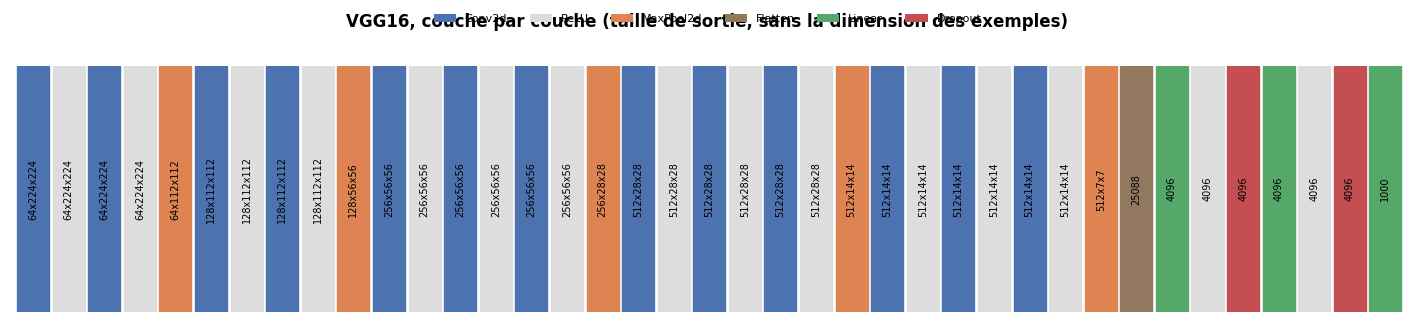

✅ Ex 20.21a : Bravo !
✅ Ex 20.21b : Exact !


In [46]:
def make_vgg16_21():
    """VGG16 for images of 3 x 224 x 224: an nn.Sequential of its 13 convolutions (3 x 3, padding 1, each followed by a
    ReLU) in 5 blocks of 64, 64 | 128, 128 | 256, 256, 256 | 512, 512, 512 | 512, 512, 512 filters, each block ending
    with nn.MaxPool2d(2); then nn.Flatten(), nn.Linear(25088, 4096), ReLU, nn.Dropout(0.5), nn.Linear(4096, 4096), ReLU,
    nn.Dropout(0.5), nn.Linear(4096, 1000)."""
    layers, c_in = [], 3
    for block in ([64, 64], [128, 128], [256, 256, 256], [512, 512, 512], [512, 512, 512]):
        for c_out in block:
            layers += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.ReLU()]
            c_in = c_out
        layers.append(nn.MaxPool2d(2))
    layers += [nn.Flatten(), nn.Linear(512 * 7 * 7, 4096), nn.ReLU(), nn.Dropout(0.5),
               nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(0.5), nn.Linear(4096, 1000)]
    return nn.Sequential(*layers)


def plan_21(model, x):
    """The plan of the network: the list of (layer name, output shape as a tuple) for each layer of model (an
    nn.Sequential), fed with x, in order; for example ("Conv2d", (1, 64, 224, 224))."""
    plan = []
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            plan.append((type(layer).__name__, tuple(x.shape)))
    return plan


def draw_plan_21(plan):
    """Draw the plan as in figure 20.17 of the book: one box per layer, from left to right, with one colour per kind of
    layer (convolution, ReLU, pooling, flatten, dense, dropout) and the output size written in the box. Returns the
    matplotlib Figure."""
    colours = {"Conv2d": "#4C72B0", "ReLU": "#DDDDDD", "MaxPool2d": "#DD8452", "Flatten": "#937860", "Linear": "#55A868",
               "Dropout": "#C44E52"}
    fig, ax = plt.subplots(figsize=(18, 3.2))
    for i, (name, shape) in enumerate(plan):
        ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=colours.get(name, "#8172B3")))
        size = "x".join(str(s) for s in shape[1:])
        ax.text(i + 0.45, 0.5, size, rotation=90, ha="center", va="center", fontsize=7)
    for name, colour in colours.items():
        ax.bar(0, 0, color=colour, label=name)
    ax.set_xlim(-0.2, len(plan))
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.25), fontsize=8)
    ax.set_title("VGG16, couche par couche (taille de sortie, sans la dimension des exemples)", pad=28)
    return fig


vgg_s21 = make_vgg16_21()
plan_s21 = plan_21(vgg_s21, torch.zeros(1, 3, 224, 224))
block3_21 = str([shape for name, shape in plan_s21 if name == "MaxPool2d"][2])
share_21 = 100 * n_params([m for m in vgg_s21 if isinstance(m, nn.Linear)][0]) / n_params(vgg_s21)
del vgg_s21
import torchvision

with torch.device("meta"):                                   # the architecture of torchvision, without allocating its weights
    reference_21 = torchvision.models.vgg16(weights=None)
with checked("20.21"):
    torch.manual_seed(21)
    vgg_21 = make_vgg16_21()
    verdict("20.21", isinstance(vgg_21, nn.Sequential), "make_vgg16_21 rend un nn.Sequential.",
            f"make_vgg16_21 rend un {type(vgg_21).__name__} : attendu un nn.Sequential.")
    count_21, want_21 = f"{n_params(vgg_21):_}".replace("_", " "), f"{n_params(reference_21):_}".replace("_", " ")
    verdict("20.21", n_params(vgg_21) == n_params(reference_21), f"{count_21} paramètres, comme le VGG16 de torchvision.",
            f"{count_21} paramètres, mais torchvision.models.vgg16 en a {want_21} : compare tes blocs et tes couches denses à la docstring.")
    kinds_21 = [type(m).__name__ for m in vgg_21]
    verdict("20.21", kinds_21.count("Conv2d") == 13 and kinds_21.count("Linear") == 3 and kinds_21.count("MaxPool2d") == 5,
            "13 convolutions, 5 max poolings et 3 couches denses.",
            f"{kinds_21.count('Conv2d')} convolutions, {kinds_21.count('MaxPool2d')} max poolings et {kinds_21.count('Linear')} couches denses : attendu 13, 5 et 3.")
    started_21 = time.perf_counter()
    plan_c21 = plan_21(vgg_21, torch.zeros(1, 3, 224, 224))
    print(f"a forward pass of VGG16 on one image: {time.perf_counter() - started_21:.2f} s")
    ok_21 = isinstance(plan_c21, list) and len(plan_c21) == len(vgg_21) and all(isinstance(p, tuple) and len(p) == 2 for p in plan_c21)
    verdict("20.21", ok_21 and plan_c21[-1] == ("Linear", (1, 1000)) and plan_c21[0] == ("Conv2d", (1, 64, 224, 224)),
            "le plan : une ligne par couche, de (Conv2d, (1, 64, 224, 224)) à (Linear, (1, 1000)).",
            f"plan_21 doit rendre une liste de (nom, forme), une par couche ; reçu {str(plan_c21)[:200]}.")
    if ok_21:
        fig_21 = draw_plan_21(plan_c21)
        boxes_21 = [p for ax in getattr(fig_21, "axes", []) for p in ax.patches]
        verdict("20.21", hasattr(fig_21, "axes") and len(boxes_21) >= len(plan_c21),
                f"draw_plan_21 dessine {len(boxes_21)} formes pour {len(plan_c21)} couches.",
                "draw_plan_21 doit rendre une figure matplotlib avec au moins une forme (un rectangle) par couche.")
        plt.show()
    del vgg_21
wb.check("20.21a", shape_text(block3_21))
wb.check("20.21b", share_21)

In [47]:
wb.record("20.21a", block3_21, mistakes={"après le 3ᵉ pooling, la taille a été divisée par 2 trois fois : 224 / 8": "(1, 256, 56, 56)",
          "après le 3ᵉ pooling, combien de canaux dans le bloc 3 ?": "(1, 128, 28, 28)", "c'est la sortie du 4ᵉ pooling : compte les blocs": "(1, 512, 14, 14)",
          "la forme de sortie garde l'axe 0, celui des exemples (ici une seule image)": "(256, 28, 28)"})
wb.record("20.21b", share_21, decimals=1, mistakes={"la PREMIÈRE couche dense seulement, pas les trois": 89.4,
          "en %, pas en proportion": share_21 / 100})

WB_ANSWER {"hash": "65b4d2198325e5406c682e74e7492d360493202579f4c5d1b9fe006b39ed8bf1", "id": "20.21a", "kind": "str", "mistakes": {"31148a64a73251496945f095ff24f19b6bbe624902443decdcc478e9dffed6e0": "après le 3ᵉ pooling, la taille a été divisée par 2 trois fois : 224 / 8", "3f5108ecd3ea6c45bca4d3e943273516eb5d6bde7d133f61ce356f9e131eaa63": "après le 3ᵉ pooling, combien de canaux dans le bloc 3 ?", "716a5f7e577c97ecfad66f00bcc85fd527ab2f8ff6490935c2becae3dd5d04be": "c'est la sortie du 4ᵉ pooling : compte les blocs", "7a1661069742d4298455b47510d0b0123f5d48c3857eed868e2ca9aa1851a189": "la forme de sortie garde l'axe 0, celui des exemples (ici une seule image)"}}
📝 Ex 20.21a : réponse enregistrée (str).
WB_ANSWER {"decimals": 1, "hash": "229784d87dbbe5d22cff6683d8191a1dbc5bca24fa4462bf20ba75876373e81d", "hash_coarse": "3c869b78ac54723ca84ee6bde59a7484cecb8b96beb0215e452036eeb7784199", "id": "20.21b", "kind": "float", "magnitude": 1, "mistakes": {"0355f3872f82cbc3fc24f63ac0b928a9ee44e9c092f

💡 La largeur est divisée par 2 à chaque max pooling (224 → 112 → 56 → 28 → 14 → 7), jamais par les convolutions (padding 1) ; le nombre de canaux double au début de chaque bloc, de 64 à 512. L'aplatissement transforme $512 \times 7 \times 7$ en 25 088 valeurs. Ce que la figure ne montre pas : le coût. Les convolutions font l'essentiel des calculs avec 11 % des paramètres ; la première couche dense, une seule boîte, en porte les trois quarts.

### Ex 20.22 — batchnorm_forward et batchnorm_backward 🔨 ★★★ ⏱️ 75 min
**Objectif :** écrire la batchnorm de PyTorch en NumPy, entraînement et évaluation, passe avant et passe arrière, en 2-D et en 4-D.  
**Prérequis :** ch. 18 (passe arrière d'une couche) · ✏️ 20.4 · ∂ 20.8 · fiche §20.4.4 · **Fil rouge :** synthétique · **mylearn :** `nn/regularization.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/regularization.py` (créé par `python tools/start_chapter.py 20`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement : PyTorch est l'**oracle** des tests (sans PyTorch, ils comparent à une transcription NumPy des formules de la fiche, et aucun n'est ignoré). La cellule de vérification recharge ta librairie, essaie les exemples des docstrings et quelques cas choisis (comparés à PyTorch), puis lance les tests de l'exercice ; `python -m pytest tests/test_ch20_regularization.py -q` les lance tous dans un terminal.

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : tes fonctions acceptent des listes comme des tableaux ; elles ne modifient **jamais** leurs entrées (sauf, dans `batchnorm_forward` en entraînement, `running_mean` et `running_var`, mis à jour **en place**, et les tableaux passés à `EarlyStopping.restore`) ; les tableaux qu'elles rendent sont de **nouveaux** tableaux `float64` (jamais l'entrée elle-même, ni une vue) ; les entrées invalides lèvent `ValueError`, sans diffusion (*broadcasting*) : une forme différente est refusée même si NumPy saurait la diffuser.

Écris `batchnorm_forward(x, gamma, beta, running_mean, running_var, training=True, momentum=0.1, eps=1e-5)` et `batchnorm_backward(dout, cache)`. **Contrat** propre à la batchnorm :
- `x` a la forme `(N, D)` (statistiques sur l'axe 0) ou `(N, C, H, W)` (statistiques par canal, sur les axes 0, 2 et 3) ; `gamma`, `beta`, `running_mean` et `running_var` ont la forme `(D,)` ou `(C,)`, sinon `ValueError` (même pour une forme diffusable) ; un autre nombre de dimensions lève aussi `ValueError` ;
- en entraînement : la moyenne et la variance **biaisée** du mini-batch normalisent ($\epsilon$ sous la racine), puis $y = \gamma\hat x + \beta$ ; `running_mean` et `running_var` sont mis à jour **en place** : $(1 - \rho)\times$ l'ancienne valeur $+ \rho\times$ la nouvelle, avec $\rho$ = `momentum` et la variance **non biaisée** pour `running_var` ; une seule valeur par feature (ou par canal) lève `ValueError` ;
- en évaluation : les statistiques glissantes normalisent, et ne changent pas ;
- `cache` est ce que tu veux : tout ce dont la passe arrière a besoin ; `batchnorm_backward` rend `(dx, dgamma, dbeta)`, les gradients de la loss par rapport à `x`, $\gamma$ et $\beta$ : en entraînement, la moyenne et la variance du mini-batch dépendent de `x` ; en évaluation, les statistiques glissantes sont des constantes.

La vérification essaie l'exemple de la docstring, puis, en `(6, 3)` et en `(4, 3, 5, 5)`, compare ta passe avant, tes statistiques glissantes, tes gradients et ton évaluation à `nn.BatchNorm1d` et `nn.BatchNorm2d` (en `float64`, avec autograd), essaie deux refus, puis lance les tests (`-k "test_batchnorm_"`).

Dans tes notes : écris l'équation de ∂ 20.8 que tu as programmée, et dis combien d'opérations elle coûte. Pourquoi PyTorch garde-t-il dans `running_var` la variance non biaisée, et pas celle qui sert à normaliser ?

In [48]:
if True:
    R = mylearn.nn.regularization
    x_22 = np.array([[1.0, 2.0], [3.0, 6.0]])
    running_mean_22, running_var_22 = np.zeros(2), np.ones(2)
    out_22, cache_22 = pair("20.22", "batchnorm_forward", R.batchnorm_forward(x_22, np.ones(2), np.zeros(2), running_mean_22, running_var_22),
                            ("out", "cache"))
    same("20.22", "l'exemple de la docstring", out_22, [[-0.999995, -0.99999875], [0.999995, 0.99999875]], rtol=1e-6, atol=1e-8)
    same("20.22", "running_mean et running_var après ce pas, mis à jour en place", np.stack([running_mean_22, running_var_22]), [[0.2, 0.4], [1.1, 1.7]])
    rng_22 = np.random.default_rng(22)
    for shape_22 in [(6, 3), (4, 3, 5, 5)]:
        x_r22 = rng_22.normal(2.0, 3.0, size=shape_22)
        gamma_22, beta_22 = rng_22.normal(1.0, 0.2, 3), rng_22.normal(0.0, 0.5, 3)
        layer_22 = (nn.BatchNorm1d if len(shape_22) == 2 else nn.BatchNorm2d)(3, dtype=torch.float64)
        with torch.no_grad():
            layer_22.weight.copy_(torch.tensor(gamma_22))
            layer_22.bias.copy_(torch.tensor(beta_22))
        x_t22 = torch.tensor(x_r22, requires_grad=True)
        want_22 = layer_22.train()(x_t22)
        rm_22, rv_22 = np.zeros(3), np.ones(3)
        got_22, cache_r22 = pair("20.22", "batchnorm_forward", R.batchnorm_forward(x_r22, gamma_22, beta_22, rm_22, rv_22), ("out", "cache"))
        same("20.22", f"entraînement, x de forme {shape_22}, contre nn.{type(layer_22).__name__}", got_22, want_22)
        same("20.22", f"statistiques glissantes après ce pas, forme {shape_22}", np.stack([rm_22, rv_22]),
             torch.stack([layer_22.running_mean, layer_22.running_var]))
        dout_22 = rng_22.normal(size=shape_22)
        want_22.backward(torch.tensor(dout_22))
        dx_22, dgamma_22, dbeta_22 = pair("20.22", "batchnorm_backward", R.batchnorm_backward(dout_22, cache_r22), ("dx", "dgamma", "dbeta"))
        same("20.22", f"dx contre l'autograd de PyTorch, forme {shape_22}", dx_22, x_t22.grad)
        same("20.22", f"dgamma et dbeta contre l'autograd, forme {shape_22}", np.stack([as_numpy(dgamma_22), as_numpy(dbeta_22)]),
             torch.stack([layer_22.weight.grad, layer_22.bias.grad]))
        layer_22.eval()
        got_e22, _ = pair("20.22", "batchnorm_forward", R.batchnorm_forward(x_r22, gamma_22, beta_22, rm_22.copy(), rv_22.copy(), training=False),
                          ("out", "cache"))
        same("20.22", f"évaluation, forme {shape_22} (statistiques glissantes)", got_e22, layer_22(torch.tensor(x_r22)))
    refuses("20.22", "un seul exemple en entraînement", lambda: R.batchnorm_forward(np.ones((1, 3)), np.ones(3), np.zeros(3), np.zeros(3), np.ones(3)))
    refuses("20.22", "gamma de forme (1,) pour 3 features", lambda: R.batchnorm_forward(np.ones((4, 3)), np.ones(1), np.zeros(3), np.zeros(3), np.ones(3)))
if written(lambda: mylearn.nn.regularization.batchnorm_forward(np.ones((2, 1)), np.ones(1), np.zeros(1), np.zeros(1), np.ones(1))):
    run_reg_tests(impl="ref", keyword="test_batchnorm_")
else:
    print("⏳ Ex 20.22 : les tests attendent tes fonctions.")

✅ Ex 20.22 : l'exemple de la docstring : [[-0.999995, -0.99999875], [0.999995, 0.99999875]], comme attendu.
✅ Ex 20.22 : running_mean et running_var après ce pas, mis à jour en place : [[0.2, 0.4], [1.1, 1.7]], comme attendu.
✅ Ex 20.22 : entraînement, x de forme (6, 3), contre nn.BatchNorm1d : un tableau (6, 3), comme attendu.
✅ Ex 20.22 : statistiques glissantes après ce pas, forme (6, 3) : [[0.19639846, 0.29977258, 0.09147918], [2.44290185, 2.02624764, 2.80340098]], comme attendu.
✅ Ex 20.22 : dx contre l'autograd de PyTorch, forme (6, 3) : un tableau (6, 3), comme attendu.
✅ Ex 20.22 : dgamma et dbeta contre l'autograd, forme (6, 3) : [[0.72391491, -1.70854105, -0.16751543], [3.14058922, -5.27611957, 3.48805665]], comme attendu.
✅ Ex 20.22 : évaluation, forme (6, 3) (statistiques glissantes) : un tableau (6, 3), comme attendu.
✅ Ex 20.22 : entraînement, x de forme (4, 3, 5, 5), contre nn.BatchNorm2d : un tableau (4, 3, 5, 5), comme attendu.
✅ Ex 20.22 : statistiques glissantes aprè

pytest: 32 passed, 71 deselected in 1.30s


💡 Avec $s = 1/\sqrt{\sigma_B^2 + \epsilon}$ et $m$ valeurs par feature : $dx = \frac{\gamma s}{m}(m\,g - \sum g - \hat x\sum g\hat x)$, en $O(m)$, avec `dbeta` $= \sum g$ et `dgamma` $= \sum g\hat x$ calculés au passage. La statistique glissante sert à **estimer** la variance de toutes les données, d'où l'estimateur non biaisé ($\frac{m}{m-1}$, ch. 2), comme l'algorithme 2 d'Ioffe et Szegedy ; la normalisation du mini-batch, elle, utilise la variance des valeurs qu'elle normalise, qui sont alors exactement centrées réduites.

## Partie C · La boucle d'entraînement, ses bugs, ses courbes, et ce qu'on en garde

Écrire la boucle d'entraînement complète et l'évaluation (20.23), réparer une boucle qui contient cinq erreurs classiques (20.24), lire des courbes d'entraînement et de validation (20.25), confronter un modèle ImageNet moderne à des images qu'il n'a jamais vues (20.26), puis sauvegarder un entraînement et le reprendre à l'identique (20.27).

### Ex 20.23 — La boucle d'entraînement PyTorch complète sur MNIST 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire une epoch d'entraînement et une évaluation PyTorch, avec les modes train et eval et le device, et entraîner un MLP sur MNIST.  
**Prérequis :** Ex 20.18 · Ex 20.19 · ch. 19 (optimiseurs) · fiche §20.3.2, §20.7, section PyTorch en pratique (la boucle) · **Fil rouge :** MNIST · **Parcours :** R, M, C

Écris les deux fonctions de toute boucle d'entraînement :
- `train_one_epoch_23(model, loader, loss_fn, optimizer, device)` : met le modèle en mode entraînement, puis, pour chaque mini-batch de `loader`, envoie `X` et `y` sur `device`, fait **une** passe avant, calcule la loss, puis `optimizer.zero_grad()`, `loss.backward()` et `optimizer.step()` ; elle rend la loss moyenne de l'epoch **par exemple** (chaque loss de mini-batch pondérée par son nombre d'exemples), en `float` Python ;
- `evaluate_23(model, loader, loss_fn, device)` : met le modèle en mode évaluation et calcule sous `torch.no_grad()` ; elle rend le couple `(loss moyenne, accuracy)`, deux `float` Python (moyennes par exemple), sans changer les paramètres.

La vérification lance d'abord un **contrôle** reproductible (le modèle `make_model_23(0)`, fourni, avec dropout ; une graine fixée pour le dropout ; SGD de learning rate 0,1 ; une epoch sur les 2 048 premières images) : elle regarde, pendant chaque passe avant, le mode du modèle et si les gradients sont calculés, puis vérifie :
a) la loss d'entraînement de cette epoch ;
b) l'accuracy de validation qui suit (les 10 000 dernières images d'entraînement, jamais vues).
Puis elle entraîne le modèle avec Adam (learning rate $10^{-3}$) pendant 3 epochs (10 en mode complet) et affiche les courbes en chiffres.

Dans tes notes : pourquoi la loss d'entraînement de la première epoch est-elle plus haute que la loss de validation mesurée juste après ? (Deux raisons.) Si la loss de validation cessait de baisser, quel planning du ch. 19 pourrais-tu ajouter, et où l'appellerais-tu (`torch.optim.lr_scheduler.ReduceLROnPlateau`) ?

In [49]:
X_ALL_23, Y_ALL_23 = wb.datasets.load_mnist("train", normalize=True)        # 60 000 images, float32 in [0, 1]
N_TRAIN_23 = wb.by_mode(fast=12_000, full=50_000)                            # the training images used here
TRAIN_SET_23 = TensorDataset(torch.from_numpy(X_ALL_23[:N_TRAIN_23]).unsqueeze(1), torch.from_numpy(Y_ALL_23[:N_TRAIN_23]))
VAL_SET_23 = TensorDataset(torch.from_numpy(X_ALL_23[50_000:]).unsqueeze(1), torch.from_numpy(Y_ALL_23[50_000:]))
VAL_LOADER_23 = DataLoader(VAL_SET_23, batch_size=1000)                      # the last 10 000 images: never trained on


def train_loader_23(seed, n=None):
    """The training mini-batches (64 images), shuffled by a generator seeded with seed; the first n images if n is given."""
    data = TRAIN_SET_23 if n is None else torch.utils.data.Subset(TRAIN_SET_23, range(n))
    return DataLoader(data, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(seed))


def make_model_23(seed=0):
    """The MLP of this part, 784-128-10 with a dropout of 0.2, initialized with the seed, on the device DEVICE."""
    torch.manual_seed(seed)
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10)).to(DEVICE)


print(f"training: {len(TRAIN_SET_23)} images · validation: {len(VAL_SET_23)} images · device {DEVICE}")

training: 12000 images · validation: 10000 images · device cpu


In [50]:
def train_one_epoch_23(model, loader, loss_fn, optimizer, device):
    """One epoch of training of model (already on device) over the mini-batches of loader.

    Puts the model in training mode, then, for each mini-batch: moves X and y to device, ONE forward pass, the loss,
    optimizer.zero_grad(), loss.backward(), optimizer.step(). Returns the mean training loss over the EXAMPLES of the
    epoch (each mini-batch loss weighted by its number of examples), as a Python float.
    """
    model.train()
    total, count = 0.0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        loss = loss_fn(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y)
        count += len(y)
    return total / count


def evaluate_23(model, loader, loss_fn, device):
    """(mean loss, accuracy) of model on the mini-batches of loader, as two Python floats (means over the examples).

    Puts the model in evaluation mode and computes under torch.no_grad(); the parameters do not change.
    """
    model.eval()
    total, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            total += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            count += len(y)
    return total / count, correct / count
control_loss_23 = control_acc_23 = ...
with checked("20.23"):
    model_23 = make_model_23(0)
    seen_23 = []                                              # (training mode, gradients enabled) at every forward pass
    hook_23 = model_23.register_forward_pre_hook(lambda module, args: seen_23.append((module.training, torch.is_grad_enabled())))
    try:
        torch.manual_seed(1)                                  # the dropout masks of the control run
        control_loss_23 = train_one_epoch_23(model_23, train_loader_23(23, n=2048), nn.CrossEntropyLoss(),
                                             torch.optim.SGD(model_23.parameters(), lr=0.1), DEVICE)
        train_seen_23, seen_23[:] = list(seen_23), []
        before_23 = [p.detach().clone() for p in model_23.parameters()]
        first_23 = evaluate_23(model_23, VAL_LOADER_23, nn.CrossEntropyLoss(), DEVICE)
        eval_seen_23 = list(seen_23)
        second_23 = evaluate_23(model_23, VAL_LOADER_23, nn.CrossEntropyLoss(), DEVICE)
    finally:
        hook_23.remove()
    verdict("20.23", isinstance(control_loss_23, float), "train_one_epoch_23 rend un float Python.",
            f"train_one_epoch_23 rend {type(control_loss_23).__name__} : attendu un float Python (additionne loss.item(), pas loss : "
            "un tenseur garde tout le graphe de calcul).")
    verdict("20.23", len(train_seen_23) == 32 and all(mode and grad for mode, grad in train_seen_23),
            "entraînement : 32 passes avant (une par mini-batch), en mode train, avec les gradients.",
            f"entraînement : {len(train_seen_23)} passes avant (attendu 32, UNE par mini-batch de 2 048 / 64), modes "
            f"{sorted(set(train_seen_23))} (attendu (True, True) : model.train() au début, et pas de torch.no_grad()).")
    ok_eval_23 = isinstance(first_23, tuple) and len(first_23) == 2
    if not ok_eval_23:
        print(f"❌ Ex 20.23 : evaluate_23 doit rendre le couple (loss, accuracy), reçu {first_23!r}.")
    else:
        verdict("20.23", bool(eval_seen_23) and all(not mode and not grad for mode, grad in eval_seen_23),
                "évaluation : mode eval et torch.no_grad() à chaque passe avant.",
                f"évaluation : modes (train, gradients) vus {sorted(set(eval_seen_23))} : attendu (False, False), avec model.eval() "
                "et torch.no_grad().")
        unchanged_23 = all(torch.equal(a, b) for a, b in zip(before_23, model_23.parameters()))
        verdict("20.23", unchanged_23 and first_23 == second_23 and all(isinstance(v, float) for v in first_23),
                "evaluate_23 ne change pas les paramètres, rend deux floats et redonne les mêmes valeurs.",
                f"evaluate_23 : deux appels donnent {first_23} puis {second_23}, ou changent les paramètres : attendu deux floats, "
                "identiques d'un appel à l'autre (le dropout doit être éteint).")
        control_acc_23 = first_23[1]
        print(f"control run: training loss {float(control_loss_23):.4f}, validation loss {first_23[0]:.4f}, accuracy {first_23[1]:.4f}")
with checked("20.23"):                                        # the mean over the EXAMPLES: 100 images, mini-batches of 64 and 36
    if isinstance(control_loss_23, float):
        with torch.random.fork_rng():                         # leaves the random state of the next trainings untouched
            torch.manual_seed(0)
            probe_23 = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(DEVICE)
            got_23 = train_one_epoch_23(probe_23, DataLoader(torch.utils.data.Subset(TRAIN_SET_23, range(100)), batch_size=64),
                                        nn.CrossEntropyLoss(), torch.optim.SGD(probe_23.parameters(), lr=0.0), DEVICE)
            with torch.no_grad():
                want_23 = nn.functional.cross_entropy(probe_23(TRAIN_SET_23.tensors[0][:100].to(DEVICE)),
                                                      TRAIN_SET_23.tensors[1][:100].to(DEVICE)).item()
        verdict("20.23", isinstance(got_23, float) and abs(got_23 - want_23) < 1e-5,
                "la loss rendue est la moyenne sur les exemples (sur 100 images, le mini-batch de 36 pèse 36, pas autant que celui de 64).",
                f"sur 100 images en mini-batches de 64 et 36 (learning rate nul), train_one_epoch_23 rend {got_23!r}, la moyenne "
                f"sur les exemples vaut {want_23:.5f} : pondère chaque loss de mini-batch par son nombre d'exemples.")
if control_loss_23 is ... or isinstance(control_loss_23, float):
    wb.check("20.23a", control_loss_23, computed=True)
else:
    print("❌ Ex 20.23a : la loss du contrôle n'est vérifiée que si train_one_epoch_23 rend un float Python (voir plus haut).")
wb.check("20.23b", control_acc_23, computed=True)
with checked("20.23"):
    if isinstance(control_loss_23, float) and isinstance(control_acc_23, float):
        model_23 = make_model_23(0)
        optimizer_23 = torch.optim.Adam(model_23.parameters(), lr=1e-3)
        print("epoch   train loss   val loss   val accuracy   seconds")
        for epoch_23 in range(1, wb.by_mode(fast=3, full=10) + 1):
            started_23 = time.perf_counter()
            train_l_23 = train_one_epoch_23(model_23, train_loader_23(epoch_23), nn.CrossEntropyLoss(), optimizer_23, DEVICE)
            val_l_23, val_a_23 = evaluate_23(model_23, VAL_LOADER_23, nn.CrossEntropyLoss(), DEVICE)
            print(f"{epoch_23:5}   {train_l_23:10.4f}   {val_l_23:8.4f}   {val_a_23:12.4f}   {time.perf_counter() - started_23:7.1f}")
        verdict("20.23", val_a_23 > 0.92, f"après l'entraînement, {val_a_23:.1%} de bonnes réponses en validation.",
                f"après l'entraînement, {val_a_23:.1%} en validation : attendu plus de 92 % ; vérifie la boucle.")
    else:
        print("⏳ Ex 20.23 : l'entraînement complet attend le contrôle ci-dessus.")

✅ Ex 20.23 : train_one_epoch_23 rend un float Python.
✅ Ex 20.23 : entraînement : 32 passes avant (une par mini-batch), en mode train, avec les gradients.
✅ Ex 20.23 : évaluation : mode eval et torch.no_grad() à chaque passe avant.
✅ Ex 20.23 : evaluate_23 ne change pas les paramètres, rend deux floats et redonne les mêmes valeurs.
control run: training loss 1.9155, validation loss 1.4191, accuracy 0.7755
✅ Ex 20.23 : la loss rendue est la moyenne sur les exemples (sur 100 images, le mini-batch de 36 pèse 36, pas autant que celui de 64).
✅ Ex 20.23a : Bien joué !
✅ Ex 20.23b : C'est ça !
epoch   train loss   val loss   val accuracy   seconds


    1       0.6936     0.3353         0.9084       0.5


    2       0.3180     0.2645         0.9261       0.5


    3       0.2535     0.2337         0.9355       0.5
✅ Ex 20.23 : après l'entraînement, 93.5% de bonnes réponses en validation.


In [51]:
model_r23 = make_model_23(0)
torch.manual_seed(1)
loss_r23 = train_one_epoch_23(model_r23, train_loader_23(23, n=2048), nn.CrossEntropyLoss(), torch.optim.SGD(model_r23.parameters(), lr=0.1), DEVICE)
acc_r23 = evaluate_23(model_r23, VAL_LOADER_23, nn.CrossEntropyLoss(), DEVICE)[1]
wb.record("20.23a", loss_r23, decimals=4)
wb.record("20.23b", acc_r23, decimals=4)

WB_ANSWER {"decimals": 4, "hash": "b56fa6f5a92b4318d5440dcaa54b456208d1071c600f0ec06e923588b087c32a", "hash_coarse": "9071ce3fe289b3acb8dfec0c335f82d1a43701f95d2e21f79a31c8b95b206005", "id": "20.23a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex 20.23a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"alt_coarse": ["b48ca9bd6277c1e2797f7d770c32dc20b9cba35bc0aa030fde33be05ed45be3a"], "decimals": 4, "hash": "dc6dfbccba94166de3dcde7fb44bf456fb2afd582a3a5e4621013f64a5495ef4", "hash_coarse": "ab0b4bf35df2ebc94ed9fbcd68957fe9040589e4c82b0e443a538e6b62681a3b", "id": "20.23b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 20.23b : réponse enregistrée (float, 4 décimale(s)).


💡 La loss d'entraînement d'une epoch est la **moyenne** des losses mesurées pendant l'epoch, avec des poids qui s'améliorent au fil des mini-batches : les premiers, mesurés avec des poids presque aléatoires, la tirent vers le haut. La validation, mesurée après l'epoch, voit les poids de la fin. Et l'entraînement est mesuré **avec** le dropout, qui le rend plus difficile ; la validation sans. `ReduceLROnPlateau(optimizer, factor=0.5, patience=2)` s'appelle après chaque évaluation, avec la loss de validation : `scheduler.step(val_loss)`.

### Ex 20.24 — Chasse aux bugs PyTorch : cinq erreurs classiques 🐛 ★★ ⏱️ 30 min
**Objectif :** trouver et corriger cinq erreurs classiques d'une boucle PyTorch, chacune à son symptôme.  
**Prérequis :** Ex 20.23 · fiche, section PyTorch en pratique et tableau des pièges · **Fil rouge :** MNIST · **Parcours :** R, C

Un collègue a écrit ce code pour entraîner un MLP sur MNIST : la classe `Net24`, une epoch d'entraînement `train_epoch_24` et une évaluation `evaluate_24`. Il contient **cinq** erreurs classiques. Corrige-les dans la cellule (garde les noms et les signatures), sans réécrire ce qui est juste.

La vérification les cherche dans l'ordre où elles se masquent, une par point, et ne passe à un point que si les précédents sont réparés : 1, la forme de ce que rend le réseau ; 2, ce que rend sa dernière couche ; 3, le gradient utilisé à chaque pas (sur un petit modèle) ; 4, le type de ce que rend `train_epoch_24` ; 5, l'évaluation d'un modèle qui a du dropout. Quand les cinq passent, elle entraîne `Net24` une epoch et mesure son accuracy.

Dans tes notes : pour chaque erreur, le symptôme qu'elle aurait produit dans un vrai entraînement (un plantage, une loss qui stagne, une mémoire qui grossit, une accuracy qui varie…), et la ligne que tu as changée.

In [52]:
X_24, Y_24 = wb.datasets.load_mnist("train", n=6000, normalize=True)
LOADER_24 = DataLoader(TensorDataset(torch.from_numpy(X_24).unsqueeze(1), torch.from_numpy(Y_24)), batch_size=64, shuffle=True,
                       generator=torch.Generator().manual_seed(24))
print("6 000 MNIST images in mini-batches of 64")

6 000 MNIST images in mini-batches of 64


In [53]:
class Net24(nn.Module):
    """A MLP 784-128-10 with a dropout of 0.3; it returns the logits."""

    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 128)
        self.drop = nn.Dropout(0.3)
        self.out = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)                 # 1. keep the dimension of the examples
        x = self.drop(torch.relu(self.hidden(x)))
        return self.out(x)                                # 2. the logits: CrossEntropyLoss does the softmax


def train_epoch_24(model, loader, optimizer):
    """One epoch of training (cross-entropy on the logits); returns the mean loss of the epoch, a Python float."""
    model.train()
    total, count = 0.0, 0
    for X, y in loader:
        loss = nn.functional.cross_entropy(model(X), y)
        optimizer.zero_grad()                             # 3. otherwise the gradients add up from batch to batch
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y)                     # 4. a number, not a tensor that keeps the graph
        count += len(y)
    return total / count


def evaluate_24(model, loader):
    """The accuracy of model on the mini-batches of loader, a Python float."""
    model.eval()                                          # 5. no dropout to measure (and no gradients)
    correct, count = 0, 0
    with torch.no_grad():
        for X, y in loader:
            correct += (model(X).argmax(dim=1) == y).sum().item()
            count += len(y)
    return correct / count
def shape_point_24():
    """Point 1: the shape of what Net24 returns for a mini-batch of 8 images ("" if right, else the symptom)."""
    torch.manual_seed(0)
    try:
        logits = Net24()(torch.rand(8, 1, 28, 28))
    except RuntimeError as exc:
        return f"Net24 plante sur un mini-batch de 8 images : {str(exc)[:160]}"
    if tuple(logits.shape) != (8, 10):
        return f"Net24 rend la forme {tuple(logits.shape)} pour 8 images : attendu (8, 10), une ligne par image."
    return ""


def logits_point_24():
    """Point 2: what the last layer of Net24 returns."""
    torch.manual_seed(0)
    logits = Net24()(torch.rand(8, 1, 28, 28)).detach()
    if torch.allclose(logits.sum(dim=1), torch.ones(8), atol=1e-5) and bool((logits >= 0).all()):
        return "les sorties de Net24 sont positives et chaque ligne somme à 1 : regarde ce que la loss attend."
    return ""


def probe_24():
    """A small linear model and three mini-batches (5 examples, 4 features, 3 classes), always the same."""
    torch.manual_seed(1)
    model = nn.Linear(4, 3)
    return model, [(torch.randn(5, 4), torch.randint(0, 3, (5,))) for _ in range(3)]


def gradient_point_24():
    """Point 3: the gradient used at each step, on the small model."""
    model, batches = probe_24()
    train_epoch_24(model, batches, torch.optim.SGD(model.parameters(), lr=0.0))      # lr 0: the weights do not move
    last = nn.Linear(4, 3)
    last.load_state_dict(model.state_dict())
    nn.functional.cross_entropy(last(batches[-1][0]), batches[-1][1]).backward()     # the gradient of the last batch alone
    grad = model.weight.grad
    if not (grad is None or bool((grad == 0).all()) or torch.allclose(grad, last.weight.grad, atol=1e-7)):
        return "après trois mini-batches, le gradient vaut la SOMME des trois gradients : regarde ce que fait backward() à .grad."
    model, batches = probe_24()
    start = model.weight.detach().clone()
    train_epoch_24(model, batches, torch.optim.SGD(model.parameters(), lr=0.1))
    if torch.equal(model.weight.detach(), start):
        return "avec un learning rate de 0,1, les poids n'ont pas bougé : les gradients sont-ils effacés avant step() ?"
    return ""


def float_point_24():
    """Point 4: the type of what train_epoch_24 returns."""
    model, batches = probe_24()
    returned = train_epoch_24(model, batches, torch.optim.SGD(model.parameters(), lr=0.0))
    if isinstance(returned, float):
        return ""
    graph = getattr(returned, "grad_fn", None) is not None
    return (f"train_epoch_24 rend {type(returned).__name__}" + (" avec un grad_fn" if graph else "") + " : attendu un float"
            + (" (et la somme garde ici tout le graphe de calcul de l'epoch en mémoire)." if graph else "."))


EVAL_MODES_24 = []                                        # (training mode, gradients enabled) seen by point 5


def eval_point_24():
    """Point 5: the evaluation of a model that has dropout."""
    torch.manual_seed(2)
    noisy = nn.Sequential(nn.Linear(4, 64), nn.Dropout(0.5), nn.Linear(64, 3))
    batches = [(torch.randn(200, 4), torch.randint(0, 3, (200,)))]
    EVAL_MODES_24.clear()
    hook = noisy.register_forward_pre_hook(lambda module, args: EVAL_MODES_24.append((module.training, torch.is_grad_enabled())))
    try:
        accs = [evaluate_24(noisy, batches) for _ in range(3)]
    finally:
        hook.remove()
    if len(set(accs)) != 1 or any(mode for mode, _ in EVAL_MODES_24):
        return f"trois évaluations du même modèle donnent {accs} : regarde ce que fait le dropout pendant la mesure."
    return ""


POINTS_24 = [("la forme de ce que rend le réseau", shape_point_24, "Net24 rend une ligne de 10 scores par image."),
             ("ce que rend sa dernière couche", logits_point_24, "Net24 rend des logits."),
             ("le gradient utilisé à chaque pas", gradient_point_24, "chaque pas utilise le gradient de son seul mini-batch."),
             ("le type de ce que rend train_epoch_24", float_point_24, "train_epoch_24 rend un float Python."),
             ("l'évaluation d'un modèle qui a du dropout", eval_point_24, "l'évaluation est déterministe (pas de dropout).")]

with checked("20.24"):                                    # one point per error, in the order where they hide each other
    blocked_24 = None
    for number_24, (name_24, point_24, success_24) in enumerate(POINTS_24, start=1):
        if blocked_24 is not None:
            print(f"⏳ Ex 20.24 : point {number_24} ({name_24}) : corrige d'abord le point {blocked_24}.")
            continue
        try:
            problem_24 = point_24()
        except NotImplementedError:
            raise
        except Exception as error_24:                     # a crash of the code: say which point it broke
            problem_24 = f"ton code lève {type(error_24).__name__} : {str(error_24)[:200]}"
        verdict("20.24", not problem_24, f"point {number_24} : {success_24}", f"point {number_24} : {problem_24}")
        if problem_24:
            blocked_24 = number_24
    if blocked_24 is None and any(grad for _, grad in EVAL_MODES_24):
        print("ℹ️ Ex 20.24 : point 5 : l'évaluation construit encore le graphe des gradients, inutile pour mesurer et "
              "coûteux en mémoire (relis le tableau des pièges de la fiche).")
    if blocked_24 is None:
        torch.manual_seed(24)
        net_24 = Net24()
        loss_24 = train_epoch_24(net_24, LOADER_24, torch.optim.Adam(net_24.parameters(), lr=1e-3))
        acc_24 = evaluate_24(net_24, LOADER_24)
        verdict("20.24", acc_24 > 0.85, f"tout est réparé : une epoch, loss {loss_24:.3f}, accuracy {acc_24:.1%} (sur les images d'entraînement).",
                f"une epoch donne {acc_24:.1%} : il reste une erreur.")
    else:
        print("⏳ Ex 20.24 : l'entraînement de contrôle attend les cinq points.")

✅ Ex 20.24 : point 1 : Net24 rend une ligne de 10 scores par image.
✅ Ex 20.24 : point 2 : Net24 rend des logits.
✅ Ex 20.24 : point 3 : chaque pas utilise le gradient de son seul mini-batch.
✅ Ex 20.24 : point 4 : train_epoch_24 rend un float Python.
✅ Ex 20.24 : point 5 : l'évaluation est déterministe (pas de dropout).


✅ Ex 20.24 : tout est réparé : une epoch, loss 1.070, accuracy 87.8% (sur les images d'entraînement).


💡 1. `torch.flatten(x)` met le mini-batch entier à plat : `hidden` reçoit un vecteur de 784 × 64 valeurs et plante (`x.flatten(start_dim=1)` ou `nn.Flatten()`). 2. La softmax avant `cross_entropy` fait une softmax de trop : la loss baisse à peine et les gradients s'écrasent. 3. Sans `zero_grad()`, les gradients s'additionnent d'un mini-batch à l'autre : les pas grandissent sans fin, la loss oscille ou explose. 4. `total += loss` garde le graphe de **chaque** mini-batch : la mémoire grossit pendant l'epoch, et la fonction rend un tenseur (`loss.item()`). 5. Sans `model.eval()`, l'évaluation garde le dropout : une accuracy plus basse, différente à chaque mesure (et `torch.no_grad()` économise la mémoire du graphe).

### Ex 20.25 — Courbes train/validation : overfitting, eval() oublié, fuite 📈 ★★ ⏱️ 20 min
**Objectif :** reconnaître sur des courbes d'entraînement et de validation l'overfitting, une fuite, un eval() oublié, l'underfitting et l'effet du dropout.  
**Prérequis :** ch. 9 (overfitting, early stopping) · 🧠 20.Q11 · fiche §20.4.3, sections PyTorch en pratique et régulariser un réseau · **Fil rouge :** Fashion-MNIST · **Parcours :** R, M

Cinq entraînements d'un classifieur sur Fashion-MNIST (10 classes ; les courbes sont fabriquées, mais leurs formes sont celles qu'on rencontre) : à chaque epoch, la loss d'entraînement (la moyenne pendant l'epoch, mesurée **avec** le dropout quand le modèle en a), la loss de validation et l'accuracy de validation (mesurées après l'epoch). Les données sont dans `CURVES_25` si tu veux les lire en chiffres. Réponds par la **lettre** de l'entraînement, sauf b) :
a) `overfit_25` : celui qui surapprend nettement ;
b) `stop_25` : pour cet entraînement, l'epoch dont un early stopping garderait les poids (la première epoch est la n° 1) ;
c) `leak_25` : celui dont la validation contient, sans qu'on le sache, des images d'entraînement (une fuite) ;
d) `noeval_25` : celui dont la validation est mesurée sans `model.eval()` : le dropout reste actif pendant la mesure ;
e) `underfit_25` : celui dont le modèle est bien trop petit pour le problème ;
f) `dropout_25` : celui qui est sain, avec un dropout bien réglé.

Dans tes notes : pour f), pourquoi la loss de validation peut-elle rester **sous** celle d'entraînement sans qu'il y ait de fuite ? Pour c), qu'est-ce qui t'a alerté, et comment vérifierais-tu la fuite sur les données ?

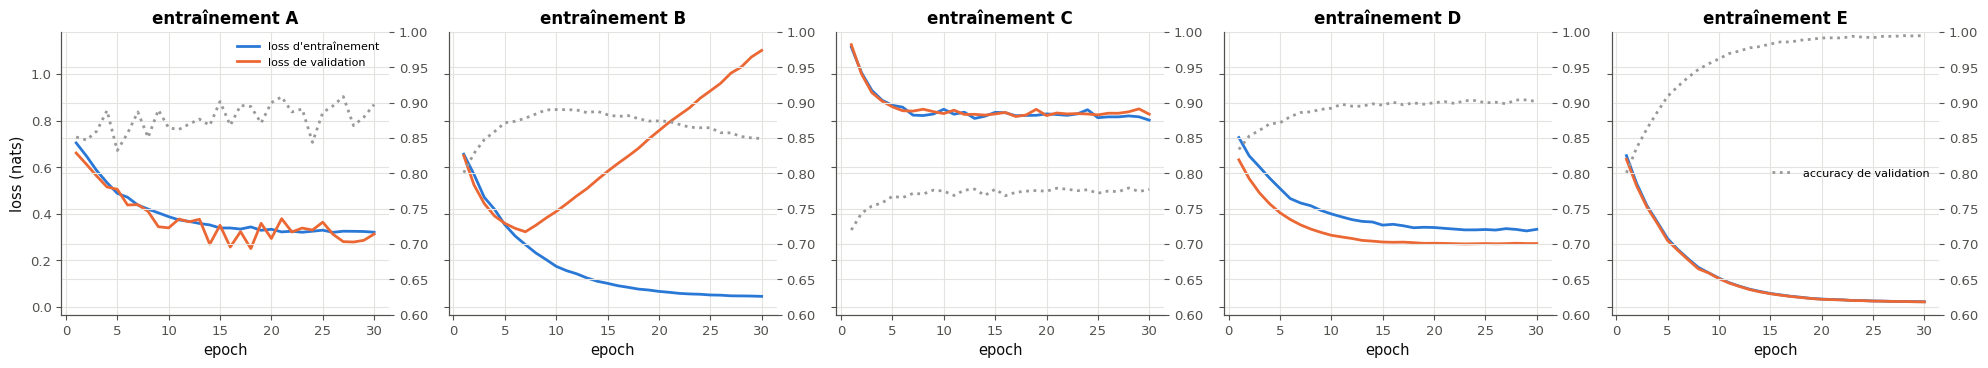

In [54]:
CURVES_25 = wb.synth.training_curves()       # five training histories: CURVES_25["A"]["val_loss"]...
fig_25, axes_25 = plt.subplots(1, 5, figsize=(20, 3.8), sharey=True)
for ax, (name_25, history_25) in zip(axes_25, CURVES_25.items()):
    epochs_25 = np.arange(1, len(history_25["train_loss"]) + 1)
    ax.plot(epochs_25, history_25["train_loss"], label="loss d'entraînement")
    ax.plot(epochs_25, history_25["val_loss"], label="loss de validation")
    ax.set_title(f"entraînement {name_25}")
    ax.set_xlabel("epoch")
    twin_25 = ax.twinx()
    twin_25.plot(epochs_25, history_25["val_acc"], color="0.6", ls=":", label="accuracy de validation")
    twin_25.set_ylim(0.6, 1.0)
axes_25[0].set_ylabel("loss (nats)")
axes_25[0].legend(fontsize=8)
twin_25.legend(fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

In [55]:
overfit_25, leak_25, noeval_25, underfit_25, dropout_25 = "B", "E", "A", "C", "D"
stop_25 = int(np.argmin(CURVES_25["B"]["val_loss"])) + 1
for letter_25, answer_25 in zip("abcdef", [overfit_25, stop_25, leak_25, noeval_25, underfit_25, dropout_25]):
    wb.check(f"20.25{letter_25}", answer_25)

✅ Ex 20.25a : Parfait !
✅ Ex 20.25b : Bravo !
✅ Ex 20.25c : Exact !
✅ Ex 20.25d : Bien joué !
✅ Ex 20.25e : C'est ça !
✅ Ex 20.25f : Parfait !


In [56]:
wb.record("20.25a", "B", mistakes={"regarde la loss de validation de A : est-elle régulière, d'une epoch à l'autre ?": "A", "regarde le niveau final des deux losses de C et son accuracy": "C", "regarde les deux losses de D : laquelle est au-dessus, et la validation remonte-t-elle ?": "D", "regarde l'accuracy de validation finale de E : est-elle réaliste pour Fashion-MNIST ?": "E"})
wb.record("20.25b", int(np.argmin(CURVES_25["B"]["val_loss"])) + 1, mistakes={"les epochs sont comptées à partir de 1": int(np.argmin(CURVES_25["B"]["val_loss"])),
          "on s'arrête au minimum de la loss de VALIDATION, pas de celle d'entraînement": int(np.argmin(CURVES_25["B"]["train_loss"])) + 1})
wb.record("20.25c", "E", mistakes={"regarde la loss de validation de A : est-elle régulière, d'une epoch à l'autre ?": "A", "regarde la loss de validation de B, epoch après epoch : que fait-elle après son minimum ?": "B", "regarde le niveau final des deux losses de C et son accuracy": "C", "regarde les deux losses de D : laquelle est au-dessus, et la validation remonte-t-elle ?": "D"})
wb.record("20.25d", "A", mistakes={"regarde la loss de validation de B, epoch après epoch : que fait-elle après son minimum ?": "B", "regarde le niveau final des deux losses de C et son accuracy": "C", "regarde les deux losses de D : laquelle est au-dessus, et la validation remonte-t-elle ?": "D", "regarde l'accuracy de validation finale de E : est-elle réaliste pour Fashion-MNIST ?": "E"})
wb.record("20.25e", "C", mistakes={"regarde la loss de validation de A : est-elle régulière, d'une epoch à l'autre ?": "A", "regarde la loss de validation de B, epoch après epoch : que fait-elle après son minimum ?": "B", "regarde les deux losses de D : laquelle est au-dessus, et la validation remonte-t-elle ?": "D", "regarde l'accuracy de validation finale de E : est-elle réaliste pour Fashion-MNIST ?": "E"})
wb.record("20.25f", "D", mistakes={"regarde la loss de validation de A : est-elle régulière, d'une epoch à l'autre ?": "A", "regarde la loss de validation de B, epoch après epoch : que fait-elle après son minimum ?": "B", "regarde le niveau final des deux losses de C et son accuracy": "C", "regarde l'accuracy de validation finale de E : est-elle réaliste pour Fashion-MNIST ?": "E"})

WB_ANSWER {"hash": "f48bf98dab7d1f10f599eab5bbed1fcd4a8b73e5dc04b630c9a85c1c2217af2a", "id": "20.25a", "kind": "str", "mistakes": {"93f8c06a2067f9cee44460b57e2817d9eba6103b0b68897cf023269906fe2fa8": "regarde les deux losses de D : laquelle est au-dessus, et la validation remonte-t-elle ?", "9b2f58faef25ee134157dba76aa3e86eee38c33963be87aadf49619666a733c8": "regarde la loss de validation de A : est-elle régulière, d'une epoch à l'autre ?", "bda51a7b36a033d7c441494d5c716f3558054820e4d93c37c59a6865a6a54b47": "regarde le niveau final des deux losses de C et son accuracy", "debfd6b79b7b8e97cd46b211a07bd8e6fc60950cdff10e78352fcf42300fe604": "regarde l'accuracy de validation finale de E : est-elle réaliste pour Fashion-MNIST ?"}}
📝 Ex 20.25a : réponse enregistrée (str).
WB_ANSWER {"hash": "f5a688b7d65a1628dd1f5fb15f2fa801b7211a444ffa5c086a7968dbad106429", "id": "20.25b", "kind": "int", "magnitude": 0, "mistakes": {"0c69771623c03226a5788acc9f82fc179deaf385f426987ea14b108477954dd2": "on s'arrêt

💡 B : la loss de validation passe par un minimum net à l'epoch 7, puis remonte pendant que celle d'entraînement continue de baisser vers 0 : un early stopping garde l'epoch 7. E : la validation colle à l'entraînement jusqu'à presque 0, avec 99,5 % d'accuracy, invraisemblable sur Fashion-MNIST (les meilleurs modèles plafonnent vers 93 à 96 %) : une fuite. A : la validation est mesurée avec le dropout, au niveau de l'entraînement, et elle saute d'une epoch à l'autre. C : les deux losses restent hautes (vers 0,8) et collées l'une à l'autre : underfitting. D : la loss de validation reste sous celle d'entraînement, parce que l'entraînement est mesuré avec le dropout (et en moyenne sur l'epoch, avec des poids moins bons), la validation sans ; elle ne remonte pas : c'est sain. On vérifie une fuite en cherchant des images en double entre les deux jeux (des empreintes des tableaux, ch. 12).

### Ex 20.26 — Un modèle ImageNet face à des images qu'il n'a jamais vues 🔮 ★★ ⏱️ 25 min
**Objectif :** prédire ce que fait un petit modèle ImageNet moderne sur des photos de 32 × 32 pixels et sur du bruit, puis le mesurer.  
**Prérequis :** Ex 20.23 · ch. 17 (softmax) · fiche §20.6, §20.8 · **Fil rouge :** CIFAR-10 · **Parcours :** C

Au §20.6, le livre montre VGG16 face à des objets hors de ses 1 000 classes. On refait l'expérience avec un modèle moderne et léger, **MobileNet V3 Small** (2,5 millions de paramètres, 67,7 % top-1 sur ImageNet, poids fournis par torchvision, environ 10 Mo à télécharger une fois), qui reçoit des images redimensionnées par son prétraitement (agrandies à 256 × 256, puis recadrées au centre en 224 × 224) : 100 photos de **chats** de CIFAR-10 (32 × 32 pixels), 200 photos de CIFAR-10 de toutes les classes, et 200 images de **bruit pur** (des pixels tirés au hasard). Pour chaque image, le modèle rend 1 000 probabilités (une softmax) ; on regarde sa classe la plus probable et sa probabilité la plus haute. Prédis, **avant** d'exécuter quoi que ce soit (pour a), d) et e) : (A) moins de 20 % ; (B) de 20 à 40 % ; (C) de 40 à 60 % ; (D) de 60 à 80 % ; (E) plus de 80 %) :
a) `cats_26` : la part des 100 photos de chats que le modèle classe dans l'une des 5 races de chats domestiques d'ImageNet ;
b) `noise_26` : la moyenne, sur les 200 images de bruit, de la probabilité la plus haute : (A) moins de 0,2 ; (B) de 0,2 à 0,4 ; (C) de 0,4 à 0,6 ; (D) de 0,6 à 0,8 ; (E) plus de 0,8 ;
c) `higher_26` : cette moyenne est-elle plus haute sur les 200 photos de CIFAR-10 que sur le bruit ? (`True` ou `False`) ;
d) `same_26` : la part des images de bruit qui reçoivent **la même** classe, la plus fréquente ;
e) `refused_26` : on décide de refuser de répondre quand la probabilité la plus haute est sous 0,5 ; la part des 200 photos de CIFAR-10 refusées.

Puis exécute l'expérience : elle mesure les cinq valeurs, montre six chats et six bruits avec leurs deux classes les plus probables, et vérifie tes prédictions (sans réseau, elle te renvoie vers Colab).

In [57]:
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

try:                                                       # ≈ 10 MB, downloaded once into the cache of torch
    WEIGHTS_26 = MobileNet_V3_Small_Weights.DEFAULT
    MODEL_26 = mobilenet_v3_small(weights=WEIGHTS_26).eval()
    PREPROCESS_26, CATEGORIES_26 = WEIGHTS_26.transforms(), WEIGHTS_26.meta["categories"]
    print(f"MobileNet V3 Small: {n_params(MODEL_26):_} parameters, {len(CATEGORIES_26)} ImageNet classes".replace("_", " "))
except Exception as exc:                                   # no network: the experiment says so
    MODEL_26 = None
    print(f"ℹ️ Ex 20.26 : impossible de télécharger les poids du modèle ({type(exc).__name__}) : fais cet exercice sur Colab.")
X_C26, Y_C26 = wb.datasets.load_cifar10("test", channels_first=True)          # uint8 (10000, 3, 32, 32)
CATS_26 = X_C26[np.flatnonzero(Y_C26 == 3)[:100]]          # 100 photos of cats (class 3 of CIFAR-10)
PHOTOS_26 = X_C26[:200]                                    # 200 photos of the 10 classes
NOISE_26 = np.random.default_rng(0).integers(0, 256, size=(200, 3, 32, 32), dtype=np.uint8)   # 200 images of pure noise
DOMESTIC_CATS_26 = range(281, 286)                         # the 5 classes of domestic cats among the 1 000 of ImageNet


def probabilities_26(images):
    """The softmax probabilities (N, 1000) of the ImageNet model for uint8 images (N, 3, H, W)."""
    with torch.no_grad():
        return torch.softmax(MODEL_26(PREPROCESS_26(torch.from_numpy(images))), dim=1)

MobileNet V3 Small: 2 542 856 parameters, 1000 ImageNet classes


In [58]:
cats_26, noise_26, higher_26, same_26, refused_26 = "A", "A", True, "D", "D"   # the answers, for the record

In [59]:
p_cats_r26, p_photos_r26, p_noise_r26 = probabilities_26(CATS_26), probabilities_26(PHOTOS_26), probabilities_26(NOISE_26)
band_r26 = lambda share: "ABCDE"[min(4, int(share * 5))]
cats_r26 = band_r26(float(np.isin(p_cats_r26.argmax(dim=1).numpy(), list(DOMESTIC_CATS_26)).mean()))
noise_r26 = band_r26(float(p_noise_r26.max(dim=1).values.mean()))
higher_r26 = bool(p_photos_r26.max(dim=1).values.mean() > p_noise_r26.max(dim=1).values.mean())
same_r26 = band_r26(float(np.unique(p_noise_r26.argmax(dim=1).numpy(), return_counts=True)[1].max() / len(NOISE_26)))
refused_r26 = band_r26(float((p_photos_r26.max(dim=1).values < 0.5).float().mean()))
print("recorded:", cats_r26, noise_r26, higher_r26, same_r26, refused_r26)
SHARES_r26 = {"A": "moins de 20 %", "B": "de 20 à 40 %", "C": "de 40 à 60 %", "D": "de 60 à 80 %", "E": "plus de 80 %"}
MEANS_r26 = {"A": "moins de 0,2", "B": "de 0,2 à 0,4", "C": "de 0,4 à 0,6", "D": "de 0,6 à 0,8", "E": "plus de 0,8"}
look_r26 = lambda line, bands, right: {f"relis la ligne {line}) de l'expérience : est-ce {text} ?": letter for letter, text in bands.items() if letter != right}
wb.record("20.26a", cats_r26, mistakes=look_r26("a", SHARES_r26, cats_r26))
wb.record("20.26b", noise_r26, mistakes=look_r26("b", MEANS_r26, noise_r26))
wb.record("20.26c", higher_r26, mistakes={"compare les lignes b) et c) de l'expérience": not higher_r26})
wb.record("20.26d", same_r26, mistakes=look_r26("d", SHARES_r26, same_r26))
wb.record("20.26e", refused_r26, mistakes=look_r26("e", SHARES_r26, refused_r26))

recorded: A A True D D
WB_ANSWER {"hash": "23bb2d603ceef70a4b74ca739f3745af25bbc64290f446adaccbdaa82b9f6cde", "id": "20.26a", "kind": "str", "mistakes": {"2d1891c987f0d21e8a242e8176e516475f02cb674f91d6fb42276e4f69ca92ad": "relis la ligne a) de l'expérience : est-ce de 40 à 60 % ?", "5bc90a37dab165e7ef4c15f79abddf87c254e74d60f28e79c6b837c7091a8dff": "relis la ligne a) de l'expérience : est-ce de 20 à 40 % ?", "cb6d613285959bff527b6b7948193386db76eb913546c3b3e1c8511063ec1d83": "relis la ligne a) de l'expérience : est-ce de 60 à 80 % ?", "f9798c1a1775615dc4837ae077bc21c2d2541076b9a7fcaac3ad32fa2e1ee303": "relis la ligne a) de l'expérience : est-ce plus de 80 % ?"}}
📝 Ex 20.26a : réponse enregistrée (str).
WB_ANSWER {"hash": "9de4f7a709973fa53f256832b6cdf057cc0ab578bd3bd923d94bfaf2442dadee", "id": "20.26b", "kind": "str", "mistakes": {"1c8ced963566f52b731c182528433ec55bc716150109a1bcecc8bf2512f12cc4": "relis la ligne b) de l'expérience : est-ce de 0,2 à 0,4 ?", "5f4cd6564a8d13fbefe798fa2bb

a) cat photos classified as a domestic cat: 7%
b) mean of the highest probability on noise: 0.130
c) the same on the CIFAR-10 photos: 0.380
d) noise images that get the most frequent class, « prayer rug »: 68%
e) CIFAR-10 photos refused by the rule « highest probability < 0.5 »: 75%


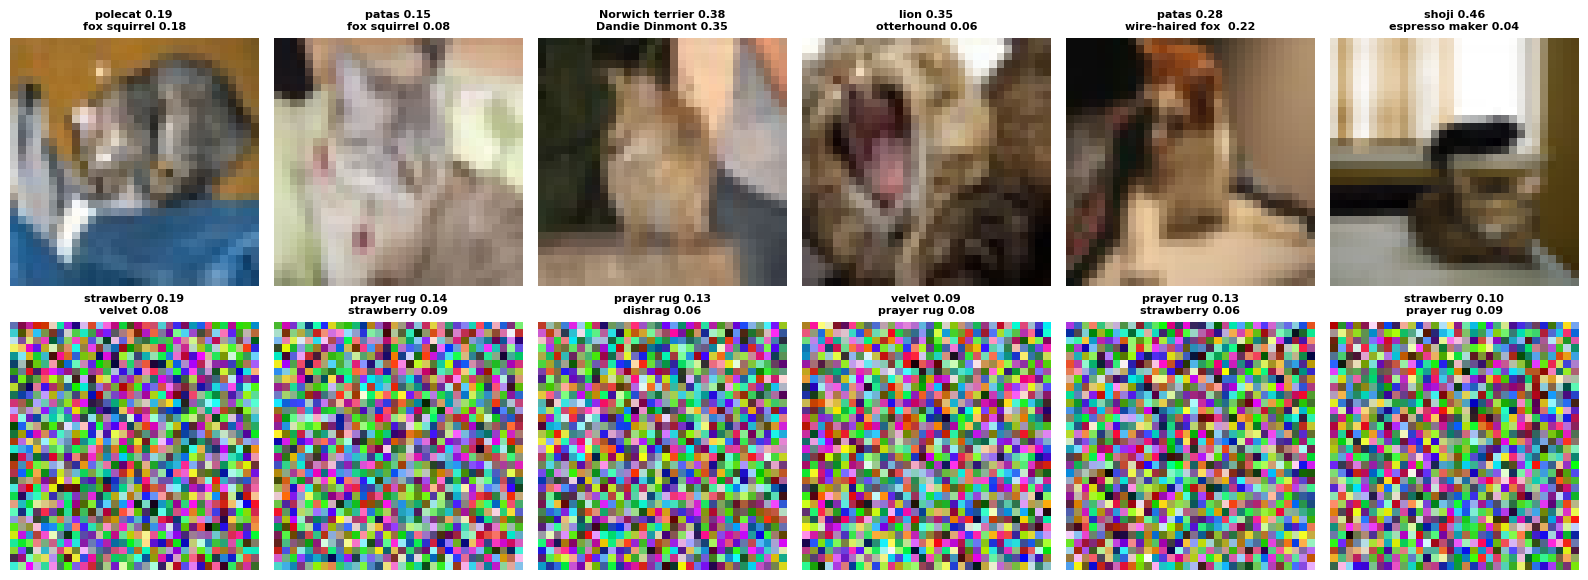

✅ Ex 20.26a : Bravo !
✅ Ex 20.26b : Exact !
✅ Ex 20.26c : Bien joué !
✅ Ex 20.26d : C'est ça !
✅ Ex 20.26e : Parfait !


In [60]:
if any(answer is ... or answer is None for answer in [cats_26, noise_26, higher_26, same_26, refused_26]):
    print("⏳ Ex 20.26 : écris d'abord tes cinq prédictions, puis relance cette cellule.")
else:
    if MODEL_26 is None:
        print("⏳ Ex 20.26 : pas de modèle (pas de réseau) : fais cette expérience sur Colab.")
    else:
        def band_26(share):
            """The letter of a share: A below 20 %, B from 20 to 40 %, C from 40 to 60 %, D from 60 to 80 %, E above 80 %."""
            return "ABCDE"[min(4, int(share * 5))]

        p_cats_26, p_photos_26, p_noise_26 = probabilities_26(CATS_26), probabilities_26(PHOTOS_26), probabilities_26(NOISE_26)
        share_cats_26 = float(np.isin(p_cats_26.argmax(dim=1).numpy(), list(DOMESTIC_CATS_26)).mean())
        conf_photos_26, conf_noise_26 = p_photos_26.max(dim=1).values, p_noise_26.max(dim=1).values
        top_noise_26 = p_noise_26.argmax(dim=1).numpy()
        values_26, counts_26 = np.unique(top_noise_26, return_counts=True)
        share_same_26 = counts_26.max() / len(top_noise_26)
        share_refused_26 = float((conf_photos_26 < 0.5).float().mean())
        print(f"a) cat photos classified as a domestic cat: {share_cats_26:.0%}")
        print(f"b) mean of the highest probability on noise: {conf_noise_26.mean():.3f}")
        print(f"c) the same on the CIFAR-10 photos: {conf_photos_26.mean():.3f}")
        print(f"d) noise images that get the most frequent class, « {CATEGORIES_26[values_26[counts_26.argmax()]]} »: {share_same_26:.0%}")
        print(f"e) CIFAR-10 photos refused by the rule « highest probability < 0.5 »: {share_refused_26:.0%}")
        fig_26, axes_26 = plt.subplots(2, 6, figsize=(16, 6))
        for ax, image_26, probs_26 in zip(axes_26.ravel(), np.concatenate([CATS_26[:6], NOISE_26[:6]]),
                                          torch.cat([p_cats_26[:6], p_noise_26[:6]])):
            ax.imshow(image_26.transpose(1, 2, 0))
            best_26 = probs_26.topk(2)
            ax.set_title("\n".join(f"{CATEGORIES_26[i][:16]} {p:.2f}" for p, i in zip(best_26.values.tolist(), best_26.indices.tolist())), fontsize=8)
            ax.axis("off")
        plt.tight_layout()
        plt.show()
        for letter_26, value_26 in zip("abcde", [cats_26, noise_26, higher_26, same_26, refused_26]):
            wb.check(f"20.26{letter_26}", value_26)

Dans tes notes : pour chaque prédiction, qu'est-ce qui t'a guidé, et qu'est-ce qui t'a surpris ? Qu'est-ce que l'expérience dit de la règle e) pour détecter qu'une image n'est pas « pour » le modèle ? Que changerais-tu pour reconnaître les chats de CIFAR-10 ?

💡 Les chiffres mesurés et leur discussion sont dans `05_solutions.md`.

### Ex 20.27 — Sauvegarder, recharger et reproduire un entraînement 🛠️ ★★ ⏱️ 25 min
**Objectif :** écrire un checkpoint qui permet de reprendre un entraînement exactement là où il s'était arrêté.  
**Prérequis :** Ex 20.23 · fiche, section PyTorch en pratique (sauvegarder) et encadré sur la reproductibilité · **Fil rouge :** MNIST · **Parcours :** R, C

Un entraînement s'arrête (une machine qui redémarre, une session Colab qui expire) : il faut pouvoir le reprendre. Écris :
- `save_checkpoint_27(path, model, optimizer, epoch, generator)` : sauvegarde dans `path` (avec `torch.save`) un dictionnaire de cinq clés : `"model"` (le `state_dict` du modèle), `"optimizer"` (celui de l'optimiseur), `"epoch"` (le nombre d'epochs faites), `"generator"` (l'état du générateur qui mélange les données, `generator.get_state()`) et `"torch_rng"` (l'état du générateur global de torch, qui tire les masques du dropout, `torch.get_rng_state()`) ;
- `load_checkpoint_27(path, model, optimizer, generator)` : recharge tout cela (dans le modèle, l'optimiseur, le générateur et le générateur global) et rend le nombre d'epochs faites ; `torch.load(path)` doit marcher dans son mode sûr par défaut (`weights_only=True`).

La vérification entraîne un MLP deux epochs d'affilée (la référence) ; puis le même MLP une epoch, sauvegarde, crée un **nouveau** modèle, un nouvel optimiseur et un nouveau générateur, recharge le checkpoint et fait la seconde epoch. Elle contrôle le contenu du fichier, chaque élément rechargé, puis compare les poids finaux à ceux de la référence, **au bit près**. Les fichiers vont dans un dossier temporaire, jamais dans le dépôt.

Dans tes notes : enlève une à une les clés `"optimizer"`, `"generator"` et `"torch_rng"` : qu'est-ce qui casse, et pourquoi ? Sur GPU, que faudrait-il de plus pour une reproduction au bit près (encadré de la fiche) ?

In [61]:
X_27, Y_27 = wb.datasets.load_mnist("train", n=2048, normalize=True)
DATA_27 = TensorDataset(torch.from_numpy(X_27).unsqueeze(1), torch.from_numpy(Y_27))


def make_model_27(seed):
    """A MLP 784-64-10 with dropout, initialized with the seed."""
    torch.manual_seed(seed)
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 10))


def epoch_27(model, optimizer, generator):
    """One epoch of training on DATA_27, in mini-batches of 64 shuffled by generator."""
    model.train()
    for X, y in DataLoader(DATA_27, batch_size=64, shuffle=True, generator=generator):
        loss = nn.functional.cross_entropy(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


FOLDER_27 = Path(tempfile.mkdtemp())                        # a temporary folder (never in the repository)
print("checkpoints go to", FOLDER_27)

checkpoints go to /tmp/tmpahbdvj2j


In [62]:
def save_checkpoint_27(path, model, optimizer, epoch, generator):
    """Save in path everything needed to resume the training exactly: a dict with the keys "model" (the state_dict),
    "optimizer" (its state_dict), "epoch" (the number of epochs done), "generator" (the state of the generator that
    shuffles the data) and "torch_rng" (the state of the global random generator of torch, used by the dropout)."""
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "epoch": epoch,
                "generator": generator.get_state(), "torch_rng": torch.get_rng_state()}, path)


def load_checkpoint_27(path, model, optimizer, generator):
    """Load the checkpoint of path into model, optimizer, generator and the global random generator of torch, and
    return the number of epochs done. torch.load must work with its default safe mode (weights_only=True)."""
    checkpoint = torch.load(path)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    generator.set_state(checkpoint["generator"])
    torch.set_rng_state(checkpoint["torch_rng"])
    return checkpoint["epoch"]
with checked("20.27"):
    model_a27 = make_model_27(0)                                     # A: two epochs in a row, the reference
    opt_a27, gen_a27 = torch.optim.Adam(model_a27.parameters(), lr=1e-3), torch.Generator().manual_seed(27)
    torch.manual_seed(7)
    for _ in range(2):
        epoch_27(model_a27, opt_a27, gen_a27)
    model_b27 = make_model_27(0)                                     # B: one epoch, then a checkpoint
    opt_b27, gen_b27 = torch.optim.Adam(model_b27.parameters(), lr=1e-3), torch.Generator().manual_seed(27)
    torch.manual_seed(7)
    epoch_27(model_b27, opt_b27, gen_b27)
    path_27 = FOLDER_27 / "checkpoint.pt"
    save_checkpoint_27(path_27, model_b27, opt_b27, 1, gen_b27)
    saved_rng_27, saved_gen_27 = torch.get_rng_state(), gen_b27.get_state()
    try:
        content_27 = torch.load(path_27)                             # the safe mode of torch.load (weights_only=True)
    except Exception as exc:
        content_27 = None
        print(f"❌ Ex 20.27 : torch.load(path) échoue en mode sûr ({type(exc).__name__}) : sauvegarde des state_dict, des tenseurs, "
              "des nombres (pas le modèle ni l'optimiseur eux-mêmes).")
    if content_27 is not None:
        keys_27 = set(content_27) if isinstance(content_27, dict) else set()
        verdict("20.27", keys_27 == {"model", "optimizer", "epoch", "generator", "torch_rng"},
                "le checkpoint contient model, optimizer, epoch, generator et torch_rng.",
                f"le checkpoint contient {sorted(keys_27)} : attendu les clés model, optimizer, epoch, generator et torch_rng.")
        torch.manual_seed(999)                                       # C: a NEW model, optimizer and generator, then the checkpoint
        model_c27 = make_model_27(1)
        opt_c27, gen_c27 = torch.optim.Adam(model_c27.parameters(), lr=1e-3), torch.Generator().manual_seed(0)
        done_27 = load_checkpoint_27(path_27, model_c27, opt_c27, gen_c27)
        verdict("20.27", isinstance(done_27, int) and not isinstance(done_27, bool) and done_27 == 1, "load_checkpoint_27 rend le nombre d'epochs faites : 1.", f"load_checkpoint_27 rend {done_27!r} : attendu 1.")
        same_model_27 = all(torch.equal(a, b) for a, b in zip(model_c27.state_dict().values(), model_b27.state_dict().values()))
        state_c27 = opt_c27.state_dict()["state"]
        same_opt_27 = len(state_c27) == len(opt_b27.state_dict()["state"]) and all(
            torch.equal(state_c27[k]["exp_avg"], v["exp_avg"]) for k, v in opt_b27.state_dict()["state"].items())
        same_gen_27 = torch.equal(gen_c27.get_state(), saved_gen_27)
        same_rng_27 = torch.equal(torch.get_rng_state(), saved_rng_27)
        for ok_27, what_27, fix_27 in [(same_model_27, "les poids du modèle", "model.load_state_dict(...)"),
                                       (same_opt_27, "l'état de l'optimiseur (les moyennes d'Adam)", "optimizer.load_state_dict(...)"),
                                       (same_gen_27, "l'état du générateur qui mélange les données", "generator.set_state(...)"),
                                       (same_rng_27, "l'état du générateur global de torch (le dropout)", "torch.set_rng_state(...)")]:
            verdict("20.27", ok_27, f"après le chargement : {what_27}, comme au moment de la sauvegarde.",
                    f"après le chargement, ce n'est pas l'état de la sauvegarde : {what_27} ({fix_27}).")
        epoch_27(model_c27, opt_c27, gen_c27)                        # the second epoch, resumed
        identical_27 = all(torch.equal(a, b) for a, b in zip(model_c27.parameters(), model_a27.parameters()))
        verdict("20.27", identical_27, "la reprise donne exactement les mêmes poids que deux epochs d'affilée (au bit près).",
                "la reprise ne donne pas les mêmes poids que deux epochs d'affilée : quelque chose manque au checkpoint (voir plus haut).")

✅ Ex 20.27 : le checkpoint contient model, optimizer, epoch, generator et torch_rng.
✅ Ex 20.27 : load_checkpoint_27 rend le nombre d'epochs faites : 1.
✅ Ex 20.27 : après le chargement : les poids du modèle, comme au moment de la sauvegarde.
✅ Ex 20.27 : après le chargement : l'état de l'optimiseur (les moyennes d'Adam), comme au moment de la sauvegarde.
✅ Ex 20.27 : après le chargement : l'état du générateur qui mélange les données, comme au moment de la sauvegarde.
✅ Ex 20.27 : après le chargement : l'état du générateur global de torch (le dropout), comme au moment de la sauvegarde.


✅ Ex 20.27 : la reprise donne exactement les mêmes poids que deux epochs d'affilée (au bit près).


💡 Sans l'état de l'optimiseur, Adam repart de moyennes nulles : ses premiers pas, corrigés du biais, ont une autre taille. Sans le générateur des données, la seconde epoch voit les mini-batches dans un autre ordre. Sans le générateur global, le dropout tire d'autres masques. Chacun suffit à changer les poids. Sur GPU, il faut aussi l'état du générateur CUDA (`torch.cuda.get_rng_state_all()`) et des opérations déterministes (`torch.use_deterministic_algorithms(True)`).

## Partie D · Régulariser sur Fashion-MNIST, un réseau de 30 couches, puis le défi

Fashion-MNIST (des vêtements, plus difficile que les chiffres) avec tout ce que fournit le chapitre : dropout, batchnorm, AdamW et ton early stopping (20.28) ; une ablation pour savoir ce qui retarde vraiment l'overfitting (20.29) ; un réseau de 30 couches, avec et sans connexions résiduelles (20.30) ; puis le défi (20.31). Ces exercices réutilisent tes fonctions `train_one_epoch_23` et `evaluate_23` (20.23) et ta classe `EarlyStopping` (20.17).

### Ex 20.28 — Dropout, batchnorm, AdamW et early stopping sur Fashion-MNIST 📦 ★★★ ⏱️ 60 min
**Objectif :** entraîner un MLP régularisé sur Fashion-MNIST avec un early stopping qui garde les meilleurs poids.  
**Prérequis :** Ex 20.23 · Ex 20.17 · fiche §20.4.3, §20.4.4, section sur la régularisation · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Écris :
- `make_model_28(seed=0)` : un MLP 784-256-256-10 pour Fashion-MNIST, initialisé avec la graine et envoyé sur `DEVICE` : un aplatissement, puis, pour chaque couche cachée, une couche dense, une batchnorm (`nn.BatchNorm1d`), une ReLU et un dropout de 0,3 ; une dernière couche dense vers les 10 logits (la docstring donne l'ordre) ;
- `fit_28(model, max_epochs, patience)` : l'entraînement avec AdamW (learning rate $10^{-3}$, weight decay $10^{-2}$) et un early stopping sur la loss de validation. À chaque epoch (numérotée à partir de 1) : `train_one_epoch_23` sur `train_loader_28(epoch)`, `evaluate_23` sur `VAL_LOADER_28` (tes fonctions de 20.23), puis le `step` de **ta** classe `EarlyStopping` de `mylearn.nn.regularization` ; à chaque amélioration, une **copie profonde** de `model.state_dict()` ; l'entraînement s'arrête quand `step` le dit, ou au bout de `max_epochs` ; à la fin, les meilleurs poids sont rechargés dans `model`. Elle rend l'historique, un dictionnaire de trois listes de même longueur (une valeur par epoch) : `"train_loss"`, `"val_loss"` et `"val_acc"`.

La vérification contrôle l'architecture (270 346 paramètres), lance `fit_28` (au plus 15 epochs en mode rapide, sur 10 000 images ; 40 epochs et 50 000 images en mode complet), contrôle l'arrêt, que le modèle final a bien les poids de la meilleure epoch, et une accuracy de validation de plus de 85 %, puis trace les courbes.

Dans tes notes : à quelle epoch l'early stopping a-t-il gardé les poids ? Que se passerait-il sans le `copy.deepcopy` (essaie) ? Pourquoi la loss d'entraînement reste-t-elle au-dessus de la loss de validation pendant les premières epochs ?

In [63]:
X_F28, Y_F28 = wb.datasets.load_fashion_mnist("train", normalize=True)      # 60 000 images of clothes, float32 in [0, 1]
N_TRAIN_28 = wb.by_mode(fast=10_000, full=50_000)
TRAIN_SET_28 = TensorDataset(torch.from_numpy(X_F28[:N_TRAIN_28]).unsqueeze(1), torch.from_numpy(Y_F28[:N_TRAIN_28]))
VAL_LOADER_28 = DataLoader(TensorDataset(torch.from_numpy(X_F28[50_000:]).unsqueeze(1), torch.from_numpy(Y_F28[50_000:])),
                           batch_size=1000)                # the last 10 000 images: the validation
MAX_EPOCHS_28, PATIENCE_28 = wb.by_mode(fast=15, full=40), 3


def train_loader_28(epoch):
    """The training mini-batches of the epoch (128 images), shuffled by a generator seeded with the epoch number."""
    return DataLoader(TRAIN_SET_28, batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(epoch))


print(f"Fashion-MNIST: {len(TRAIN_SET_28)} training images, 10 000 for validation · classes: {wb.datasets.FASHION_CLASSES}")

Fashion-MNIST: 10000 training images, 10 000 for validation · classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


✅ Ex 20.28 : make_model_28 : 3 couches denses, 2 batchnorms, 2 dropouts, 270 346 paramètres.


✅ Ex 20.28 : 13 epochs en 8 s ; meilleure loss de validation à l'epoch 10, arrêt 3 epochs plus tard.
✅ Ex 20.28 : le modèle final a les poids de la meilleure epoch : loss de validation 0.3890, accuracy 86.3%.
✅ Ex 20.28 : plus de 85 % en validation (86.3%).


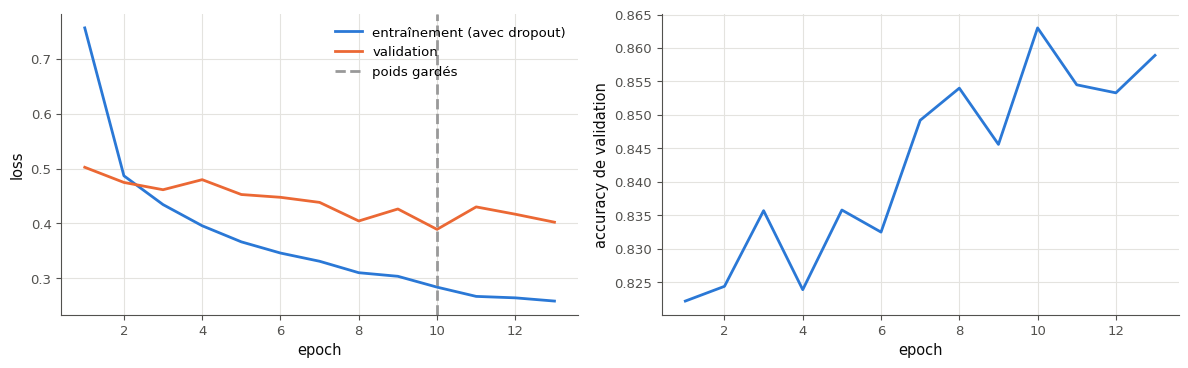

In [64]:
def make_model_28(seed=0):
    """A MLP 784-256-256-10 for Fashion-MNIST, initialized with the seed and sent to DEVICE: nn.Flatten(), then for each
    hidden layer nn.Linear -> nn.BatchNorm1d -> nn.ReLU -> nn.Dropout(0.3), and a last nn.Linear to the 10 logits."""
    torch.manual_seed(seed)
    layers = [nn.Flatten()]
    for n_in, n_out in [(784, 256), (256, 256)]:
        layers += [nn.Linear(n_in, n_out), nn.BatchNorm1d(n_out), nn.ReLU(), nn.Dropout(0.3)]
    layers.append(nn.Linear(256, 10))
    return nn.Sequential(*layers).to(DEVICE)


def fit_28(model, max_epochs=MAX_EPOCHS_28, patience=PATIENCE_28):
    """Train model with AdamW (lr 1e-3, weight_decay 1e-2) and an early stopping on the validation loss.

    Each epoch: train_one_epoch_23 on train_loader_28(epoch) (epochs numbered from 1), then evaluate_23 on VAL_LOADER_28
    (your functions of 20.23), then the step of YOUR mylearn.nn.regularization.EarlyStopping(patience=patience); a deep
    copy of model.state_dict() is kept at each improvement; the training stops when the step says so, or after
    max_epochs. At the end, the best weights are loaded back into model. Returns the history, a dict of three lists of
    the same length (one value per epoch): "train_loss", "val_loss" and "val_acc".
    """
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    stopper = mylearn.nn.regularization.EarlyStopping(patience=patience)
    loss_fn = nn.CrossEntropyLoss()
    history, best_state = {"train_loss": [], "val_loss": [], "val_acc": []}, None
    for epoch in range(1, max_epochs + 1):
        history["train_loss"].append(train_one_epoch_23(model, train_loader_28(epoch), loss_fn, optimizer, DEVICE))
        val_loss, val_acc = evaluate_23(model, VAL_LOADER_28, loss_fn, DEVICE)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        stop = stopper.step(val_loss)
        if stopper.improved_:
            best_state = copy.deepcopy(model.state_dict())
        if stop:
            break
    model.load_state_dict(best_state)
    return history
history_28 = None
with checked("20.28"):
    model_28 = make_model_28(0)
    kinds_28 = [type(m).__name__ for m in model_28.modules() if not list(m.children())]
    verdict("20.28", kinds_28.count("Linear") == 3 and kinds_28.count("BatchNorm1d") == 2 and kinds_28.count("Dropout") == 2 and n_params(model_28) == 270_346,
            "make_model_28 : 3 couches denses, 2 batchnorms, 2 dropouts, " + f"{n_params(model_28):_} paramètres.".replace("_", " "),
            f"make_model_28 contient {kinds_28} et {n_params(model_28)} paramètres : relis la docstring (Linear -> BatchNorm1d -> ReLU -> Dropout, deux fois).")
    started_28 = time.perf_counter()
    history_28 = fit_28(model_28)
    seconds_28 = time.perf_counter() - started_28
    ok_28 = isinstance(history_28, dict) and set(history_28) == {"train_loss", "val_loss", "val_acc"} and len({len(v) for v in history_28.values()}) == 1
    if not ok_28:
        print("❌ Ex 20.28 : fit_28 doit rendre un dictionnaire de trois listes de même longueur : train_loss, val_loss et val_acc.")
        history_28 = None
    else:
        val_28 = np.array(history_28["val_loss"])
        best_28 = int(np.argmin(val_28))
        n_28 = len(val_28)
        stopped_28 = n_28 < MAX_EPOCHS_28
        verdict("20.28", (not stopped_28 and n_28 == MAX_EPOCHS_28) or (stopped_28 and n_28 - 1 - best_28 == PATIENCE_28),
                f"{n_28} epochs en {seconds_28:.0f} s ; meilleure loss de validation à l'epoch {best_28 + 1}" + (f", arrêt {PATIENCE_28} epochs plus tard." if stopped_28 else ", sans que l'early stopping se déclenche."),
                f"{n_28} epochs, meilleure à l'epoch {best_28 + 1} : avec une patience de {PATIENCE_28}, l'arrêt doit venir {PATIENCE_28} epochs après la meilleure (ou au bout de {MAX_EPOCHS_28}).")
        restored_28 = evaluate_23(model_28, VAL_LOADER_28, nn.CrossEntropyLoss(), DEVICE)
        verdict("20.28", abs(restored_28[0] - val_28[best_28]) < 1e-5,
                f"le modèle final a les poids de la meilleure epoch : loss de validation {restored_28[0]:.4f}, accuracy {restored_28[1]:.1%}.",
                f"le modèle final a une loss de validation de {restored_28[0]:.4f}, pas la meilleure ({val_28[best_28]:.4f}) : garde une copie "
                "PROFONDE du state_dict à chaque amélioration, et recharge-la à la fin.")
        verdict("20.28", restored_28[1] > 0.85, f"plus de 85 % en validation ({restored_28[1]:.1%}).",
                f"{restored_28[1]:.1%} en validation : attendu plus de 85 %.")
if history_28 is not None:
    epochs_28 = np.arange(1, len(history_28["val_loss"]) + 1)
    fig_28, (ax_l28, ax_a28) = plt.subplots(1, 2, figsize=(12, 3.8))
    ax_l28.plot(epochs_28, history_28["train_loss"], label="entraînement (avec dropout)")
    ax_l28.plot(epochs_28, history_28["val_loss"], label="validation")
    ax_l28.axvline(int(np.argmin(history_28["val_loss"])) + 1, color="0.6", ls="--", label="poids gardés")
    ax_l28.set_xlabel("epoch")
    ax_l28.set_ylabel("loss")
    ax_l28.legend()
    ax_a28.plot(epochs_28, history_28["val_acc"])
    ax_a28.set_xlabel("epoch")
    ax_a28.set_ylabel("accuracy de validation")
    plt.tight_layout()
    plt.show()

💡 Sans `deepcopy`, `best_state` contient les **mêmes** tenseurs que le modèle (un `state_dict` partage la mémoire des poids) : ils continuent de changer, et `load_state_dict(best_state)` recharge les poids de la **dernière** epoch, pas ceux de la meilleure ; la vérification de la restauration échoue. La loss d'entraînement est mesurée avec le dropout et en moyenne pendant l'epoch : elle reste au-dessus de la validation au début, sans fuite (comme la courbe saine de 20.25). Les chiffres de la référence sont dans `05_solutions.md`.

### Ex 20.29 — Ablation : qu'est-ce qui retarde l'overfitting ? 🔬 ★★★ ⏱️ 60 min
**Objectif :** mesurer, par une ablation sur un petit jeu d'entraînement, ce qu'apportent le dropout, le weight decay et la batchnorm.  
**Prérequis :** Ex 20.28 · fiche §20.4.3, §20.4.4, section sur la régularisation (l'ablation) · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Avec seulement 2 000 images d'entraînement, un MLP 784-256-256-10 surapprend vite. Écris `run_29(dropout, weight_decay, batchnorm, seed, epochs=EPOCHS_29)`, qui entraîne ce MLP selon le protocole de la docstring (modèle construit après `torch.manual_seed(seed)`, AdamW, mini-batches de 64 mélangés par un générateur de graine `seed`, pas d'early stopping ; tes fonctions de 20.23) et rend son historique : trois listes de `epochs` valeurs, `"train_loss"`, `"val_loss"` et `"val_acc"`.

La vérification fait un petit contrôle (2 epochs), puis lance l'ablation : cinq configurations (rien ; un dropout de 0,5 ; un weight decay de 1 ; la batchnorm ; les trois ensemble), 2 graines et 25 epochs chacune (3 graines et 40 epochs en mode complet), de 30 s à une minute sur CPU (davantage sur une machine chargée). Elle affiche, en moyenne sur les graines, l'epoch de la meilleure loss de validation, cette meilleure loss, la loss de validation finale, la loss d'entraînement finale et la meilleure accuracy, puis trace les courbes de validation et d'entraînement.

Dans tes notes : quelle technique **retarde** le plus le minimum de la loss de validation ? Laquelle améliore le plus la loss finale ? Que fait la batchnorm : régularise-t-elle, ou accélère-t-elle l'apprentissage (relis l'encadré de la fiche) ? Les écarts d'accuracy entre configurations sont-ils plus grands que les écarts d'une graine à l'autre ? Que faudrait-il pour conclure plus sûrement ?

In [65]:
TRAIN_SET_29 = TensorDataset(torch.from_numpy(X_F28[:2000]).unsqueeze(1), torch.from_numpy(Y_F28[:2000]))   # 2 000 images: overfitting comes fast
VAL_LOADER_29 = DataLoader(TensorDataset(torch.from_numpy(X_F28[50_000:55_000]).unsqueeze(1), torch.from_numpy(Y_F28[50_000:55_000])),
                           batch_size=1000)
EPOCHS_29, SEEDS_29 = wb.by_mode(fast=25, full=40), wb.by_mode(fast=[0, 1], full=[0, 1, 2])
CONFIGS_29 = {"rien": dict(dropout=0.0, weight_decay=0.0, batchnorm=False),
              "dropout 0,5": dict(dropout=0.5, weight_decay=0.0, batchnorm=False),
              "weight decay 1": dict(dropout=0.0, weight_decay=1.0, batchnorm=False),
              "batchnorm": dict(dropout=0.0, weight_decay=0.0, batchnorm=True),
              "les trois": dict(dropout=0.5, weight_decay=1.0, batchnorm=True)}
print(f"{len(TRAIN_SET_29)} training images · {len(CONFIGS_29)} configurations x {len(SEEDS_29)} seeds x {EPOCHS_29} epochs")

2000 training images · 5 configurations x 2 seeds x 25 epochs


10 trainings in 47 s (means over the seeds)

configuration      best epoch   min val loss   final val loss   final train loss   best val acc
rien                     11.5          0.538            0.617              0.127          0.830
dropout 0,5              22.5          0.496            0.509              0.330          0.832
weight decay 1           21.5          0.519            0.588              0.198          0.826
batchnorm                 4.0          0.522            0.751              0.030          0.823
les trois                15.0          0.505            0.543              0.286          0.823
✅ Ex 20.29 : sans régularisation, la loss de validation remonte nettement après son minimum : l'overfitting est là.


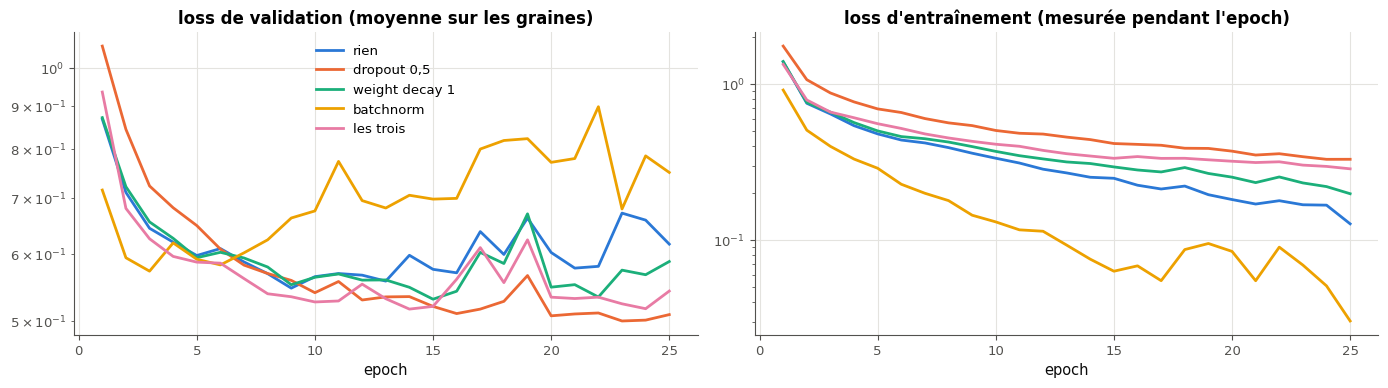

In [66]:
def run_29(dropout, weight_decay, batchnorm, seed, epochs=EPOCHS_29):
    """Train a MLP 784-256-256-10 on TRAIN_SET_29 and return its history, a dict of three lists of `epochs` values
    ("train_loss", "val_loss", "val_acc"), with train_one_epoch_23 and evaluate_23 (VAL_LOADER_29).

    The model, built after torch.manual_seed(seed): nn.Flatten(), then for each hidden layer nn.Linear, an
    nn.BatchNorm1d if batchnorm, nn.ReLU, an nn.Dropout(dropout) if dropout > 0; a last nn.Linear to the logits; on
    DEVICE. AdamW(lr=1e-3, weight_decay=weight_decay); mini-batches of 64 from ONE DataLoader for all the epochs,
    shuffled by torch.Generator().manual_seed(seed) (so each epoch sees a new order); no early stopping.
    """
    torch.manual_seed(seed)
    layers = [nn.Flatten()]
    for n_in, n_out in [(784, 256), (256, 256)]:
        layers.append(nn.Linear(n_in, n_out))
        if batchnorm:
            layers.append(nn.BatchNorm1d(n_out))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
    model = nn.Sequential(*layers, nn.Linear(256, 10)).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    loader = DataLoader(TRAIN_SET_29, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(seed))
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for _ in range(epochs):
        history["train_loss"].append(train_one_epoch_23(model, loader, nn.CrossEntropyLoss(), optimizer, DEVICE))
        val_loss, val_acc = evaluate_23(model, VAL_LOADER_29, nn.CrossEntropyLoss(), DEVICE)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
    return history
RESULTS_29 = {}                                  # the trainings of the ablation (torch models of run_29)
with checked("20.29"):
    control_29 = run_29(0.0, 0.0, False, seed=0, epochs=2)
    ok_29 = isinstance(control_29, dict) and all(len(control_29.get(k, [])) == 2 for k in ("train_loss", "val_loss", "val_acc"))
    if not ok_29:
        print("❌ Ex 20.29 : run_29(..., epochs=2) doit rendre un dictionnaire de trois listes de 2 valeurs : train_loss, val_loss et val_acc.")
    else:
        started_29 = time.perf_counter()
        for name_29, config_29 in CONFIGS_29.items():
            RESULTS_29[name_29] = [run_29(**config_29, seed=seed_29) for seed_29 in SEEDS_29]
        print(f"{len(CONFIGS_29) * len(SEEDS_29)} trainings in {time.perf_counter() - started_29:.0f} s (means over the seeds)\n")
        print("configuration      best epoch   min val loss   final val loss   final train loss   best val acc")
        for name_29, runs_29 in RESULTS_29.items():
            val_29 = np.array([r["val_loss"] for r in runs_29])
            print(f"{name_29:16} {np.mean(val_29.argmin(axis=1) + 1):12.1f} {val_29.min(axis=1).mean():14.3f} "
                  f"{val_29[:, -1].mean():16.3f} {np.mean([r['train_loss'][-1] for r in runs_29]):18.3f} "
                  f"{np.mean([max(r['val_acc']) for r in runs_29]):14.3f}")
        none_29 = np.array([r["val_loss"] for r in RESULTS_29["rien"]])
        verdict("20.29", none_29[:, -1].mean() > none_29.min(axis=1).mean() + 0.05,
                "sans régularisation, la loss de validation remonte nettement après son minimum : l'overfitting est là.",
                "sans régularisation, la loss de validation ne remonte pas : vérifie run_29 (2 000 images, pas d'early stopping).")
if RESULTS_29:
    fig_29, axes_29 = plt.subplots(1, 2, figsize=(14, 4))
    for name_29, runs_29 in RESULTS_29.items():
        epochs_29 = np.arange(1, EPOCHS_29 + 1)
        line_29, = axes_29[0].plot(epochs_29, np.mean([r["val_loss"] for r in runs_29], axis=0), label=name_29)
        axes_29[1].plot(epochs_29, np.mean([r["train_loss"] for r in runs_29], axis=0), color=line_29.get_color())
    axes_29[0].set_title("loss de validation (moyenne sur les graines)")
    axes_29[1].set_title("loss d'entraînement (mesurée pendant l'epoch)")
    for ax in axes_29:
        ax.set_xlabel("epoch")
        ax.set_yscale("log")
    axes_29[0].legend()
    plt.tight_layout()
    plt.show()

💡 Les chiffres de la référence et leur discussion sont dans `05_solutions.md`.

### Ex 20.30 — Un réseau de 30 couches : connexions résiduelles et layer norm 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer sur un MLP de 30 couches ce que changent les connexions résiduelles et la layer norm, au gradient et à l'apprentissage.  
**Prérequis :** Ex 20.23 · ✏️ 20.7 · ch. 18 (gradient évanescent) · fiche §20.4.8, section sur les connexions résiduelles · **Fil rouge :** MNIST · **Parcours :** C

Écris la classe `Deep30(nn.Module)` (la docstring donne le contrat : une couche d'entrée `self.inp`, `depth` blocs de largeur `width`, une couche de sortie `self.out` ; chaque bloc calcule $h = \mathrm{ReLU}(\text{linear}(\text{norm}(x)))$, avec une `nn.LayerNorm` si `norm`, puis $x \leftarrow x + h$ si `residual`, sinon $x \leftarrow h$), et `grad_ratio_30(model, X, y)` : après **une** passe arrière de la cross-entropy sur `(X, y)`, la norme du gradient du poids de la couche d'entrée divisée par celle du gradient du poids de la couche de sortie.

La vérification contrôle un petit `Deep30`, puis, pour quatre réseaux de 30 blocs de 64 neurones (sans rien ; avec la layer norm seule ; avec les connexions résiduelles seules ; avec les deux), mesure ce rapport à l'initialisation, puis entraîne chaque réseau 2 epochs sur 5 000 images MNIST (`train_30`, fourni) et affiche la loss et l'accuracy.

Dans tes notes : relie le rapport des gradients du réseau sans connexion résiduelle au calcul de ✏️ 20.7 f. Pourquoi le réseau résiduel sans layer norm a-t-il un rapport plus proche de 1, mais des gradients énormes (essaie d'afficher la norme du gradient de sortie) ? Que fait la layer norm quand elle est seule ? Quelle combinaison retrouves-tu dans chaque bloc d'un Transformer ?

In [67]:
X_30, Y_30 = wb.datasets.load_mnist("train", n=5000, flatten=True, normalize=True)
X_30, Y_30 = torch.from_numpy(X_30).to(DEVICE), torch.from_numpy(Y_30).to(DEVICE)       # 5 000 images (5000, 784)
EPOCHS_30 = wb.by_mode(fast=2, full=5)
CONFIGS_30 = {"plain": dict(residual=False, norm=False), "layer norm only": dict(residual=False, norm=True),
              "residual": dict(residual=True, norm=False), "residual + layer norm": dict(residual=True, norm=True)}


def train_30(model, epochs=EPOCHS_30, seed=0):
    """Adam (lr 1e-3), mini-batches of 64 of (X_30, Y_30); returns (loss, accuracy) on the 5 000 images after training."""
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    generator = torch.Generator().manual_seed(seed)
    model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(X_30), generator=generator).split(64):
            loss = nn.functional.cross_entropy(model(X_30[idx]), Y_30[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        logits = model(X_30)
        return nn.functional.cross_entropy(logits, Y_30).item(), (logits.argmax(dim=1) == Y_30).float().mean().item()

In [68]:
class Deep30(nn.Module):
    """A deep MLP for MNIST: an input layer nn.Linear(784, width), then `depth` blocks, then nn.Linear(width, 10).

    Block k: h = relu(linear_k(norm_k(x))), where norm_k is an nn.LayerNorm(width) if norm, else nn.Identity(), and
    linear_k an nn.Linear(width, width); then x = x + h if residual, else x = h. The input layer is stored in
    self.inp, the blocks in an nn.ModuleList, the output layer in self.out.
    """

    def __init__(self, depth=30, width=64, residual=False, norm=False):
        super().__init__()
        self.residual = residual
        self.inp = nn.Linear(784, width)
        self.norms = nn.ModuleList(nn.LayerNorm(width) if norm else nn.Identity() for _ in range(depth))
        self.linears = nn.ModuleList(nn.Linear(width, width) for _ in range(depth))
        self.out = nn.Linear(width, 10)

    def forward(self, x):
        x = self.inp(x)
        for norm, linear in zip(self.norms, self.linears):
            h = torch.relu(linear(norm(x)))
            x = x + h if self.residual else h
        return self.out(x)


def grad_ratio_30(model, X, y):
    """After ONE backward pass of the cross-entropy of model on (X, y): the norm of the gradient of the weight of the
    input layer (model.inp) divided by the norm of the gradient of the weight of the output layer (model.out)."""
    model.zero_grad()
    nn.functional.cross_entropy(model(X), y).backward()
    return (model.inp.weight.grad.norm() / model.out.weight.grad.norm()).item()
RESULTS_30 = {}
with checked("20.30"):
    torch.manual_seed(0)
    probe_30 = Deep30(depth=3, width=8, residual=True, norm=True)
    names_30 = [type(m).__name__ for m in probe_30.modules() if not list(m.children())]
    n_norms_30 = sum(isinstance(m, nn.LayerNorm) for m in probe_30.modules())
    verdict("20.30", names_30.count("Linear") == 5 and n_norms_30 == 3,
            "Deep30(depth=3, norm=True) : 5 couches denses et 3 layer norms.",
            f"Deep30(depth=3, norm=True) contient {names_30} : attendu 5 nn.Linear (entrée, 3 blocs, sortie) et 3 nn.LayerNorm.")
    x_p30 = torch.randn(4, 784)
    with torch.no_grad():
        plain_p30 = Deep30(depth=3, width=8, residual=False, norm=True)
        plain_p30.load_state_dict(probe_30.state_dict())
    verdict("20.30", not torch.allclose(probe_30(x_p30), plain_p30(x_p30)), "residual change le calcul (x + h).",
            "les versions avec et sans connexion résiduelle donnent la même sortie : applique x = x + h quand residual.")
    for name_30, config_30 in CONFIGS_30.items():
        torch.manual_seed(30)
        model_30 = Deep30(**config_30).to(DEVICE)
        ratio_30 = grad_ratio_30(model_30, X_30[:256], Y_30[:256])
        loss_30, acc_30 = train_30(model_30)
        RESULTS_30[name_30] = (ratio_30, loss_30, acc_30)
    print("30 blocks of 64 neurons     grad ratio first/last layer at init   loss after training   accuracy")
    for name_30, (ratio_30, loss_30, acc_30) in RESULTS_30.items():
        print(f"{name_30:27} {ratio_30:36.2e} {loss_30:21.3f} {acc_30:10.3f}")
    verdict("20.30", RESULTS_30["plain"][0] < 1e-6 and RESULTS_30["plain"][2] < 0.3,
            "sans connexion résiduelle : le gradient n'atteint presque plus la première couche, et le réseau n'apprend pas.",
            "le réseau sans connexion résiduelle apprend, ou son gradient atteint la première couche : vérifie Deep30 (30 blocs, ReLU, pas de raccourci).")
    verdict("20.30", RESULTS_30["residual + layer norm"][2] > 0.85,
            "avec connexions résiduelles et layer norm : le même réseau de 30 couches apprend.",
            "avec connexions résiduelles et layer norm, le réseau n'apprend pas : vérifie x = x + h et la place de la layer norm.")

✅ Ex 20.30 : Deep30(depth=3, norm=True) : 5 couches denses et 3 layer norms.
✅ Ex 20.30 : residual change le calcul (x + h).


30 blocks of 64 neurons     grad ratio first/last layer at init   loss after training   accuracy
plain                                                   3.45e-11                 2.301      0.111
layer norm only                                         1.02e+03                 1.893      0.221
residual                                                6.30e-01                 0.484      0.842
residual + layer norm                                   6.05e-01                 0.232      0.927
✅ Ex 20.30 : sans connexion résiduelle : le gradient n'atteint presque plus la première couche, et le réseau n'apprend pas.
✅ Ex 20.30 : avec connexions résiduelles et layer norm : le même réseau de 30 couches apprend.


💡 Les chiffres de la référence et leur discussion sont dans `05_solutions.md`.

### Ex 20.31 — Défi Fashion-MNIST : au moins 90 % avec un MLP de 300 k paramètres au plus 🏆 ★★★★ ⏱️ 120 min
**Objectif :** atteindre 90 % sur le test de Fashion-MNIST avec un MLP PyTorch de 300 000 paramètres au plus, en 3 minutes d'entraînement.  
**Prérequis :** Ex 20.28 · Ex 20.29 · ch. 19 (plannings) · fiche, sections sur la régularisation · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Les 60 000 images d'entraînement de Fashion-MNIST (`X_TRAIN_31`, un tenseur `(60000, 784)` de valeurs dans $[0, 1]$, et leurs labels), et un **test caché** de 10 000 images. Un MLP simple (784-256-10, Adam, 20 epochs) plafonne vers 89 % sur le test. Écris `train_31(X, y)`, qui entraîne un MLP avec PyTorch et rend le modèle entraîné : un `nn.Module` qui transforme des images `(N, 784)` en 10 logits. Tu choisis l'architecture, la régularisation, l'optimiseur, le planning, la taille des mini-batches.

Règles : un **MLP** (seulement des couches denses, des normalisations, du dropout et des activations : pas de convolution) d'au plus **300 000 paramètres** ; au plus **3 minutes** d'entraînement sur ta machine ; le défi est réussi avec une accuracy d'au moins **90 %** sur le test caché ; palier 🌟 : au moins 91 %. Règle d'honneur : `train_31` entraîne vraiment le réseau (pas de poids préparés à l'avance), ne lit jamais `X_HIDDEN_31`, et n'utilise pas le test caché pour régler ta méthode : garde, par exemple, les 10 000 dernières images d'entraînement comme validation pendant tes essais, comme en 20.28. La vérification ne le révèle qu'une fois par session et par architecture (et seulement si ton réseau dépasse 90 % sur des images d'entraînement), et fige le résultat.

Dans tes notes : ta démarche (ce que tu as essayé, dans quel ordre, avec quelle validation), et ce qui a le plus compté : la taille du réseau, la batchnorm, le dropout, le planning, le nombre d'epochs ?

In [69]:
X_TRAIN_31, Y_TRAIN_31 = (torch.from_numpy(a) for a in wb.datasets.load_fashion_mnist("train", flatten=True, normalize=True))
X_HIDDEN_31, Y_HIDDEN_31 = (torch.from_numpy(a) for a in wb.datasets.load_fashion_mnist("test", flatten=True, normalize=True))   # do not look
MAX_PARAMS_31, TIME_LIMIT_31 = 300_000, 180.0
ALLOWED_31 = (nn.Linear, nn.BatchNorm1d, nn.LayerNorm, nn.RMSNorm, nn.Dropout, nn.Flatten, nn.Identity, nn.ReLU, nn.LeakyReLU,
              nn.GELU, nn.SiLU, nn.ELU, nn.Tanh, nn.Sigmoid, nn.Mish, nn.Softplus, nn.PReLU)
print("train:", tuple(X_TRAIN_31.shape), "· hidden test:", tuple(X_HIDDEN_31.shape))

train: (60000, 784) · hidden test: (10000, 784)


In [70]:
def train_31(X, y):
    """Train a MLP on the Fashion-MNIST images X (a float32 tensor (60000, 784), values in [0, 1]) and their labels y
    (int64), with PyTorch, and return the trained model: an nn.Module that maps (N, 784) images to (N, 10) logits.

    Only dense layers, normalizations, dropout and activations (no convolution); at most 300 000 parameters; at most
    3 minutes of training.
    """
    torch.manual_seed(31)
    layers = []
    for n_in, n_out in [(784, 256), (256, 256)]:
        layers += [nn.Linear(n_in, n_out), nn.BatchNorm1d(n_out), nn.ReLU(), nn.Dropout(0.2)]
    model = nn.Sequential(*layers, nn.Linear(256, 10)).to(DEVICE)
    epochs, batch = 15, 128
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    steps = epochs * math.ceil(len(X) / batch)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=steps)
    generator = torch.Generator().manual_seed(31)
    X, y = X.to(DEVICE), y.to(DEVICE)
    model.train()
    for _ in range(epochs):
        for idx in torch.randperm(len(X), generator=generator).split(batch):
            loss = nn.functional.cross_entropy(model(X[idx]), y[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
    return model.eval()

if True:
    started_31 = time.perf_counter()
    model_31 = train_31(X_TRAIN_31, Y_TRAIN_31)
    seconds_31 = time.perf_counter() - started_31
    if not isinstance(model_31, nn.Module):
        print(f"❌ Ex 20.31 : train_31 doit rendre le modèle entraîné, un nn.Module ; reçu {type(model_31).__name__}.")
    else:
        leaves_31 = [m for m in model_31.modules() if not list(m.children())]
        bad_31 = sorted({type(m).__name__ for m in leaves_31 if not isinstance(m, ALLOWED_31)})
        ok_31 = not bad_31
        verdict("20.31", ok_31, "un MLP : des couches denses, des normalisations, du dropout et des activations.",
                f"des couches interdites dans un MLP : {bad_31} (pas de convolution, pas de récurrence).")
        count_31 = n_params(model_31)
        verdict("20.31", count_31 <= MAX_PARAMS_31, f"{count_31:_} paramètres (au plus 300 000).".replace("_", " "),
                f"{count_31:_} paramètres : le défi en permet au plus 300 000.".replace("_", " "))
        verdict("20.31", seconds_31 <= TIME_LIMIT_31, f"entraînement en {seconds_31:.0f} s (au plus {TIME_LIMIT_31:.0f} s).",
                f"entraînement en {seconds_31:.0f} s : le défi en permet au plus {TIME_LIMIT_31:.0f} (moins d'epochs, des mini-batches plus grands).")
        ok_31 = ok_31 and count_31 <= MAX_PARAMS_31 and seconds_31 <= TIME_LIMIT_31
        if ok_31:
            model_31 = model_31.to(DEVICE).eval()
            with torch.no_grad():
                train_acc_31 = (model_31(X_TRAIN_31[:10_000].to(DEVICE)).argmax(dim=1).cpu() == Y_TRAIN_31[:10_000]).float().mean().item()
            print(f"accuracy on 10 000 training images: {train_acc_31:.4f}")
            ok_31 = train_acc_31 >= 0.90
            if not ok_31:
                print("❌ Ex 20.31 : moins de 90 % sur des images d'entraînement : le test caché n'est pas révélé ; améliore d'abord l'entraînement.")
        if ok_31:
            REVEALED_31 = globals().get("REVEALED_31") or {}
            signature_31 = tuple((type(m).__name__, tuple(p.shape for p in m.parameters(recurse=False))) for m in leaves_31)
            if signature_31 not in REVEALED_31:                    # revealed once per architecture and per session (an honour rule)
                with torch.no_grad():
                    REVEALED_31[signature_31] = ((model_31(X_HIDDEN_31.to(DEVICE)).argmax(dim=1).cpu() == Y_HIDDEN_31).float().mean().item(),
                                                 round(seconds_31))
            test_31, time_31 = REVEALED_31[signature_31]
            print(f"hidden test: {test_31:.4f} (revealed once per session for this architecture, trained in {time_31} s; "
                  "a second run of the same architecture shows the same frozen result)")
            verdict("20.31", test_31 >= 0.90,
                    "défi réussi : au moins 90 % sur les 10 000 images du test caché, avec un MLP de 300 000 paramètres au plus."
                    + (" 🌟 Palier atteint : au moins 91 %." if test_31 >= 0.91 else ""),
                    "pas encore : il faut au moins 90 % sur le test caché.")

✅ Ex 20.31 : un MLP : des couches denses, des normalisations, du dropout et des activations.
✅ Ex 20.31 : 270 346 paramètres (au plus 300 000).
✅ Ex 20.31 : entraînement en 38 s (au plus 180 s).
accuracy on 10 000 training images: 0.9572
hidden test: 0.9045 (revealed once per session for this architecture, trained in 38 s; a second run of the same architecture shows the same frozen result)
✅ Ex 20.31 : défi réussi : au moins 90 % sur les 10 000 images du test caché, avec un MLP de 300 000 paramètres au plus.


💡 La référence : un MLP 784-256-256-10 (270 346 paramètres) avec batchnorm et dropout de 0,2, AdamW et un planning *one-cycle* (`OneCycleLR`, montée puis descente du learning rate), 15 epochs de mini-batches de 128. Les chiffres (temps, test) et les essais de calibrage sont dans `05_solutions.md`.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu prévoir la forme d'un tenseur après une couche dense, un aplatissement ou un pooling, et choisir la sortie et la loss d'un réseau ?
2. Sais-tu calculer à la main un dropout inversé et une batchnorm, et dire ce que changent `model.train()` et `model.eval()` ?
3. Sais-tu écrire une boucle d'entraînement PyTorch complète et expliquer chacune de ses lignes ?

**Pour aller plus loin** : le tutoriel « Learn the Basics » de PyTorch et *Dive into Deep Learning*, cités dans la fiche. La suite : le ch. 21, les réseaux de convolution, en PyTorch.